# Dados do protótipo QUADRA no Nordeste: estudo descritivo e estatístico de cada base

O protótipo (`protótipo/`) recebe um lugar e responde quatro perguntas: o que cabe, quando plantar e com que risco,
como está este ano e em que ordem plantar. Desde 14/11/2026 ele cobre os **1.794 municípios dos 9 estados do Nordeste**
e já traz as correções da revisão de 10 agentes (`protótipo/REVISAO_10_AGENTES.md`). Este notebook descreve, base por
base, **exatamente os dados e as regras que o motor (`protótipo/motor.py`) usa hoje**: o que é cada base, a cobertura, a
qualidade, a estatística descritiva, os mapas e o que isso muda no produto.

| Seção | Base | Onde entra no protótipo | Cobertura no protótipo |
|---|---|---|---|
| 1 | **FAO GAEZ v4**: aptidão por cultura | cardápio: rótulo de aptidão; decide as culturas sem ZARC no município | mundo |
| 2 | **ZARC 2026/27 (MAPA)**: risco por decêndio | cardápio: janela e risco; 1º decêndio zoneado e 1º com risco de 20% | 1.794 municípios do NE |
| 3 | **Cruzamento GAEZ × ZARC** | situação de cada cultura em cada município | NE |
| 4 | **NASA POWER**: climatologia + Tmax/Tmin médias | assinatura climática do lugar | mundo |
| 5 | **Análogos climáticos** (POWER × lugares dos artigos) | peso w de cada estudo; confiança do recibo | mundo |
| 6 | **Catálogo de rotações** (147 cartões) | regras do motor e evidência | — |
| 7 | **NASA GPM IMERG**: regime de chuva | estação típica do município; avisos fora da quadra e no litoral leste | NE |
| 8 | **NASA GPM IMERG**: início da estação e El Niño | quando a chuva começa; El Niño no próprio município | NE |
| 9 | **NOAA ONI** e chuva recente | "este ano" | mundo (perspectiva só no NE) |
| 10 | **NASA SMAP L4**: solo agora | posição do solo nos últimos 30 dias entre 12 anos | NE |
| 11 | **Síntese** | o que cada base sustenta e o limite de cada uma | — |

O notebook importa o próprio motor (`motor.py`) para usar as mesmas tabelas e funções que a página usa: a malha, o
regime, o início da estação, as primeiras datas do ZARC e a perspectiva do El Niño.

Paleta: categorias em ordem fixa; magnitude em uma só cor (azul, do claro ao escuro); sinal (antes/depois, acima/abaixo)
em azul ↔ vermelho com o meio cinza.

In [1]:
import json
import math
import re
import sys
import warnings

sys.dont_write_bytecode = True  # importar o motor não grava nada em protótipo/__pycache__
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\protótipo")
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats

import gaez_zarc_municipio as GZ
import motor as M
from comum import DADOS, nordeste_gdf

PROJ = Path(r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa")
D_APR = DADOS / "analogos_aprofundado"
# paleta (referência das orientações de visualização)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ec8a7d", "#d03b3b"])
CINZA = "#c3c2b7"
plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "text.color": "#0b0b0b", "axes.prop_cycle": plt.cycler(color=CAT), "lines.linewidth": 2})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

UF_ORDEM = ["MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA"]  # pela ordem do código IBGE (21 a 29)
MUN = M.MUN[["cod", "municipio", "uf", "mesorregiao", "geometry"]].copy()  # a mesma malha e os mesmos nomes do motor
RP = MUN.geometry.representative_point()  # ponto interno: onde o GAEZ e o POWER são lidos
MUN["lat"], MUN["lon"] = RP.y.values, RP.x.values
UFMUN = MUN.set_index("cod").uf
MUN_PLOT = MUN[["cod", "geometry"]].copy()
MUN_PLOT["geometry"] = MUN_PLOT.geometry.simplify(0.01)  # só para desenhar mais rápido
NE = nordeste_gdf()
XLIM, YLIM = (-48.9, -34.6), (-18.5, -0.9)  # Fernando de Noronha (−32,4°) fica fora do quadro dos mapas


def descreve(df):
    """Estatística descritiva com ausentes, percentis e assimetria."""
    df = df.to_frame() if isinstance(df, pd.Series) else df
    d = df.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
    d.insert(1, "ausentes_%", (df.isna().mean() * 100).round(1))
    d["assimetria"] = df.skew(numeric_only=True)
    return d.rename(columns={"count": "n", "mean": "média", "std": "dp", "50%": "mediana"}).round(2)


def mapa_ne(ax, valores, titulo, cmap=SEQ, vmin=None, vmax=None, rotulo="", categorias=None, ticks=None, rotulos_ticks=None):
    """Mapa dos 1.794 municípios do NE; valores = Series indexada pelo código IBGE (texto).
    categorias = {rótulo: cor}, em ordem fixa, para mapas categóricos."""
    g = MUN_PLOT.assign(v=MUN_PLOT.cod.map(valores))
    if categorias:
        cor = g.v.map(categorias).fillna("#eeebe3")
        g.plot(ax=ax, color=cor, edgecolor="none", linewidth=0)
        presentes = [k for k in categorias if (g.v == k).any()]
        ax.legend(handles=[Patch(color=categorias[k], label=f"{k} ({int((g.v == k).sum())})") for k in presentes],
                  fontsize=7, loc="lower left", frameon=False)
    else:
        g.plot(column="v", ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, edgecolor="none", linewidth=0,
               missing_kwds={"color": "#eeebe3"}, legend=True, legend_kwds={"label": rotulo, "shrink": 0.6})
        if ticks is not None:
            cb = ax.get_figure().axes[-1]
            cb.set_yticks(ticks)
            cb.set_yticklabels(rotulos_ticks or ticks, fontsize=7)
    NE.boundary.plot(ax=ax, color="#52514e", lw=0.6)
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_aspect("equal")
    ax.set_title(titulo, fontsize=10)
    ax.set_axis_off()


def por_uf(s, func="median"):
    """Agrega uma Series indexada pelo código IBGE por UF, na ordem do IBGE."""
    return s.groupby(UFMUN.reindex(s.index).values).agg(func).reindex(UF_ORDEM)


print(f"{len(MUN)} municípios do NE (malha do IBGE, a mesma do motor); por UF:")
display(MUN.uf.value_counts().reindex(UF_ORDEM).rename("municípios").to_frame().T)
print("Datas e períodos de cada base, como o motor mostra (revisão M29):")
display(pd.Series(M.FONTES).rename("fonte").to_frame())

1794 municípios do NE (malha do IBGE, a mesma do motor); por UF:


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
municípios,217,224,184,167,223,185,102,75,417


Datas e períodos de cada base, como o motor mostra (revisão M29):


,fonte
POWER,"NASA POWER: climatologia (chuva, umidade, vent..."
GAEZ,"FAO/IIASA GAEZ v4: clima 1981–2010, grade de 5'"
ZARC,MAPA ZARC 2026/27 (tábua aberta; uma portaria ...
IMERG,"GPM IMERG V07 diário via NASA POWER, 1998–14/0..."
SMAP,"NASA SMAP L4 (SPL4SMGP v008), 31/03/2015–10/11..."
ONI,"NOAA/CPC ONI, 1950–ASO 2026"


## 1. FAO GAEZ v4: o que cabe no lugar

**Ficha técnica**
- **O que é:** modelo de zonas agroecológicas da FAO e do IIASA (Fischer et al. 2021, `10.4060/cb4744en`).
- **Variável usada:** índice de aptidão (0–10000, aqui dividido por 100, com **uma casa decimal**), "toda a terra da
  célula", em sequeiro, com insumo baixo e insumo alto.
- **Clima de base:** 1981–2010 (CRU-TS 3.2).
- **Grade:** 5' (~9,3 km no equador).
- **Culturas na seleção (15, em 30 camadas):** milho, caupi, feijão comum, mandioca, amendoim, sorgo, guandu, milheto,
  algodão, girassol, soja, arroz irrigado, banana, cana e trigo. O cardápio usa 10 delas.
- **Classes oficiais da v4** (camada de classes siLr, conferida pela revisão A3): > 85 muito alta; > 70 alta; > 55 boa;
  > 40 média; > 25 moderada; > 10 marginal; > 0 muito marginal. **Corte "apta": > 40** (média ou melhor), decisão do
  projeto (`gaez_zarc_municipio.APTA`).
- **Amostragem:** no ponto interno de cada um dos 1.794 municípios, com a mesma função do motor (`gaez_zarc_municipio.aptidao`).

**No protótipo:**
- rótulo de aptidão no cardápio (com insumo baixo; o insumo alto é só rótulo, revisão M2);
- **decide sozinho só quando a cultura não tem ZARC no município** (> 40 = "só aptidão");
- a única camada de "o que cabe" fora do NE.

30 camadas de aptidão (culturas × insumo), 15 culturas: algodão, amendoim, arroz irrigado, banana, cana, feijão (Phaseolus), feijão-caupi, girassol, guandu, mandioca, milheto, milho, soja, sorgo, trigo
classes do motor (limite inferior exclusivo): [(85, 'muito alta'), (70, 'alta'), (55, 'boa'), (40, 'média'), (25, 'moderada'), (10, 'marginal'), (0, 'muito marginal')] | corte apta: > 40
grade original: 4320 × 2160 | resolução 5.0 arc-min | nodata -9.0
Cobertura: 24.4% das células com valor (terra); entre elas, 12.7% com milho apto (> 40) no insumo baixo; 60.0% com aptidão zero


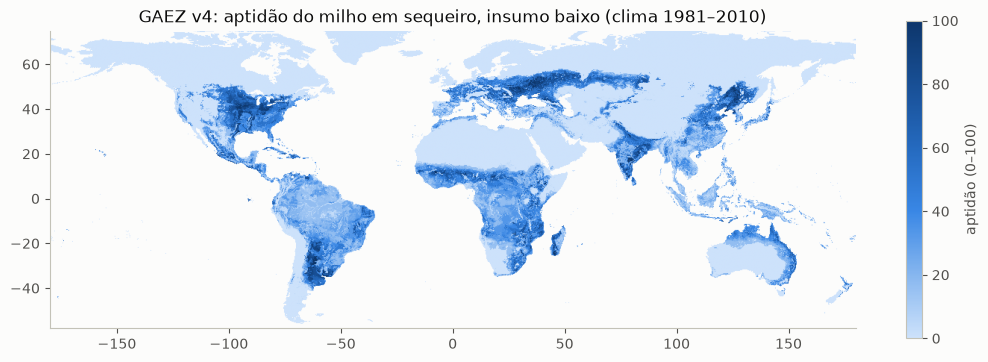

In [2]:
import rasterio
from rasterio.enums import Resampling

sel = pd.read_csv(DADOS / "gaez" / "selecao.csv")
sel = sel[(sel.servico == "res05") & sel.variavel.str.startswith("Suitability index") & sel.variavel.str.contains("all land")]
print(f"{len(sel)} camadas de aptidão (culturas × insumo), {sel.cultura_pt.nunique()} culturas:", ", ".join(sorted(sel.cultura_pt.unique())))
print("classes do motor (limite inferior exclusivo):", GZ.CLASSES, "| corte apta: >", GZ.APTA)
# cobertura global: milho, insumo baixo, lido em resolução reduzida (1/4)
with rasterio.open(DADOS / "gaez" / sel[(sel.cultura_pt == "milho") & (sel.input_level == "Low")].arquivo.iloc[0]) as src:
    g = src.read(1, out_shape=(src.height // 4, src.width // 4), resampling=Resampling.nearest).astype(float)
    print("grade original:", src.width, "×", src.height, "| resolução", round(src.res[0] * 60, 2), "arc-min | nodata", src.nodata)
terra = g >= 0
print(f"Cobertura: {terra.mean():.1%} das células com valor (terra); entre elas, {(g[terra] > GZ.APTA * 100).mean():.1%} com milho apto "
      f"(> {GZ.APTA}) no insumo baixo; {(g[terra] == 0).mean():.1%} com aptidão zero")
fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(np.where(terra, g / 100, np.nan), extent=[-180, 180, -90, 90], cmap=SEQ, vmin=0, vmax=100)
plt.colorbar(im, ax=ax, label="aptidão (0–100)", shrink=0.75)
ax.set_ylim(-58, 75)
ax.set_title("GAEZ v4: aptidão do milho em sequeiro, insumo baixo (clima 1981–2010)")
ax.grid(False)
plt.show()

In [3]:
si = GZ.aptidao(list(zip(RP.x, RP.y)))  # a mesma função (e o mesmo arredondamento) do motor e da tábua do NE
GB = pd.DataFrame({c: v for (c, i), v in si.items() if i == "Low"}, index=MUN.cod.values).astype(float)
GA = pd.DataFrame({c: v for (c, i), v in si.items() if i == "High"}, index=MUN.cod.values).astype(float)
ordem = GB.median().sort_values(ascending=False).index
# conferência: é o mesmo valor que está na tábua que o motor consulta?
GZT0 = pd.read_csv(DADOS / "gaez_zarc" / "nordeste_2026-2027.csv", dtype={"geocodigo": str})
conf = GZT0.dropna(subset=["SI baixo"]).drop_duplicates(["geocodigo", "GAEZ"])
igual = np.isclose(conf["SI baixo"].values, [GB.at[c, g_] for c, g_ in zip(conf.geocodigo, conf.GAEZ)])
print(f"Conferência com gaez_zarc/nordeste_2026-2027.csv: {igual.sum()} de {len(igual)} pares município × cultura iguais")
print(f"Aptidão no insumo baixo nos {len(GB)} municípios do NE (ponto interno de cada município):")
display(descreve(GB[ordem]))
CLS = ["não apta", "muito marginal", "marginal", "moderada", "média", "boa", "alta", "muito alta"]
classes = GB[ordem].stack().map(GZ.classe_gaez)
print("Municípios por classe oficial da v4 (insumo baixo):")
display(pd.crosstab(classes.index.get_level_values(1), classes).reindex(index=ordem, columns=CLS, fill_value=0))

Conferência com gaez_zarc/nordeste_2026-2027.csv: 19734 de 19734 pares município × cultura iguais
Aptidão no insumo baixo nos 1794 municípios do NE (ponto interno de cada município):


,n,ausentes_%,média,dp,min,5%,25%,mediana,75%,95%,max,assimetria
mandioca,1794.0,0.0,47.53,15.41,0.0,22.50,35.52,48.80,58.88,71.90,80.7,-0.15
guandu,1794.0,0.0,40.24,15.32,0.0,17.43,28.50,37.50,51.90,66.90,93.0,0.50
sorgo,1794.0,0.0,39.16,17.67,0.0,15.70,25.50,36.20,52.40,69.83,91.1,0.37
cana,1794.0,0.0,36.69,14.30,0.0,16.70,26.40,33.30,47.70,58.90,87.2,0.50
feijão (Phaseolus),1794.0,0.0,36.65,15.81,0.0,15.86,25.10,33.05,49.10,65.73,85.1,0.52
feijão-caupi,1794.0,0.0,36.46,13.41,0.0,18.26,27.40,32.90,44.78,62.77,86.7,0.91
milho,1794.0,0.0,36.73,14.89,0.0,16.70,26.70,32.60,45.00,67.63,91.0,0.92
soja,1794.0,0.0,35.57,14.05,0.0,16.70,26.32,32.10,42.10,64.90,82.1,0.87
milheto,1794.0,0.0,33.09,18.20,0.0,0.00,22.10,31.50,45.08,65.80,89.4,0.26
amendoim,1794.0,0.0,31.49,12.27,0.0,15.50,22.40,30.70,37.98,54.40,74.7,0.68


Municípios por classe oficial da v4 (insumo baixo):


col_0,não apta,muito marginal,marginal,moderada,média,boa,alta,muito alta
mandioca,2,1,140,448,569,502,132,0
guandu,2,1,261,697,505,270,45,13
sorgo,11,12,405,554,451,275,72,14
cana,2,20,369,737,468,161,31,6
feijão (Phaseolus),2,6,438,683,406,213,45,1
feijão-caupi,2,0,288,929,399,136,39,1
milho,3,8,335,901,312,169,60,6
soja,2,6,368,935,258,191,34,0
milheto,131,46,398,684,276,218,38,3
amendoim,2,15,557,857,286,65,12,0


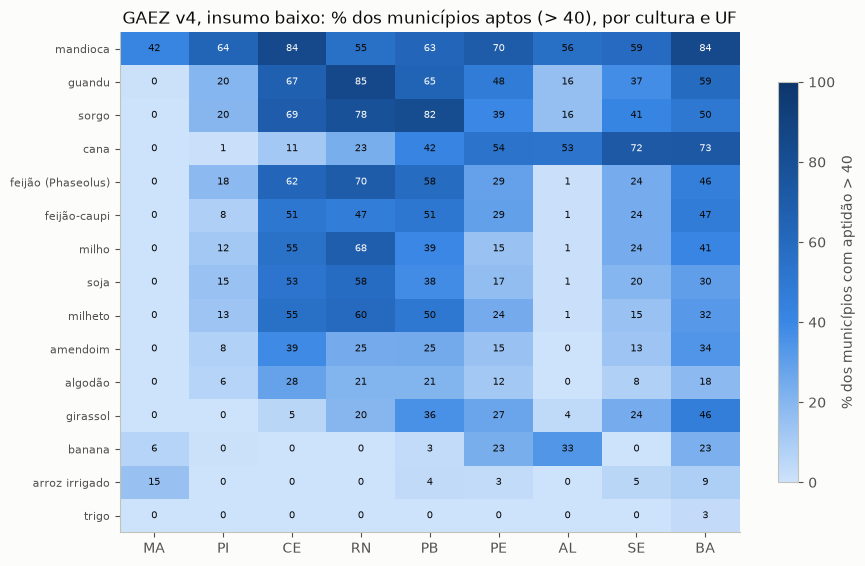

Mediana da aptidão (insumo baixo) por UF, culturas do cardápio:


,feijão-caupi,milho,feijão (Phaseolus),mandioca,amendoim,sorgo,guandu,milheto,algodão,girassol
MA,25.3,25.0,16.7,40.0,16.7,16.7,26.1,11.8,23.7,0.0
PI,29.6,28.6,29.6,44.9,28.4,29.6,30.2,27.8,26.2,0.0
CE,40.2,41.3,48.6,52.8,36.5,53.7,53.2,41.7,33.8,0.0
RN,38.4,48.5,46.9,42.6,33.5,51.3,49.1,46.8,33.3,0.0
PB,41.6,38.4,44.8,47.9,35.7,49.8,48.1,40.2,33.4,31.2
PE,30.5,28.9,30.6,55.6,27.5,35.6,34.1,28.8,29.4,28.7
AL,27.6,28.1,25.7,50.6,22.4,28.4,29.6,24.6,26.4,28.4
SE,32.7,32.6,32.6,40.8,29.4,33.8,33.3,28.5,27.8,32.8
BA,37.8,35.3,36.2,57.3,33.3,39.8,45.0,33.3,32.6,36.0


In [4]:
apta_uf = (GB[ordem] > GZ.APTA).groupby(MUN.uf.values).mean().reindex(UF_ORDEM).T * 100
fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(apta_uf.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(UF_ORDEM)))
ax.set_xticklabels(UF_ORDEM)
ax.set_yticks(range(len(ordem)))
ax.set_yticklabels(ordem, fontsize=8)
for i in range(apta_uf.shape[0]):
    for j in range(apta_uf.shape[1]):
        v = apta_uf.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="#fcfcfb" if v > 60 else "#0b0b0b")
ax.grid(False)
plt.colorbar(im, ax=ax, label="% dos municípios com aptidão > 40", shrink=0.8)
ax.set_title("GAEZ v4, insumo baixo: % dos municípios aptos (> 40), por cultura e UF")
plt.show()
print("Mediana da aptidão (insumo baixo) por UF, culturas do cardápio:")
cardapio_g = ["feijão-caupi", "milho", "feijão (Phaseolus)", "mandioca", "amendoim", "sorgo", "guandu", "milheto", "algodão", "girassol"]
display(GB[cardapio_g].groupby(MUN.uf.values).median().reindex(UF_ORDEM).round(1))

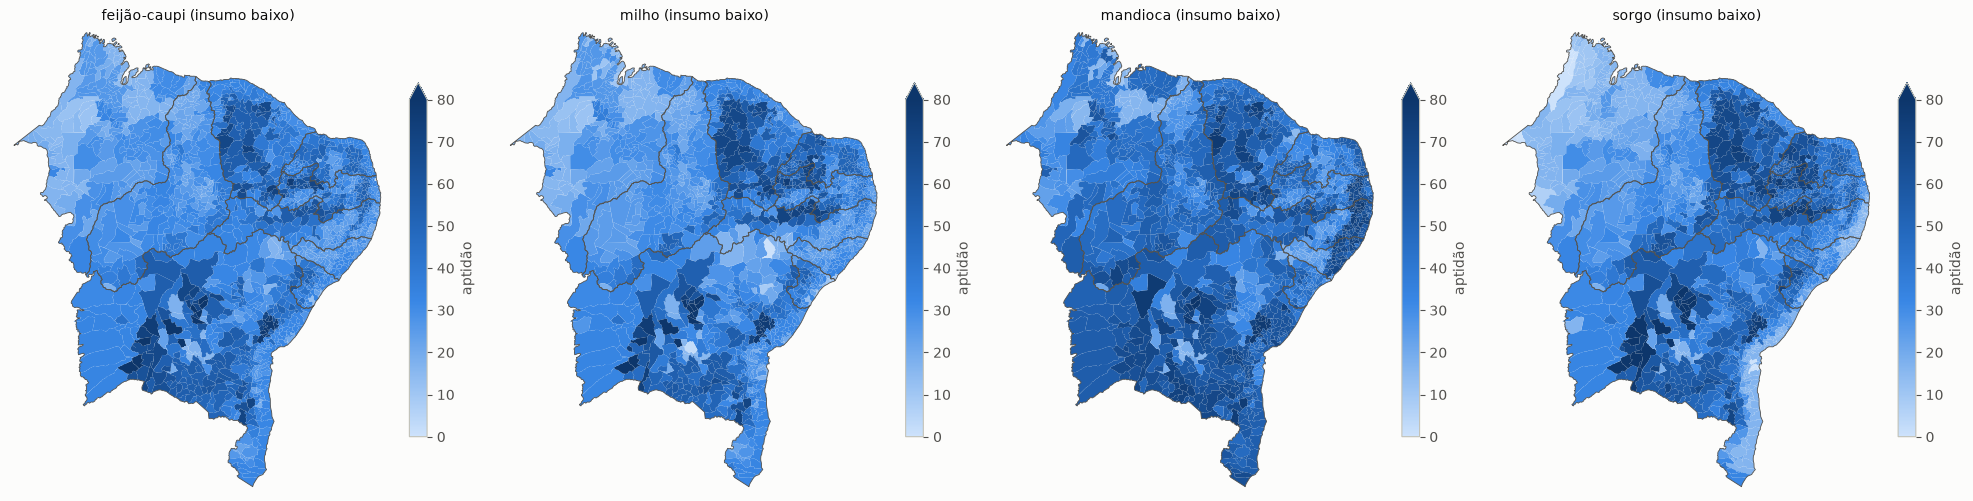

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(20, 6.2))
for ax, c in zip(axs, ["feijão-caupi", "milho", "mandioca", "sorgo"]):
    mapa_ne(ax, GB[c], f"{c} (insumo baixo)", vmin=0, vmax=80, rotulo="aptidão")
plt.tight_layout()
plt.show()

Insumo alto − insumo baixo (mediana dos municípios): cana -17.9; banana -10.0; mandioca -2.6; arroz irrigado +0.0; trigo +0.0; milheto +1.9; milho +6.2; sorgo +6.4; guandu +8.8; amendoim +9.6; feijão (Phaseolus) +10.1; soja +10.3; feijão-caupi +13.0; algodão +14.8; girassol +22.9


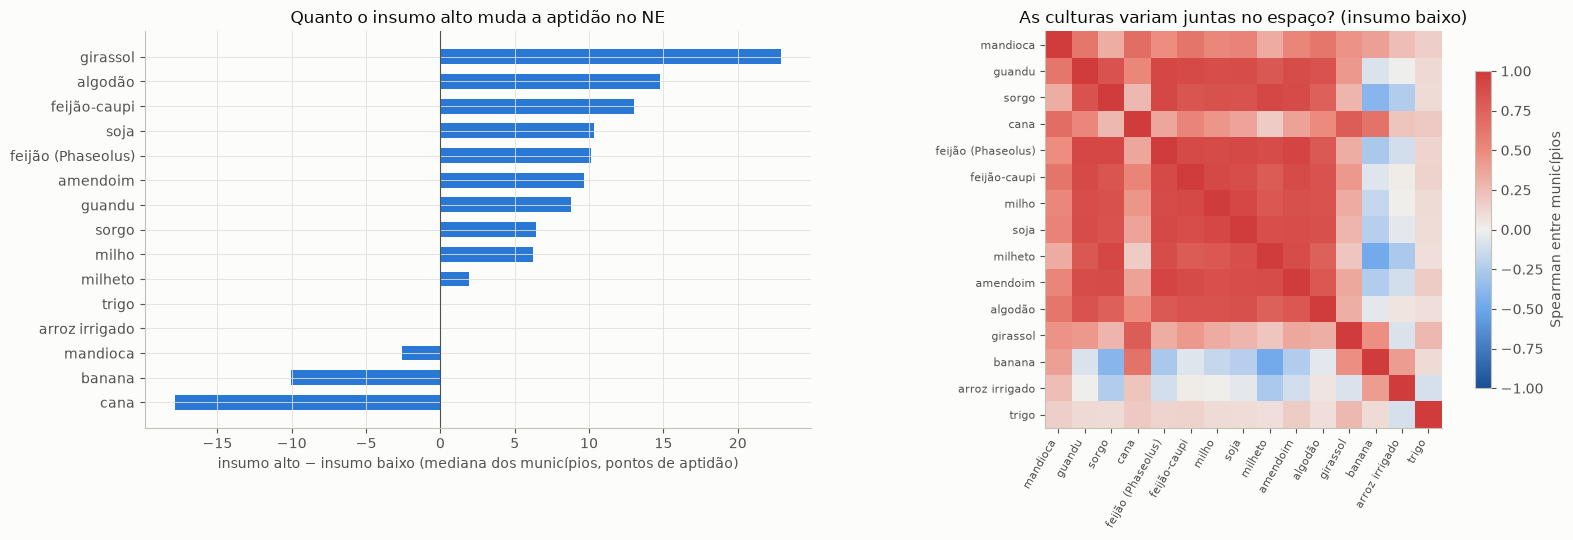

Spearman entre pares de culturas: mediana +0.43; faixa -0.48 a +0.94
Municípios onde milho, caupi e sorgo ficam todos ≤ 40 no insumo baixo: 953 de 1794


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
municípios,217,179,56,37,39,107,86,44,188


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
ganho = (GA[ordem] - GB[ordem]).median().sort_values()
axs[0].barh(ganho.index, ganho.values, color=CAT[0], height=0.6)
axs[0].axvline(0, color="#52514e", lw=0.8)
axs[0].set_xlabel("insumo alto − insumo baixo (mediana dos municípios, pontos de aptidão)")
axs[0].set_title("Quanto o insumo alto muda a aptidão no NE")
print("Insumo alto − insumo baixo (mediana dos municípios):", "; ".join(f"{k} {v:+.1f}" for k, v in ganho.items()))
cor = GB[ordem].corr("spearman")
im = axs[1].imshow(cor.values, cmap=DIV, vmin=-1, vmax=1)
axs[1].set_xticks(range(len(ordem)))
axs[1].set_xticklabels(ordem, rotation=60, ha="right", fontsize=8)
axs[1].set_yticks(range(len(ordem)))
axs[1].set_yticklabels(ordem, fontsize=8)
axs[1].grid(False)
plt.colorbar(im, ax=axs[1], label="Spearman entre municípios", shrink=0.8)
axs[1].set_title("As culturas variam juntas no espaço? (insumo baixo)")
plt.tight_layout()
plt.show()
pares_cor = cor.where(np.triu(np.ones(cor.shape, bool), 1)).stack()
print(f"Spearman entre pares de culturas: mediana {pares_cor.median():+.2f}; faixa {pares_cor.min():+.2f} a {pares_cor.max():+.2f}")
baixos = MUN.set_index("cod").loc[GB.index[(GB[["milho", "feijão-caupi", "sorgo"]] <= GZ.APTA).all(1)]]
print(f"Municípios onde milho, caupi e sorgo ficam todos ≤ {GZ.APTA} no insumo baixo: {len(baixos)} de {len(GB)}")
display(baixos.uf.value_counts().reindex(UF_ORDEM, fill_value=0).rename("municípios").to_frame().T)

**Leitura:**
- **Cobertura global confirmada:** 24,4% das células da grade têm valor (a terra do planeta). Entre elas, o milho com
  pouco insumo é apto (> 40) em 12,7% e tem aptidão zero em 60,0%. A camada responde "o que cabe" em qualquer lugar.
- **A amostra é a mesma do motor:** os 19.734 pares município × cultura batem com a tábua `nordeste_2026-2027.csv`.
- **No NE, com pouco insumo, a mais apta é a mandioca** (mediana de 48,8). Depois vêm guandu (37,5) e sorgo (36,2).
  Feijão comum, caupi e milho ficam perto de 33; amendoim e algodão, perto de 30. O girassol tem aptidão zero em 743
  municípios.
- **Pelas classes oficiais da v4, a classe mais comum é "moderada" (> 25 a 40)** em 11 das 15 culturas. Passam do corte
  (> 40): mandioca em 1.203 municípios, guandu em 833, sorgo em 812, feijão comum em 665, caupi em 575, milho em 547 e
  milheto em 535.
- **A UF muda tudo.**
  - CE, RN e PB têm as maiores medianas de sorgo (49,8 a 53,7), milho (38,4 a 48,5) e feijão comum (44,8 a 48,6).
  - O MA tem as menores: milho 25,0, sorgo 16,7 e girassol 0.
  - A mandioca é a mais apta em 6 das 9 UFs; no CE, no RN e na PB, é o sorgo.
- **Em 953 municípios (53%), milho, caupi e sorgo ficam todos ≤ 40:** os 217 do MA, 188 da BA, 179 do PI, 107 de PE e
  86 de AL. No CE são 56.
- **As culturas sobem e descem juntas no espaço** (Spearman mediano de +0,43 entre pares; de −0,48 a +0,94). Quem
  manda é o solo e o relevo da célula, não a cultura.
- **O insumo alto muda pouco a maioria** (milho +6,2; sorgo +6,4; caupi +13,0), mas muda o **girassol (+22,9)** e o
  **algodão (+14,8)**. A cana (−17,9), a banana (−10,0) e a mandioca (−2,6) pioram. O protótipo mostra o insumo alto só
  como rótulo (revisão M2).
- **No produto:** o GAEZ responde "o que cabe" no mundo, mas é grosseiro no município. No NE, ele só decide onde a
  cultura não tem ZARC (seção 3).

## 2. ZARC (MAPA): quando plantar e com que risco

**Ficha técnica**
- **O que é:** a tábua de risco do Zoneamento Agrícola de Risco Climático, nos dados abertos do MAPA, filtrada para as 9
  UFs do Nordeste (`complementares/zarc_ne/tabua_risco_ne_<safra>.csv`, `;` como separador).
  - 2026/27: **uma portaria por cultura e por estado**, de abril a agosto de 2026 nas 9 culturas do cardápio (contagem abaixo).
  - 2025/26: usada para comparar.
- **Unidade:** município × cultura × manejo × solo × ciclo. Para cada um dos 36 decêndios do ano, o valor é o risco de
  perda (20, 30 ou 40%) ou 0 (não indicado).
  - Solo: 1 arenoso, 2 médio, 3 argiloso; 11–16 = classes de água disponível AD1–AD6.
  - Ciclo: Grupos I–IV (Cod_Ciclo 20, 21, 22, 24).
- **Critério:** a cultura tem água suficiente na fase crítica em pelo menos 80% dos anos (linha de Campos et al. 2010).

**Filtros que o motor aplica** (os mesmos aqui):
- só sequeiro e só as 9 culturas do cardápio com ZARC;
- **só os grupos de ciclo com cultivar indicada na portaria** (`gaez_zarc_municipio.CICLOS_COM_CULTIVAR`, revisão C3):
  caupi e sorgo forrageiro no Grupo I, mamona nos Grupos II–IV. **Isso só foi conferido nas portarias do CE**; nos outros
  8 estados entram todos os grupos da tábua, e o cartão avisa;
- **só a mamona tradicional** (`CLIMA_POR_CULTURA`, revisão M5): a de "Clima Semiárido" (baixa produtividade,
  Port. 143/2026, item 1.13) fica fora.

**ZARC plurianual do CE** (revisão A1): mandioca (Port. 11/2020), milheto (Port. 330/2020) e palma (Port. 284/2019) têm
portarias sem ano-safra, fora da tábua aberta. O motor lê uma tábua complementar extraída dos PDFs
(`complementares/zarc_plurianual_ce/`; vigência pela página do MAPA de 05/11/2026, SISZARC não conferido). Nos outros
8 estados, essas culturas seguem sem ZARC no protótipo.

**No protótipo:**
- a janela com risco de 20%, até 30% e até 40% de cada cultura: a união dos solos e ciclos e, desde 14/11, a janela em
  cada tipo de solo (revisão A7); a janela termina no último dia do decêndio (revisão M4);
- duas datas (revisão A6): o 1º decêndio com alguma cultura do cardápio zoneada (até 40%) e o 1º com risco de 20%. O
  motor procura a partir de **3 meses antes do início da estação do município** (seção 7);
- **onde a cultura tem ZARC no município, o ZARC decide** (seção 3).

In [7]:
from gaez_zarc_municipio import data_dec

D = GZ.D
MENU_Z = M.ZARC_MENU
SAFRAS = ["2025-2026", "2026-2027"]
Z = {s: pd.read_csv(DADOS / "complementares" / "zarc_ne" / f"tabua_risco_ne_{s}.csv", sep=";") for s in SAFRAS}
Z26 = Z["2026-2027"]
print(f"ZARC 2026/27 (NE): {len(Z26):,} linhas; {Z26.geocodigo.nunique()} municípios; {Z26.Nome_cultura.nunique()} culturas; "
      f"{Z26.Portaria.nunique()} portarias; manejos: {Z26.Nome_Outros_Manejos.value_counts().to_dict()}")
display(Z26.groupby("UF").agg(linhas=("geocodigo", "size"), municipios=("geocodigo", "nunique"), culturas=("Nome_cultura", "nunique"),
                              portarias=("Portaria", "nunique")).reindex(UF_ORDEM).T)
men = Z26[(Z26.Nome_Outros_Manejos == "Sequeiro") & Z26.Nome_cultura.isin(MENU_Z)]
PxU = men.groupby(["Nome_cultura", "UF"]).Portaria.nunique().unstack().reindex(index=MENU_Z, columns=UF_ORDEM)
num = men.groupby(["Nome_cultura", "UF"]).Portaria.first().str.extract(r"Port\.(\d+)_de_(\S+)")
print(f"Cultura do cardápio × UF com exatamente uma portaria: {int((PxU == 1).sum().sum())} de {PxU.size}; "
      f"{men.Portaria.nunique()} portarias distintas para as 9 culturas. Número da portaria (data em cada linha):")
tab = num[0].unstack().reindex(index=MENU_Z, columns=UF_ORDEM)
tab["data"] = num[1].groupby(level=0).agg(lambda s: ", ".join(sorted(set(s)))).reindex(MENU_Z)
display(tab)
est = men.groupby("Nome_cultura").agg(municipios=("geocodigo", "nunique"), linhas=("geocodigo", "size"),
                                      solos=("Cod_Solo", lambda s: ",".join(map(str, sorted(s.unique())))),
                                      ciclos=("Cod_Ciclo", lambda s: ",".join(map(str, sorted(s.unique())))),
                                      climas=("Nome_Clima", lambda s: " | ".join(sorted(s.unique())))).reindex(MENU_Z)
display(est)

ZARC 2026/27 (NE): 240,949 linhas; 1794 municípios; 17 culturas; 113 portarias; manejos: {'Sequeiro': 219531, 'Irrigado': 21418}


UF,MA,PI,CE,RN,PB,PE,AL,SE,BA
linhas,39296,36830,23967,18863,26804,23256,15920,10651,45362
municipios,217,224,184,167,223,185,102,75,417
culturas,17,17,13,13,13,13,14,13,15
portarias,16,16,11,11,11,11,12,11,14


Cultura do cardápio × UF com exatamente uma portaria: 81 de 81; 81 portarias distintas para as 9 culturas. Número da portaria (data em cada linha):


UF,MA,PI,CE,RN,PB,PE,AL,SE,BA,data
Nome_cultura,,,,,,,,,,
Feijão Caupi,125,132,121,133,130,131,117,136,120,26-05-2026
Milho 1ª Safra,222,229,218,232,227,228,214,237,217,10-07-2026
Feijão 2ª Safra,358,365,354,368,363,364,352,372,353,24-08-2026
Amendoim,77,84,73,87,82,83,69,92,72,17-04-2026
Sorgo Granífero,274,281,270,284,279,280,266,289,269,22-07-2026
Sorgo Forrageiro,301,308,297,311,306,307,293,316,296,23-07-2026
Algodão Herbáceo,173,180,169,183,178,179,166,188,168,03-06-2026
Mamona,147,154,143,157,152,153,139,162,142,28-05-2026
Girassol,101,107,97,110,105,106,95,113,96,07-05-2026


,municipios,linhas,solos,ciclos,climas
Nome_cultura,,,,,
Feijão Caupi,1728,14756,"1,2,3","20,21,22",Não se aplica
Milho 1ª Safra,1524,21080,"11,12,13,14,15,16","20,21,22",Não se aplica
Feijão 2ª Safra,1640,12287,"11,12,13,14,15,16","20,21",Não se aplica
Amendoim,1794,16146,"1,2,3","20,21,22",Não se aplica
Sorgo Granífero,1698,14625,"1,2,3","20,21,22",Não se aplica
Sorgo Forrageiro,1633,13670,"1,2,3","20,21,22",Não se aplica
Algodão Herbáceo,1660,12901,"1,2,3","20,21,22",Não se aplica
Mamona,1794,25247,"1,2,3","20,21,22,24",Não se aplica | Semiárido
Girassol,1163,11146,"11,12,13,14,15,16","20,21",Não se aplica


In [8]:
def mascaras(z):
    """Ciclos com cultivar (conferidos só no CE) e mamona tradicional: True = a linha fica."""
    ciclo = pd.Series(True, index=z.index)
    for (uf, cult), ciclos in GZ.CICLOS_COM_CULTIVAR.items():
        s_ = (z.UF == uf) & (z.Nome_cultura == cult)
        ciclo &= ~s_ | z.Cod_Ciclo.isin(ciclos)
    clima = pd.Series(True, index=z.index)
    for cult, cl in GZ.CLIMA_POR_CULTURA.items():
        clima &= (z.Nome_cultura != cult) | (z.Nome_Clima == cl)
    return ciclo, clima


def filtra(z):
    """Os filtros do motor: sequeiro, cultura do cardápio, ciclos com cultivar, mamona tradicional."""
    z = z[(z.Nome_Outros_Manejos == "Sequeiro") & z.Nome_cultura.isin(MENU_Z)]
    ciclo, clima = mascaras(z)
    return z[ciclo & clima]


seq = filtra(Z26)
ciclo, clima = mascaras(men)
print(f"Linhas de sequeiro das 9 culturas: {len(men):,}; depois dos filtros: {len(seq):,}. Saem {int((~ciclo).sum()):,} linhas do CE "
      f"(grupos de ciclo sem cultivar) e {int((~clima).sum()):,} da mamona de clima semiárido "
      f"(em {men[~clima].geocodigo.nunique()} municípios).")
print("Grupos de ciclo na tábua, por cultura, fora do CE (sem conferência de cultivar):")
display(men[men.UF != "CE"].groupby("Nome_cultura").Cod_Ciclo.apply(lambda s: ",".join(map(str, sorted(s.unique())))).reindex(MENU_Z).to_frame("ciclos").T)
q = men[(men.geocodigo == 2311306) & (men.Nome_cultura == "Feijão Caupi")]
qf = seq[(seq.geocodigo == 2311306) & (seq.Nome_cultura == "Feijão Caupi")]
jan = lambda t: GZ.janelas([i + 1 for i, c in enumerate(D) if (t[c] == 20).any()])  # noqa: E731
print(f"Exemplo (caupi em Quixadá, risco de 20%): todos os grupos {jan(q)}; só os grupos com cultivar (Grupo I) {jan(qf)}")
v = seq[D].stack()
print("Distribuição dos valores (linhas filtradas × 36 decêndios):")
display((v.value_counts(normalize=True) * 100).round(1).rename("% das células").to_frame().T)

Linhas de sequeiro das 9 culturas: 141,858; depois dos filtros: 130,277. Saem 3,027 linhas do CE (grupos de ciclo sem cultivar) e 8,821 da mamona de clima semiárido (em 761 municípios).
Grupos de ciclo na tábua, por cultura, fora do CE (sem conferência de cultivar):


Nome_cultura,Feijão Caupi,Milho 1ª Safra,Feijão 2ª Safra,Amendoim,Sorgo Granífero,Sorgo Forrageiro,Algodão Herbáceo,Mamona,Girassol
ciclos,"20,21,22","20,21,22","20,21","20,21,22","20,21,22","20,21,22","20,21,22","20,21,22,24","20,21"


Exemplo (caupi em Quixadá, risco de 20%): todos os grupos 21/02–20/04; só os grupos com cultivar (Grupo I) 11/03–20/04


Distribuição dos valores (linhas filtradas × 36 decêndios):


,0,20,30,40
% das células,79.5,9.9,5.4,5.2


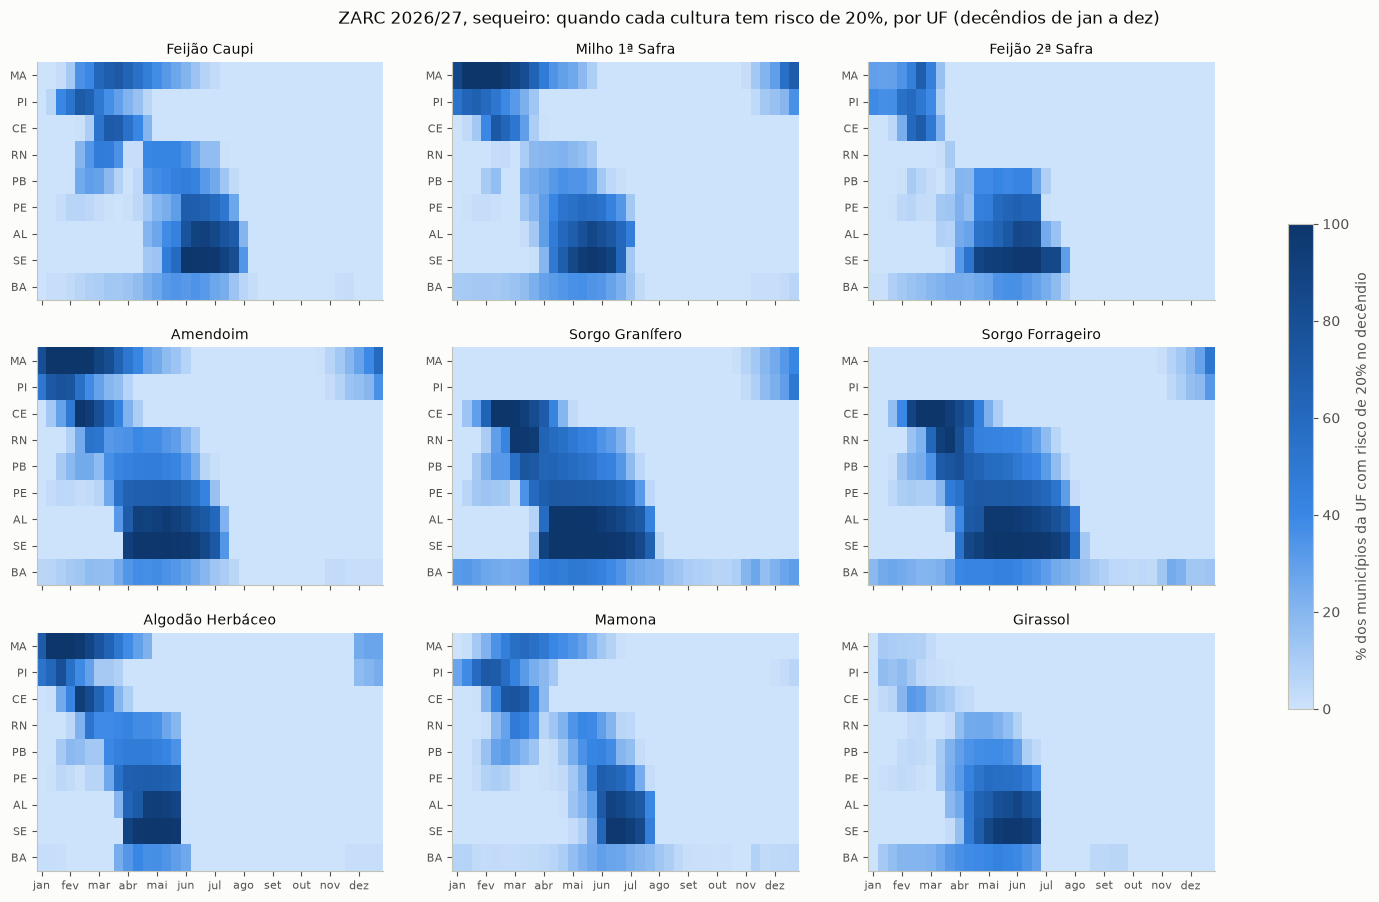

In [9]:
# janela por cultura e UF: % dos municípios da UF com risco de 20% em alguma combinação solo × ciclo, em cada decêndio
r20m = (seq[D] == 20).groupby([seq.Nome_cultura, seq.geocodigo.astype(str)]).any()
cods = MUN.cod.values
fig, axs = plt.subplots(3, 3, figsize=(19, 10.5), sharex=True)
for ax, c in zip(axs.ravel(), MENU_Z):
    m_ = r20m.loc[c].reindex(cods, fill_value=False)
    H = m_.groupby(UFMUN.reindex(m_.index).values).mean().reindex(UF_ORDEM) * 100
    im = ax.imshow(H.values, aspect="auto", cmap=SEQ, vmin=0, vmax=100)
    ax.set_yticks(range(9))
    ax.set_yticklabels(UF_ORDEM, fontsize=8)
    ax.set_xticks(range(0, 36, 3))
    ax.set_xticklabels(M.MESES, fontsize=8)
    ax.grid(False)
    ax.set_title(c, fontsize=10)
fig.colorbar(im, ax=axs, shrink=0.6, label="% dos municípios da UF com risco de 20% no decêndio")
fig.suptitle("ZARC 2026/27, sequeiro: quando cada cultura tem risco de 20%, por UF (decêndios de jan a dez)", y=0.93)
plt.show()

In [10]:
# comprimento da janela de 20%: união dos solos e ciclos (o que a página mostra) e a melhor combinação solo × ciclo
U = r20m.sum(1).rename("n20_uniao")
B = seq.assign(n20=(seq[D] == 20).sum(1)).groupby([seq.Nome_cultura, seq.geocodigo.astype(str)]).n20.max().rename("n20_melhor")
JJ = pd.concat([U, B], axis=1).reset_index().rename(columns={"level_1": "cod", "geocodigo": "cod"})
JJ["uf"] = JJ.cod.map(UFMUN)
res = JJ.groupby("Nome_cultura").agg(municipios_com_zarc=("cod", "size"), n20_uniao_mediana=("n20_uniao", "median"),
                                     n20_melhor_mediana=("n20_melhor", "median"),
                                     sem_20_pct=("n20_uniao", lambda s: round((s == 0).mean() * 100, 1))).reindex(MENU_Z)
print("Decêndios com risco de 20% por município (só municípios com ZARC da cultura):")
display(res)
print("Mediana de decêndios com risco de 20% (união de solos e ciclos), por cultura e UF:")
display(JJ.pivot_table(index="Nome_cultura", columns="uf", values="n20_uniao", aggfunc="median").reindex(index=MENU_Z, columns=UF_ORDEM))

Decêndios com risco de 20% por município (só municípios com ZARC da cultura):


,municipios_com_zarc,n20_uniao_mediana,n20_melhor_mediana,sem_20_pct
Nome_cultura,,,,
Feijão Caupi,1728,5.0,4.0,15.6
Milho 1ª Safra,1524,5.0,5.0,24.3
Feijão 2ª Safra,1640,3.0,3.0,34.2
Amendoim,1794,6.0,6.0,24.0
Sorgo Granífero,1698,7.0,7.0,17.0
Sorgo Forrageiro,1633,7.0,7.0,17.2
Algodão Herbáceo,1660,6.0,6.0,18.4
Mamona,1783,5.0,5.0,12.9
Girassol,1163,4.0,4.0,31.8


Mediana de decêndios com risco de 20% (união de solos e ciclos), por cultura e UF:


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
Nome_cultura,,,,,,,,,
Feijão Caupi,6.0,4.0,3.0,5.0,5.0,6.0,6.0,7.0,4.0
Milho 1ª Safra,12.0,6.0,3.0,0.0,2.0,6.0,8.0,7.0,7.0
Feijão 2ª Safra,2.0,3.0,3.0,0.0,2.0,7.0,7.0,10.0,4.0
Amendoim,11.0,6.0,5.0,3.0,4.0,9.0,10.0,10.0,0.0
Sorgo Granífero,0.0,1.0,7.0,7.0,8.0,11.0,11.0,12.0,8.0
Sorgo Forrageiro,1.0,1.0,8.0,7.0,8.0,11.0,11.5,13.0,6.0
Algodão Herbáceo,9.0,4.0,4.0,2.0,3.0,7.0,6.0,6.0,4.5
Mamona,5.0,5.0,4.0,5.0,5.0,5.0,5.0,5.0,5.0
Girassol,0.5,1.0,2.0,2.0,4.0,6.0,7.5,7.0,7.0


In [11]:
# janela por solo (revisão A7): o cartão mostra a janela em cada tipo de solo zoneado (motor.janelas_por_solo)
print(f"Conferência: a tábua filtrada do motor (motor.ZSEQ) tem {len(M.ZSEQ):,} linhas; a desta seção, {len(seq):,}")
ps = seq.assign(cod=seq.geocodigo.astype(str))
n_solo = (ps[D] == 20).groupby([ps.Nome_cultura, ps.cod, ps.Cod_Solo]).any().sum(1)  # decêndios com 20% em cada solo (união dos ciclos)
amp = n_solo.groupby(level=[0, 1]).agg(["min", "max", "size"])
amp["difere"] = amp["max"] > amp["min"]
amp["so_no_melhor"] = (amp["min"] == 0) & (amp["max"] > 0)
print("Por município: decêndios com risco de 20% no solo mais restritivo e no mais permissivo (medianas) e % dos municípios em que o solo muda a janela:")
display(amp.groupby(level=0).agg(solos=("size", "median"), solo_mais_restritivo=("min", "median"), solo_mais_permissivo=("max", "median"),
                                 pct_janela_muda_com_solo=("difere", lambda s: round(s.mean() * 100, 1)),
                                 pct_20_so_em_parte_dos_solos=("so_no_melhor", lambda s: round(s.mean() * 100, 1))).reindex(MENU_Z))
print("Exemplo (motor.janelas_por_solo, milho em Quixadá):")
display(pd.DataFrame(M.janelas_por_solo("2311306", "Milho 1ª Safra")).set_index("solo"))

Conferência: a tábua filtrada do motor (motor.ZSEQ) tem 130,277 linhas; a desta seção, 130,277
Por município: decêndios com risco de 20% no solo mais restritivo e no mais permissivo (medianas) e % dos municípios em que o solo muda a janela:


,solos,solo_mais_restritivo,solo_mais_permissivo,pct_janela_muda_com_solo,pct_20_so_em_parte_dos_solos
Nome_cultura,,,,,
Feijão Caupi,3.0,3.0,5.0,84.0,23.6
Milho 1ª Safra,6.0,0.0,5.0,75.7,37.9
Feijão 2ª Safra,4.0,0.0,3.0,65.8,62.1
Amendoim,3.0,4.0,6.0,75.7,10.0
Sorgo Granífero,3.0,3.0,7.0,81.1,15.9
Sorgo Forrageiro,3.0,3.0,7.0,79.5,19.5
Algodão Herbáceo,3.0,3.0,6.0,67.7,20.4
Mamona,3.0,3.0,5.0,86.9,21.6
Girassol,6.0,0.0,4.0,67.8,36.7


Exemplo (motor.janelas_por_solo, milho em Quixadá):


,cod_solo,risco20,risco30,risco40
solo,,,,
AD2,12,nenhum,nenhum,21/02–28/02
AD3,13,nenhum,nenhum,11/02–10/03
AD4,14,nenhum,21/02–28/02,11/02–10/03
AD5,15,nenhum,11/02–10/03,11/02–20/03
AD6,16,nenhum,11/02–10/03,11/02–31/03


Tábua complementar do CE: 2,757 linhas; 184 municípios; manejos ['Sequeiro']


,portaria,municípios na portaria,solos,ciclos,decêndios com 20% (mediana),indicada,com risco,fora da portaria
cultura,,,,,,,,
Mandioca,Port.11_de_12-02-2020,184,"1,2,3",20,4.0,184,0.0,0.0
Milheto,Port.330_de_23-10-2020,184,"1,2,3","20,21,22",9.0,184,0.0,0.0
Palma forrageira,Port.284_de_07-10-2019,183,"1,2,3",20,8.0,180,3.0,1.0


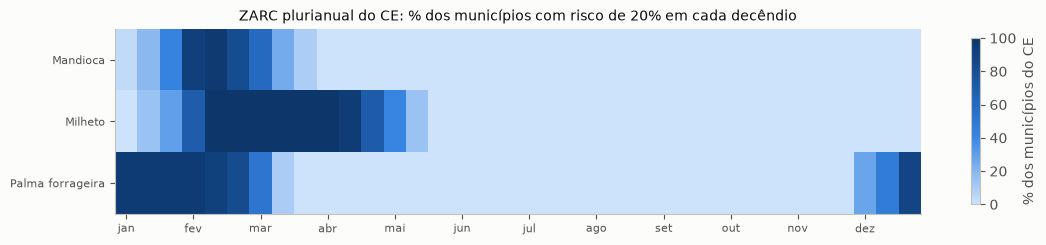

Com as plurianuais nas duas datas da página, mudariam no CE: o 1º decêndio zoneado em 183 municípios e o 1º com 20% em 180 (de 184). Hoje o motor calcula as datas só com a tábua aberta.


In [12]:
# ZARC plurianual do CE (revisão A1): mandioca, milheto e palma têm portaria plurianual, fora da tábua aberta.
# O motor lê uma tábua complementar extraída dos PDFs (motor.PLUR) e a usa no cardápio do CE (motor.zarc_plurianual).
PL = M.PLUR
print(f"Tábua complementar do CE: {len(PL):,} linhas; {PL.geocodigo.nunique()} municípios; manejos {sorted(PL.Nome_Outros_Manejos.unique())}")
plr, H3, SIT_PLUR = [], {}, {}
for nome_m, nome_t in M.PLUR_NOME.items():
    q_ = PL[PL.Nome_cultura == nome_t]
    u_ = (q_[D] == 20).groupby(q_.geocodigo).any()
    H3[nome_m] = u_.reindex(MUN.cod[MUN.uf == "CE"], fill_value=False).mean() * 100
    # a regra de motor.zarc_plurianual: 20% em algum decêndio = indicada; só 30–40% = com risco; sem linha = fora da portaria
    z40_ = (q_[D] > 0).groupby(q_.geocodigo).any().any(axis=1)
    sit_ = pd.Series("fora da portaria", index=MUN.cod[MUN.uf == "CE"].values)
    sit_[z40_.index] = np.where(u_.any(axis=1).reindex(z40_.index), "indicada", np.where(z40_, "com risco", "fora"))
    SIT_PLUR[nome_m] = sit_
    plr.append({"cultura": nome_m, "portaria": q_.Portaria.iloc[0], "municípios na portaria": q_.geocodigo.nunique(),
                "solos": ",".join(map(str, sorted(q_.Cod_Solo.unique()))), "ciclos": ",".join(map(str, sorted(q_.Cod_Ciclo.unique()))),
                "decêndios com 20% (mediana)": u_.sum(1).median()} | sit_.value_counts().to_dict())
display(pd.DataFrame(plr).set_index("cultura").fillna(0))
H3 = pd.DataFrame(H3).T
fig, ax = plt.subplots(figsize=(13, 2.4))
im = ax.imshow(H3.values, aspect="auto", cmap=SEQ, vmin=0, vmax=100)
ax.set_yticks(range(len(H3)))
ax.set_yticklabels(H3.index, fontsize=8)
ax.set_xticks(range(0, 36, 3))
ax.set_xticklabels(M.MESES, fontsize=8)
ax.grid(False)
plt.colorbar(im, ax=ax, label="% dos municípios do CE", shrink=0.9)
ax.set_title("ZARC plurianual do CE: % dos municípios com risco de 20% em cada decêndio", fontsize=10)
plt.show()
# as duas datas da página (motor.ZPRIM) usam só a tábua aberta: mudariam com as plurianuais?
Zce = pd.concat([M.ZSEQ.reset_index()[lambda d: d.UF == "CE"], PL.assign(geocodigo=PL.geocodigo.astype(str))], ignore_index=True)
z40, z20 = (Zce[D] > 0).groupby(Zce.geocodigo).any(), (Zce[D] == 20).groupby(Zce.geocodigo).any()
muda40 = muda20 = 0
for cod in z40.index:
    ini = ((int(M.REG.mes_inicio_estacao.get(cod, 2)) - 4) % 12) * 3
    ordem = [(ini + k) % 36 for k in range(36)]
    p40 = next((k + 1 for k in ordem if z40.loc[cod].values[k]), None)
    p20 = next((k + 1 for k in ordem if z20.loc[cod].values[k]), None)
    muda40 += (GZ.data_dec(p40) if p40 else None) != M.ZPRIM[cod]["ate40"]
    muda20 += (GZ.data_dec(p20) if p20 else None) != M.ZPRIM[cod]["risco20"]
print(f"Com as plurianuais nas duas datas da página, mudariam no CE: o 1º decêndio zoneado em {muda40} municípios e o 1º com "
      f"20% em {muda20} (de {len(z40)}). Hoje o motor calcula as datas só com a tábua aberta.")

Municípios com alguma linha de ZARC do cardápio: 1794 de 1794; sem nada zoneado: 1; sem nenhum decêndio com risco de 20%: 136


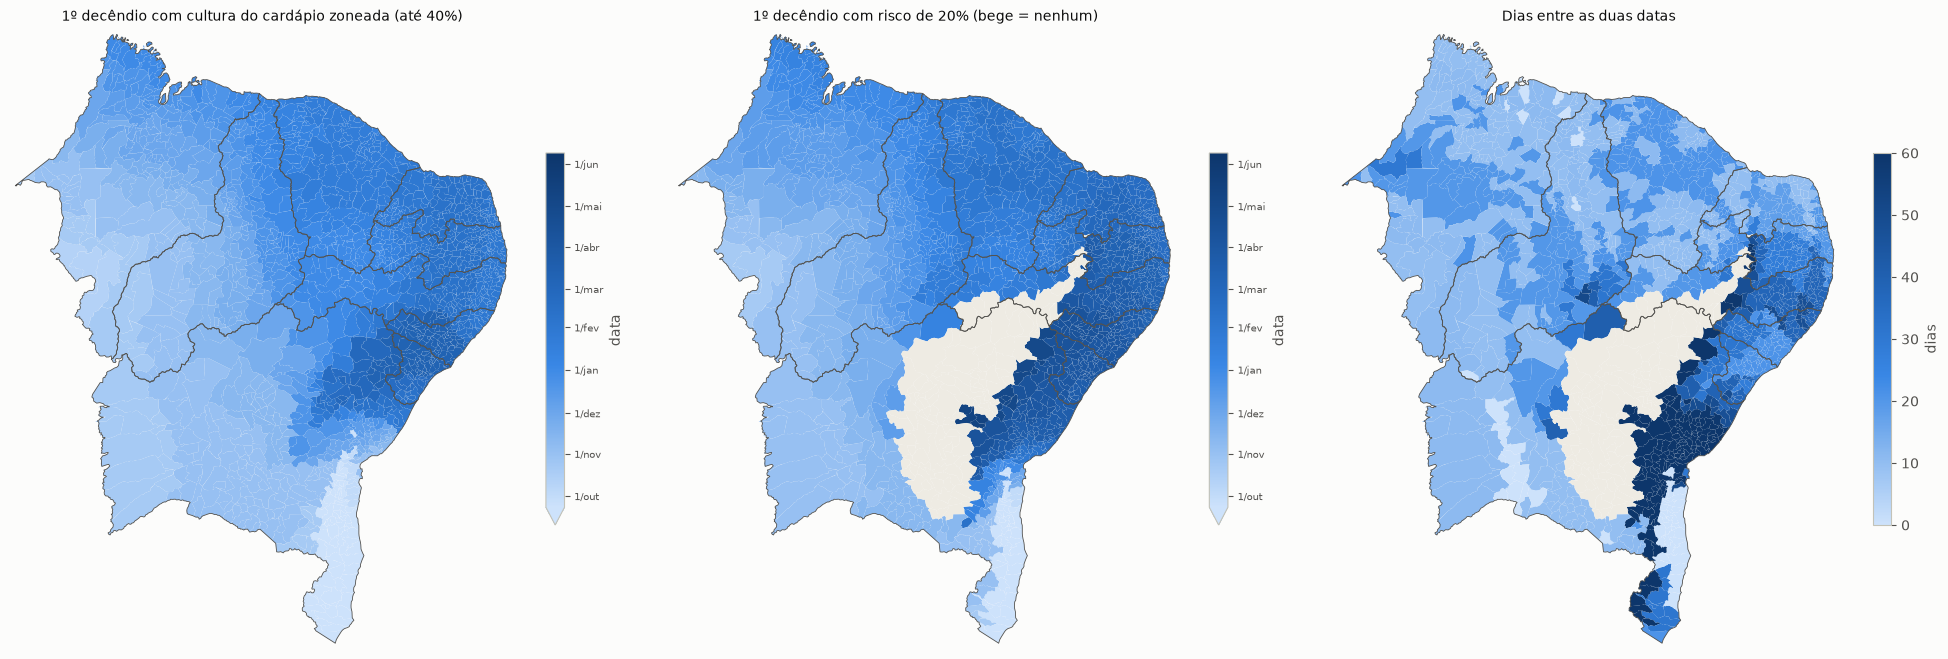

Municípios pelo mês do 1º decêndio com risco de 20%, por UF:


risco20,jul,ago,out,nov,dez,jan,fev,mar,abr,mai
uf,,,,,,,,,,
MA,0,0,3,43,104,67,0,0,0,0
PI,0,0,0,39,77,105,3,0,0,0
CE,0,0,0,0,0,54,130,0,0,0
RN,0,0,0,0,0,0,115,51,0,0
PB,0,0,0,0,0,27,70,115,7,0
PE,0,0,0,0,0,22,19,106,18,0
AL,0,0,0,0,0,0,0,33,69,0
SE,0,0,0,0,0,0,0,12,63,0
BA,3,43,6,87,22,14,19,49,46,17


Entre o 1º decêndio zoneado e o 1º com 20%: mesmo decêndio em 4% dos municípios; mediana 20 dias; ≥ 20 dias em 61%


In [13]:
# 1º decêndio zoneado (até 40%) e 1º com risco de 20%: as datas que o motor mostra (motor.ZPRIM)
def dia_ordem(txt, cod):
    """'dd/mm' -> dia contínuo (negativo = ano anterior à estação), na ordem que o motor usa (3 meses antes da estação)."""
    if not isinstance(txt, str):
        return np.nan
    d_, m_ = map(int, txt.split("/"))
    k0 = (m_ - 1) * 3 + [1, 11, 21].index(d_)
    ini = ((int(M.REG.mes_inicio_estacao.get(cod, 2)) - 4) % 12) * 3
    doy = pd.Timestamp(2026, m_, d_).dayofyear
    return doy - 365 if (ini >= 18 and k0 >= ini) else doy


ZP = pd.DataFrame(M.ZPRIM).T
ZP["d40"] = [dia_ordem(t, c) for t, c in zip(ZP.ate40, ZP.index)]
ZP["d20"] = [dia_ordem(t, c) for t, c in zip(ZP.risco20, ZP.index)]
ZP["uf"] = ZP.index.map(UFMUN)
print(f"Municípios com alguma linha de ZARC do cardápio: {len(ZP)} de {len(MUN)}; sem nada zoneado: {int(ZP.ate40.isna().sum())}; "
      f"sem nenhum decêndio com risco de 20%: {int(ZP.risco20.isna().sum())}")
TK = [-92, -61, -31, 1, 32, 60, 91, 121, 152]
TKL = ["1/out", "1/nov", "1/dez", "1/jan", "1/fev", "1/mar", "1/abr", "1/mai", "1/jun"]
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))
mapa_ne(axs[0], ZP.d40, "1º decêndio com cultura do cardápio zoneada (até 40%)", vmin=-100, vmax=160, rotulo="data", ticks=TK, rotulos_ticks=TKL)
mapa_ne(axs[1], ZP.d20, "1º decêndio com risco de 20% (bege = nenhum)", vmin=-100, vmax=160, rotulo="data", ticks=TK, rotulos_ticks=TKL)
mapa_ne(axs[2], (ZP.d20 - ZP.d40).clip(0, 60), "Dias entre as duas datas", vmin=0, vmax=60, rotulo="dias")
plt.tight_layout()
plt.show()
mes20 = ZP.risco20.dropna().str[3:5].astype(int).map(lambda m: M.MESES[m - 1])
ordem_mes = ["jul", "ago", "set", "out", "nov", "dez", "jan", "fev", "mar", "abr", "mai", "jun"]
print("Municípios pelo mês do 1º decêndio com risco de 20%, por UF:")
display(pd.crosstab(ZP.uf.reindex(mes20.index), mes20).reindex(index=UF_ORDEM, columns=[m for m in ordem_mes if m in set(mes20)], fill_value=0))
gap = (ZP.d20 - ZP.d40).dropna()
print(f"Entre o 1º decêndio zoneado e o 1º com 20%: mesmo decêndio em {(gap == 0).mean():.0%} dos municípios; "
      f"mediana {gap.median():.0f} dias; ≥ 20 dias em {(gap >= 20).mean():.0%}")

In [14]:
# 2025/26 × 2026/27: o que mudou entre as portarias, comparando só linhas com o mesmo esquema de solo
chave = ["Nome_cultura", "geocodigo", "Cod_Solo", "Cod_Ciclo", "Cod_Clima"]
a, b = filtra(Z["2025-2026"]), filtra(Z["2026-2027"])
mm = a.merge(b, on=chave, how="outer", suffixes=("_25", "_26"), indicator=True)
amb = mm[mm._merge == "both"]
ident = pd.Series((amb[[c + "_25" for c in D]].values == amb[[c + "_26" for c in D]].values).all(1), index=amb.index)
comp = pd.DataFrame({
    "solos 2025/26": a.groupby("Nome_cultura").Cod_Solo.apply(lambda s: ",".join(map(str, sorted(s.unique())))),
    "solos 2026/27": b.groupby("Nome_cultura").Cod_Solo.apply(lambda s: ",".join(map(str, sorted(s.unique())))),
    "linhas 2025/26": a.groupby("Nome_cultura").size(), "linhas 2026/27": b.groupby("Nome_cultura").size(),
    "linhas pareadas": amb.groupby("Nome_cultura").size(),
    "% idênticas (36 decêndios)": (ident.groupby(amb.Nome_cultura).mean() * 100).round(1)}).reindex(MENU_Z)
print("Linhas pareadas por município × cultura × solo × ciclo × clima:")
display(comp.fillna({"linhas pareadas": 0}))
# milho e girassol: o esquema de solo mudou (classes 1–3 -> AD 11–16); a comparação só pode ser do município inteiro
mud = []
for c in ["Milho 1ª Safra", "Girassol"]:
    n = {}
    for s, z in [("2025-2026", a), ("2026-2027", b)]:
        q_ = z[z.Nome_cultura == c]
        n[s] = (q_[D] == 20).groupby(q_.geocodigo).any().sum(1)
    d_ = (n["2026-2027"] - n["2025-2026"]).dropna()
    mud.append({"cultura": c, "municípios nas duas": len(d_), "mediana 2025/26 (solos 1–3)": n["2025-2026"].median(),
                "mediana 2026/27 (AD1–AD6)": n["2026-2027"].median(), "diferença média": round(d_.mean(), 2),
                "% encolheu": round((d_ < 0).mean() * 100, 1), "% cresceu": round((d_ > 0).mean() * 100, 1)})
print("Milho e girassol: decêndios com risco de 20% (união de solos e ciclos) — NÃO comparável célula a célula:")
display(pd.DataFrame(mud).set_index("cultura"))

Linhas pareadas por município × cultura × solo × ciclo × clima:


,solos 2025/26,solos 2026/27,linhas 2025/26,linhas 2026/27,linhas pareadas,% idênticas (36 decêndios)
Nome_cultura,,,,,,
Feijão Caupi,"1,2,3","1,2,3",13652,13652,13652.0,100.0
Milho 1ª Safra,"1,2,3","11,12,13,14,15,16",12862,21080,0.0,NaN
Feijão 2ª Safra,"11,12,13,14,15,16","11,12,13,14,15,16",12287,12287,12287.0,100.0
Amendoim,"1,2,3","1,2,3",16146,16146,16146.0,100.0
Sorgo Granífero,"1,2,3","1,2,3",14625,14625,14625.0,100.0
Sorgo Forrageiro,"1,2,3","1,2,3",12566,12566,12566.0,100.0
Algodão Herbáceo,"1,2,3","1,2,3",12901,12901,12901.0,100.0
Mamona,"1,2,3","1,2,3",15874,15874,15874.0,100.0
Girassol,"1,2,3","11,12,13,14,15,16",8103,11146,0.0,NaN


Milho e girassol: decêndios com risco de 20% (união de solos e ciclos) — NÃO comparável célula a célula:


,municípios nas duas,mediana 2025/26 (solos 1–3),mediana 2026/27 (AD1–AD6),diferença média,% encolheu,% cresceu
cultura,,,,,,
Milho 1ª Safra,1503,6.0,5.0,-0.59,44.0,22.6
Girassol,1115,6.0,4.0,-0.83,46.8,20.8


**Leitura:**
- **O ZARC do NE 2026/27 tem 240.949 linhas, 17 culturas e 113 portarias.** Nas 9 culturas do cardápio há **exatamente
  uma portaria por cultura e por estado: 81 portarias**, publicadas de 17/04 (amendoim) a 24/08/2026 (feijão de 2ª
  safra).
- **Os filtros do motor tiram 11.581 das 141.858 linhas de sequeiro** (a tábua filtrada tem as mesmas 130.277 linhas da
  `motor.ZSEQ`):
  - 3.027 linhas do CE, de grupos de ciclo sem cultivar, e 8.821 da mamona de clima semiárido, em 761 municípios
    (267 linhas da mamona do CE caem nas duas regras);
  - **o filtro de ciclos só foi conferido no CE.** Nos outros 8 estados entram todos os grupos da tábua;
  - em Quixadá, o caupi a 20% vai de 21/02–20/04 (todos os grupos) para 11/03–20/04 (só o Grupo I).
- **Na maior parte do calendário a cultura não é indicada:** 79,5% das células são 0; 9,9% têm risco de 20%, 5,4% de 30%
  e 5,2% de 40%.
- **A janela anda com o regime de chuva** (mapa de calor): começa mais cedo a oeste (MA e PI, de dezembro a março; o
  milho, o amendoim e o algodão do MA já em novembro e dezembro), passa por fevereiro e março no CE e chega a abril–julho
  em PE, AL e SE. A BA se espalha pelo ano todo.
- **Comprimento da janela de 20%** (união de solos e ciclos, mediana dos municípios com ZARC):
  - sorgo granífero e forrageiro 7 decêndios; amendoim e algodão 6; caupi, milho e mamona 5; girassol 4; feijão de 2ª
    safra 3;
  - sem nenhum decêndio a 20%: feijão de 2ª safra em 34,2% dos municípios, girassol em 31,8%, milho em 24,3%;
  - a UF muda muito: o milho tem mediana de 12 decêndios no MA e 0 no RN; o sorgo granífero, 0 no MA e 12 em SE.
- **O solo muda a janela em 66% a 87% dos municípios** (revisão A7). No milho, o solo mais restritivo tem mediana de 0
  decêndio a 20%, e o mais permissivo, 5; em 37,9% dos municípios o milho só chega a 20% em parte dos solos (feijão de 2ª
  safra: 62,1%). Em Quixadá, nenhum solo dá 20% ao milho, e o risco até 30% só aparece em AD4–AD6.
- **As duas datas da página quase nunca coincidem:** o 1º decêndio com alguma cultura zoneada e o 1º com risco de 20%
  caem no mesmo decêndio em só 4% dos municípios; a distância mediana é de 20 dias e chega a 20 dias ou mais em 61%.
  - O 1º decêndio a 20% vai de novembro–janeiro (MA e PI) a março–abril (PB, PE, AL e SE). No CE, cai em janeiro (54
    municípios) ou fevereiro (130).
  - 136 municípios não têm decêndio a 20% em nenhuma cultura do cardápio (o centro da BA, em bege no mapa). Fernando de
    Noronha não tem nada zoneado.
- **ZARC plurianual do CE (revisão A1):** a tábua complementar tem 2.757 linhas.
  - Mandioca (Port. 11/2020) e milheto (Port. 330/2020) cobrem os 184 municípios e são indicados em todos, com mediana
    de 4 e 9 decêndios a 20%. A palma (Port. 284/2019) cobre 183: indicada em 180 e "com risco" em 3.
  - **Por desenho, as duas datas da página usam só as culturas anuais da tábua aberta.** Com as plurianuais (a palma
    começa em dezembro), o 1º decêndio zoneado mudaria em 183 dos 184 municípios do CE, e o aviso perderia o sentido
    para as culturas anuais. A janela de cada plurianual aparece no cardápio.
- **2025/26 × 2026/27 (revisão M6):**
  - nas 7 culturas com o mesmo esquema de solo, as 98.051 linhas pareadas são **idênticas** nos 36 decêndios;
  - milho e girassol trocaram de esquema (classes de textura 1–3 → AD1–AD6), e nenhuma linha pareia. No município
    inteiro, a janela de 20% do milho diminuiu em 44,0% e aumentou em 22,6% (média de −0,59 decêndio); a do girassol
    diminuiu em 46,8% e aumentou em 20,8%;
  - **isso vem da troca do esquema de solo, não do clima.** A frase antiga "a janela do milho encolheu em 71% dos
    municípios" não se sustenta.
- **No produto:** a tábua muda a cada safra, e o cartão precisa do solo. Fora do CE, os grupos de ciclo ainda não foram
  conferidos nas portarias, e as culturas de portaria plurianual (mandioca, milheto e palma) ficam sem ZARC.

## 3. Cruzamento GAEZ × ZARC: a situação de cada cultura em cada município

É a tabela que o motor consulta (`E:/campeonato-nasa/dados/gaez_zarc/nordeste_2026-2027.csv`, gerada por
`scripts/preparar_prototipo_nordeste.py gaez_zarc` com as funções de `gaez_zarc_municipio.py`). A regra foi decidida em
14/11, **no nível do município**:
- se a cultura tem ZARC no município, **o ZARC decide** ("indicada" = risco de 20% em alguma combinação solo × ciclo;
  "com risco" = o melhor é 30% ou 40%; "fora" = não zoneada). O GAEZ vira rótulo;
- se não tem ZARC no município, **o GAEZ decide**: aptidão > 40 com insumo baixo = "só aptidão"; senão, "fora". A mamona
  não tem camada no GAEZ: sem ZARC, fica fora.
- Mandioca, guandu e milheto não estão na tábua aberta do ZARC. **No CE, a mandioca e o milheto seguem a portaria
  plurianual** quando o município está nela (`motor.zarc_plurianual`, seção 2); a palma também, mas ela não tem camada
  no GAEZ e fica fora das 12 culturas desta tabela.
- Esta seção junta a tábua com a regra das plurianuais do CE e confere o resultado com o próprio `motor.cardapio`.

A pergunta estatística é: **o GAEZ e o ZARC concordam?** Onde o GAEZ dá aptidão maior, a janela do ZARC é mais longa?

Conferência com motor.cardapio: 3600 de 3600 pares município × cultura com a mesma situação (300 municípios)
De onde vem a decisão (pares município × cultura):


fonte,GAEZ,ZARC (tábua aberta),ZARC plurianual (CE)
cultura,,,
Feijão Caupi,66,1728,0
Milho 1ª Safra,270,1524,0
Feijão 2ª Safra,154,1640,0
mandioca,1610,0,184
Amendoim,0,1794,0
Sorgo Granífero,96,1698,0
guandu,1794,0,0
Sorgo Forrageiro,161,1633,0
milheto,1610,0,184


1794 municípios × 12 culturas com dado = 21528 linhas; ciclos conferidos (só CE): 552 linhas


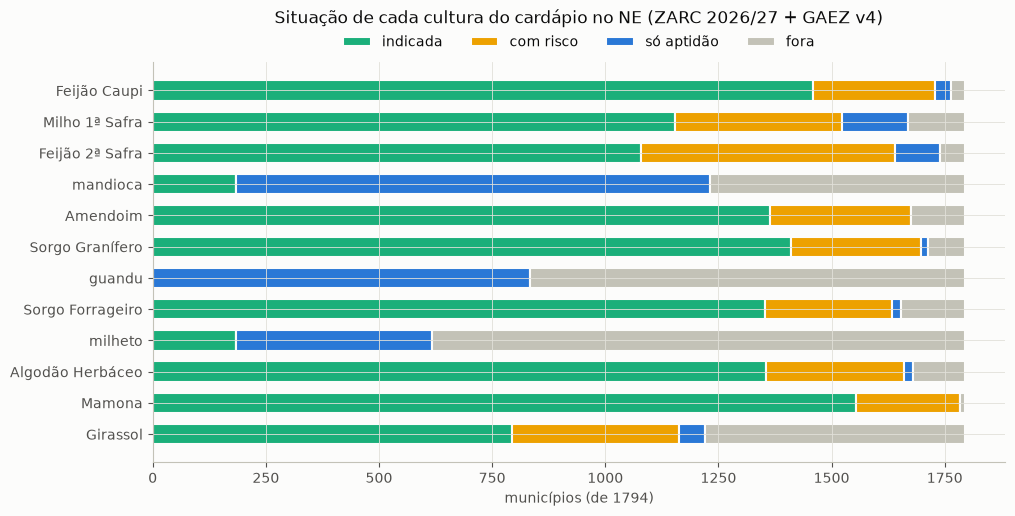

situacao,indicada,com risco,só aptidão,fora,total
cultura,,,,,
Feijão Caupi,1459,269,36,30,1794
Milho 1ª Safra,1154,370,144,126,1794
Feijão 2ª Safra,1079,561,99,55,1794
mandioca,184,0,1048,562,1794
Amendoim,1363,312,0,119,1794
Sorgo Granífero,1410,288,16,80,1794
guandu,0,0,833,961,1794
Sorgo Forrageiro,1352,281,21,140,1794
milheto,184,0,433,1177,1794


In [15]:
X = M.GZT.copy()  # a mesma tabela que o motor carregou
menu = ["Feijão Caupi", "Milho 1ª Safra", "Feijão 2ª Safra", "mandioca", "Amendoim", "Sorgo Granífero", "guandu",
        "Sorgo Forrageiro", "milheto", "Algodão Herbáceo", "Mamona", "Girassol"]
X = X[X.cultura.isin(menu)].copy()
X["fonte"] = np.where(X.zarc_no_municipio, "ZARC (tábua aberta)", "GAEZ")
for nome_m, cult in [("Mandioca", "mandioca"), ("Milheto", "milheto")]:  # no CE, a portaria plurianual decide (seção 2)
    s_ = SIT_PLUR[nome_m][SIT_PLUR[nome_m] != "fora da portaria"]
    sel_ = (X.cultura == cult) & X.geocodigo.isin(s_.index)
    X.loc[sel_, "situacao"] = X.loc[sel_, "geocodigo"].map(s_)
    X.loc[sel_, "fonte"] = "ZARC plurianual (CE)"
# conferência: a mesma situação que a página mostra (motor.cardapio no ponto interno), em 60 municípios do CE (onde entram
# as plurianuais) e em 30 por UF nas outras 8. A janela por solo não entra na situação; ela fica desligada durante a
# conferência, e a consulta às plurianuais fica em cache, só para o laço ser rápido.
nome_x = {nome: (z or g) for nome, _, g, z, _ in M.CARDAPIO if (z or g) in menu}
sx = X.set_index(["geocodigo", "cultura"]).situacao
amostra = list(MUN.cod[MUN.uf == "CE"].sample(60, random_state=0)) + list(MUN[MUN.uf != "CE"].groupby("uf").cod.apply(lambda s: s.sample(30, random_state=0)).explode())
iguais = total = 0
_jps = M.janelas_por_solo
_zp = M.zarc_plurianual
M.janelas_por_solo = lambda cod, cultura: []
M.zarc_plurianual = __import__("functools").lru_cache(maxsize=None)(_zp)
try:
    for cod in amostra:
        si_ = {(c, "Low"): GB.at[cod, c] for c in GB.columns} | {(c, "High"): GA.at[cod, c] for c in GA.columns}
        for it in M.cardapio({"cod": cod, "uf": UFMUN[cod]}, si_):
            if it["cultura"] in nome_x:
                total += 1
                iguais += it["situacao"] == sx[(cod, nome_x[it["cultura"]])]
finally:
    M.janelas_por_solo, M.zarc_plurianual = _jps, _zp
print(f"Conferência com motor.cardapio: {iguais} de {total} pares município × cultura com a mesma situação ({len(amostra)} municípios)")
print("De onde vem a decisão (pares município × cultura):")
display(pd.crosstab(X.cultura, X.fonte).reindex(menu))
print(f"{X.geocodigo.nunique()} municípios × {X.cultura.nunique()} culturas com dado = {len(X)} linhas; "
      f"ciclos conferidos (só CE): {int(X.ciclos_conferidos.sum())} linhas")
sit_ordem = ["indicada", "com risco", "só aptidão", "fora"]
T = pd.crosstab(X.cultura, X.situacao).reindex(index=menu, columns=sit_ordem, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 5.2))
esq = np.zeros(len(T))
for i, s in enumerate(sit_ordem):
    ax.barh(T.index, T[s], left=esq, color=[CAT[2], CAT[3], CAT[0], CINZA][i], label=s, height=0.65, edgecolor="#fcfcfb", linewidth=1.5)
    esq += T[s].values
ax.invert_yaxis()
ax.set_xlabel(f"municípios (de {X.geocodigo.nunique()})")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Situação de cada cultura do cardápio no NE (ZARC 2026/27 + GAEZ v4)", pad=28)
plt.show()
display(T.assign(total=T.sum(1)))

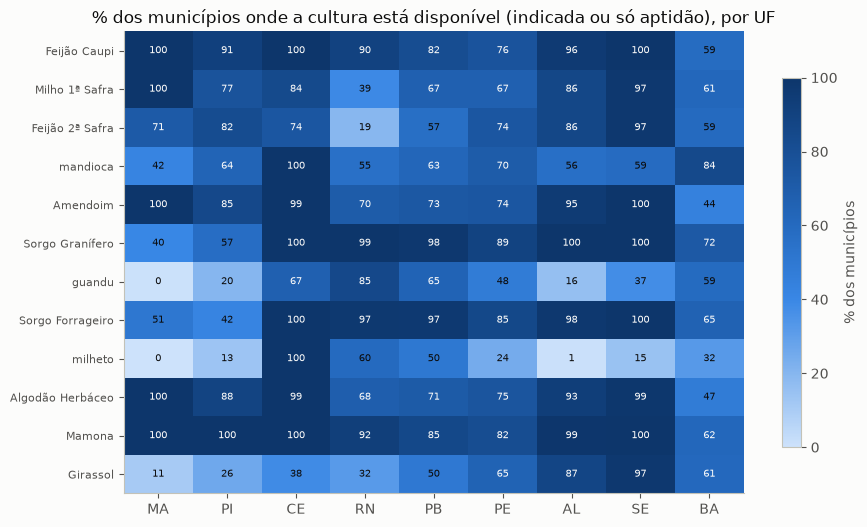

De onde vem a decisão: % dos municípios em que a cultura tem ZARC (o ZARC decide), por UF:


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
cultura,,,,,,,,,
Feijão Caupi,100.0,100.0,100.0,100.0,100.0,99.0,100.0,100.0,85.0
Milho 1ª Safra,100.0,98.0,100.0,84.0,80.0,87.0,95.0,100.0,60.0
Feijão 2ª Safra,100.0,100.0,100.0,84.0,94.0,95.0,100.0,100.0,75.0
Amendoim,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Sorgo Granífero,82.0,75.0,100.0,100.0,100.0,99.0,100.0,100.0,100.0
Sorgo Forrageiro,71.0,57.0,100.0,100.0,100.0,99.0,100.0,100.0,100.0
Algodão Herbáceo,100.0,100.0,100.0,100.0,100.0,97.0,100.0,100.0,69.0
Mamona,100.0,100.0,100.0,100.0,100.0,99.0,100.0,100.0,98.0
Girassol,21.0,47.0,57.0,56.0,72.0,90.0,98.0,100.0,75.0


Culturas disponíveis por município (de 12 com dado): nenhuma em 22 municípios, até 3 em 140. Por UF:


,MA,PI,CE,RN,PB,PE,AL,SE,BA
min,5.0,2.0,8.0,2.0,1.0,0.0,1.0,5.0,0.0
25%,6.0,6.0,10.0,7.0,7.0,7.0,9.0,9.0,4.0
50%,7.0,7.0,11.0,9.0,9.0,9.0,10.0,10.0,8.0
75%,9.0,9.0,11.0,10.0,11.0,11.0,10.0,11.0,10.0
max,10.0,11.0,12.0,11.0,12.0,12.0,12.0,12.0,12.0


Exemplos (situação de cada cultura):


municipio,Arapiraca,Balsas,Barreiras,Quixadá
cultura,,,,
Feijão Caupi,indicada,indicada,indicada,indicada
Milho 1ª Safra,indicada,indicada,indicada,com risco
Feijão 2ª Safra,indicada,indicada,indicada,com risco
mandioca,fora,só aptidão,só aptidão,indicada
Amendoim,indicada,indicada,indicada,indicada
Sorgo Granífero,indicada,indicada,indicada,indicada
guandu,fora,fora,fora,só aptidão
Sorgo Forrageiro,indicada,indicada,indicada,indicada
milheto,fora,fora,fora,indicada


In [16]:
X["disponivel"] = X.situacao.isin(["indicada", "só aptidão"])
P = X.pivot_table(index="cultura", columns="uf", values="disponivel", aggfunc="mean").reindex(index=menu, columns=UF_ORDEM) * 100
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(P.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(9))
ax.set_xticklabels(UF_ORDEM)
ax.set_yticks(range(len(menu)))
ax.set_yticklabels(menu, fontsize=8)
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        ax.text(j, i, f"{P.values[i, j]:.0f}", ha="center", va="center", fontsize=7, color="#fcfcfb" if P.values[i, j] > 60 else "#0b0b0b")
ax.grid(False)
plt.colorbar(im, ax=ax, label="% dos municípios", shrink=0.8)
ax.set_title("% dos municípios onde a cultura está disponível (indicada ou só aptidão), por UF")
plt.show()
print("De onde vem a decisão: % dos municípios em que a cultura tem ZARC (o ZARC decide), por UF:")
display((X[X.cultura.isin(MENU_Z)].pivot_table(index="cultura", columns="uf", values="zarc_no_municipio", aggfunc="mean")
         .reindex(index=MENU_Z, columns=UF_ORDEM) * 100).round(0))
disp = X[X.disponivel].groupby("geocodigo").cultura.nunique().reindex(MUN.cod, fill_value=0)
print(f"Culturas disponíveis por município (de 12 com dado): nenhuma em {int((disp == 0).sum())} municípios, até 3 em {int((disp <= 3).sum())}. Por UF:")
display(disp.groupby(UFMUN.reindex(disp.index).values).describe()[["min", "25%", "50%", "75%", "max"]].reindex(UF_ORDEM).T)
ex = MUN[(MUN.municipio.isin(["Quixadá", "Barreiras", "Arapiraca", "Balsas"]))].set_index("cod")
print("Exemplos (situação de cada cultura):")
display(X[X.geocodigo.isin(ex.index)].pivot_table(index="cultura", columns="municipio", values="situacao", aggfunc="first").reindex(menu))

,n,Spearman NE,p,Spearman dentro da UF (mediana),UFs com Spearman < 0,UFs avaliadas,indicada pelo ZARC e GAEZ ≤ 40
cultura,,,,,,,
Feijão Caupi,1728,-0.25,1.700000e-26,-0.06,6,9,1061
Milho 1ª Safra,1524,-0.52,8.800000e-108,-0.33,8,9,949
Feijão 2ª Safra,1640,-0.29,4.100000e-32,-0.21,8,9,814
Sorgo Granífero,1698,-0.10,8.000000e-05,-0.46,7,9,704
Sorgo Forrageiro,1633,-0.19,8.700000e-15,-0.47,7,9,688
Amendoim,1794,-0.54,1.900000e-138,-0.42,9,9,1176
Algodão Herbáceo,1660,-0.37,9.700000e-54,-0.29,8,9,1231
Girassol,1163,0.29,7.900000e-24,0.28,3,9,551


Pares município × cultura indicados pelo ZARC que um corte pelo GAEZ (≤ 40) derrubaria: 7285, em 1351 municípios (75% do NE)


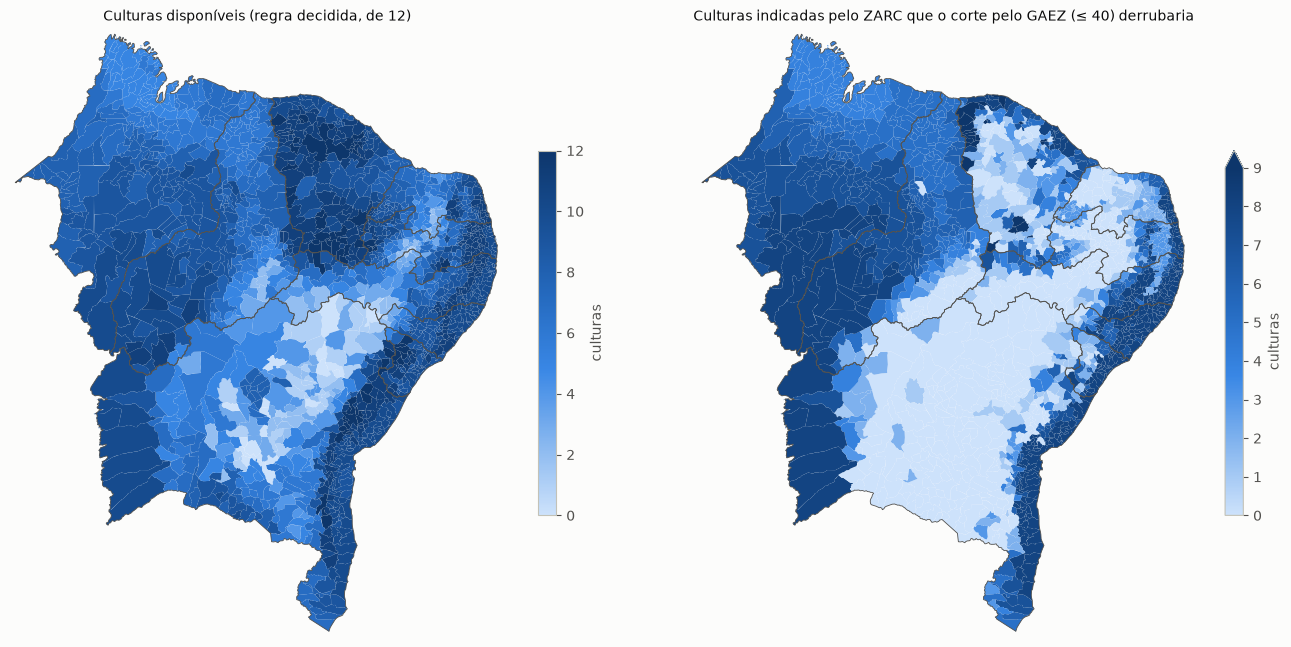

In [17]:
# o GAEZ concorda com o ZARC? aptidão (insumo baixo) × nº de decêndios com risco de 20% (união de solos e ciclos)
pares = {"Feijão Caupi": "feijão-caupi", "Milho 1ª Safra": "milho", "Feijão 2ª Safra": "feijão (Phaseolus)", "Sorgo Granífero": "sorgo",
         "Sorgo Forrageiro": "sorgo", "Amendoim": "amendoim", "Algodão Herbáceo": "algodão", "Girassol": "girassol"}
res = []
for cz, cg in pares.items():
    q_ = JJ[JJ.Nome_cultura == cz].set_index("cod")
    a_ = GB[cg].reindex(q_.index)
    rho, p = stats.spearmanr(a_, q_.n20_uniao)
    dentro = [stats.spearmanr(a_[q_.uf == u], q_.n20_uniao[q_.uf == u])[0] for u in UF_ORDEM if (q_.uf == u).sum() >= 20]
    res.append({"cultura": cz, "n": len(q_), "Spearman NE": round(rho, 2), "p": float(f"{p:.2g}"),
                "Spearman dentro da UF (mediana)": round(float(np.nanmedian(dentro)), 2),
                "UFs com Spearman < 0": int(np.sum(np.array(dentro) < 0)), "UFs avaliadas": len(dentro),
                "indicada pelo ZARC e GAEZ ≤ 40": int(((a_ <= GZ.APTA) & (q_.n20_uniao > 0)).sum())})
R = pd.DataFrame(res).set_index("cultura")
display(R)
corte = X[(X.situacao == "indicada") & (X["SI baixo"] <= GZ.APTA)].groupby("geocodigo").size().reindex(MUN.cod, fill_value=0)
print(f"Pares município × cultura indicados pelo ZARC que um corte pelo GAEZ (≤ {GZ.APTA}) derrubaria: {int(corte.sum())}, "
      f"em {int((corte > 0).sum())} municípios ({(corte > 0).mean():.0%} do NE)")
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
mapa_ne(axs[0], disp, "Culturas disponíveis (regra decidida, de 12)", vmin=0, vmax=12, rotulo="culturas")
mapa_ne(axs[1], corte, f"Culturas indicadas pelo ZARC que o corte pelo GAEZ (≤ {GZ.APTA}) derrubaria", vmin=0, vmax=9, rotulo="culturas")
plt.tight_layout()
plt.show()

**Leitura:**
- **A tabela reproduz a página:** a situação bate com `motor.cardapio` em 3.600 de 3.600 pares município × cultura (60
  municípios do CE, onde entram as plurianuais, e 30 em cada uma das outras 8 UFs).
- **Com a regra decidida, a mamona é a cultura mais indicada** (1.553 de 1.794 municípios). Depois vêm caupi (1.459),
  sorgo granífero (1.410), amendoim (1.363), algodão (1.355) e sorgo forrageiro (1.352). O milho é indicado em 1.154 e
  fica "com risco" em 370; o girassol é indicado em 793.
- **De onde vem a decisão:**
  - o GAEZ decide o guandu nos 1.794 municípios e a mandioca e o milheto nos 1.610 de fora do CE ("só aptidão": mandioca
    em 1.048, guandu em 833, milheto em 433);
  - **no CE, a mandioca e o milheto seguem a portaria plurianual** e ficam indicados nos 184 municípios;
  - nas culturas da tábua aberta, o GAEZ decide pouco. As exceções são o girassol (sem ZARC em 631 municípios; ZARC em
    só 21% do MA e 47% do PI) e o milho (sem ZARC em 270; ZARC em 60% da BA).
- **Culturas disponíveis por município:** mediana de 11 (de 12) no CE, com as plurianuais; 10 em AL e SE; 9 em RN, PB e
  PE; 8 na BA; 7 no MA e no PI. **22 municípios não têm nenhuma**, quase todos no centro da BA, e 140 têm até 3.
- **Exemplos:** em Quixadá, milho e feijão de 2ª safra ficam "com risco", o girassol fica fora, mandioca e milheto são
  indicados pela portaria plurianual, e o guandu entra pela aptidão. Balsas, Barreiras e Arapiraca têm as 9 culturas da
  tábua aberta indicadas.
- **O GAEZ e o ZARC NÃO concordam no NE.** A aptidão e o comprimento da janela de 20% têm correlação negativa em 7 de 8
  culturas:
  - amendoim −0,54; milho −0,52; algodão −0,37; feijão de 2ª safra −0,29; caupi −0,25; sorgo forrageiro −0,19; sorgo
    granífero −0,10;
  - só o girassol é positivo (+0,29);
  - dentro de cada UF, a mediana continua negativa (sorgo −0,46 e −0,47; amendoim −0,42; milho −0,33; caupi −0,06).
    Então não é só efeito de comparar estados.
- **Se o GAEZ cortasse (≤ 40), cairiam 7.285 pares município × cultura que o ZARC indica (tábua aberta e plurianuais do
  CE), em 1.351 municípios (75% do NE).** Isso sustenta a regra: onde há ZARC, o ZARC decide.

## 4. NASA POWER: a assinatura climática do lugar

**Ficha técnica**
- **O que é:** a API do NASA POWER (comunidade AG), numa célula de 0,5° × 0,625°.
  - Climatologia (`/api/temporal/climatology/point`): médias mensais de chuva (`PRECTOTCORR`), temperatura média,
    umidade, vento e radiação.
  - **Tmax e Tmin: médias das máximas e mínimas diárias de 2001–2024** (`/api/temporal/daily/point`). Até 14/11, a
    assinatura usava `T2M_MAX` e `T2M_MIN` da climatologia, que **são o extremo do mês (o recorde), não a média**: em
    Quixadá, janeiro dava 39,3 °C contra 34,9 °C de média diária (revisão C2). Todas as tabelas foram regeradas.
- **Assinatura (6 variáveis):**
  - chuva anual;
  - sazonalidade de Walsh;
  - meses úmidos (P ≥ ET0/2);
  - aridez P/ET0 (ET0 FAO-56 Penman-Monteith, que usa a Tmax e a Tmin);
  - Tmax da estação úmida;
  - Tmax do mês mais quente.
- **Arquivo:** `analogos_aprofundado/ne_mun_assinaturas.csv`, uma assinatura no ponto interno de cada um dos 1.794
  municípios.

**No protótipo:**
- no NE, a assinatura pré-calculada do município (a célula do ponto interno);
- fora do NE, a API é consultada ao vivo e guardada em cache pela célula nativa do POWER (revisão M13);
- a assinatura alimenta os análogos (seção 5).

In [18]:
VARS = M.VARS
PW = M.MUNA.copy()  # ne_mun_assinaturas.csv, indexado pelo código IBGE
PW["uf"] = UFMUN.reindex(PW.index)
celulas = PW[VARS].drop_duplicates()
n_cel = len({M._chave_power(la, lo) for la, lo in zip(PW.lat, PW.lon)})
print(f"{len(PW)} municípios, sem assinatura: {int(PW.chuva_anual_mm.isna().sum())}; {n_cel} células do POWER e {len(celulas)} "
      "assinaturas diferentes: a célula (~55 × 70 km) cobre vários municípios. Para estatística, a amostra efetiva é de células.")
display(descreve(PW[VARS + ["et0_anual_mm", "altitude_m"]]))
print("Mediana por UF:")
display(PW.groupby("uf")[VARS + ["et0_anual_mm"]].median().reindex(UF_ORDEM).round(2))
cel_uf = PW.assign(cel=[M._chave_power(la, lo) for la, lo in zip(PW.lat, PW.lon)]).groupby("uf").cel.nunique().reindex(UF_ORDEM)
display(pd.DataFrame({"municípios": PW.uf.value_counts().reindex(UF_ORDEM), "células do POWER": cel_uf}).T)

1794 municípios, sem assinatura: 0; 396 células do POWER e 396 assinaturas diferentes: a célula (~55 × 70 km) cobre vários municípios. Para estatística, a amostra efetiva é de células.


,n,ausentes_%,média,dp,min,5%,25%,mediana,75%,95%,max,assimetria
chuva_anual_mm,1794.0,0.0,935.05,289.09,426.00,602.95,718.00,897.50,1102.00,1469.10,2194.00,1.18
sazonalidade_walsh,1794.0,0.0,0.62,0.22,0.10,0.17,0.48,0.67,0.81,0.89,0.94,-0.59
meses_umidos,1794.0,0.0,5.67,2.10,0.00,3.00,5.00,5.00,7.00,11.00,12.00,0.91
aridez_P_ET0,1794.0,0.0,0.54,0.25,0.18,0.27,0.33,0.48,0.67,0.99,1.68,1.32
tmax_estacao_umida,1794.0,0.0,30.84,1.53,27.00,28.50,29.90,30.70,31.80,33.33,36.80,0.37
tmax_mes_mais_quente,1794.0,0.0,35.19,2.39,28.30,31.00,33.30,35.40,37.20,38.20,39.10,-0.48
et0_anual_mm,1794.0,0.0,1868.08,330.24,1224.00,1302.00,1645.00,1867.00,2141.00,2378.00,2493.00,-0.08
altitude_m,1794.0,0.0,298.82,205.57,0.00,29.00,134.00,271.00,443.75,686.00,1119.00,0.74


Mediana por UF:


,chuva_anual_mm,sazonalidade_walsh,meses_umidos,aridez_P_ET0,tmax_estacao_umida,tmax_mes_mais_quente,et0_anual_mm
uf,,,,,,,
MA,1394.0,0.75,7.0,0.95,30.6,37.0,1476.0
PI,826.0,0.83,5.0,0.37,31.7,37.8,2210.0
CE,887.0,0.84,5.0,0.43,30.9,37.0,2065.0
RN,761.0,0.76,5.0,0.33,32.0,35.3,2147.0
PB,778.0,0.56,5.0,0.37,30.5,34.6,1959.0
PE,912.0,0.48,6.0,0.55,29.2,33.2,1714.0
AL,1031.0,0.49,5.0,0.58,28.8,33.2,1816.0
SE,945.0,0.46,5.0,0.53,29.0,33.6,1760.0
BA,775.0,0.33,6.0,0.50,30.7,33.8,1641.0


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
municípios,217,224,184,167,223,185,102,75,417
células do POWER,84,71,50,26,23,39,13,12,134


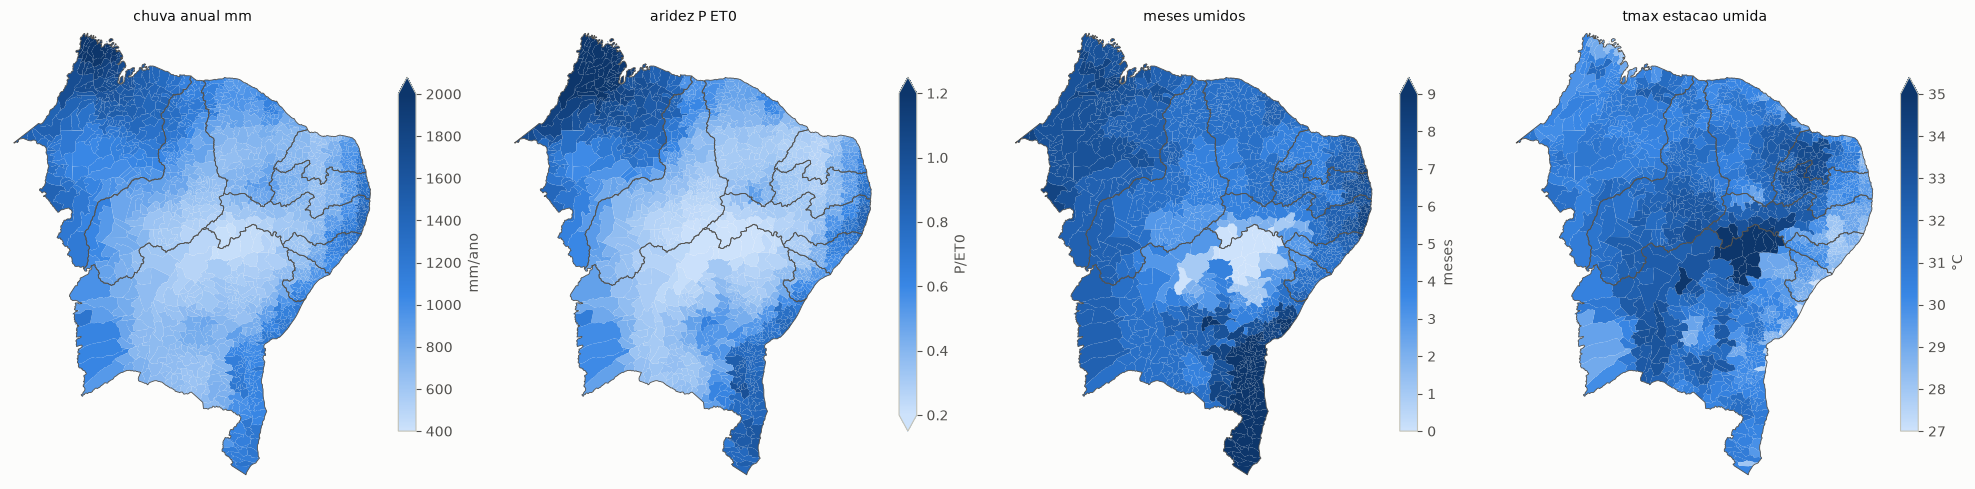

In [19]:
fig, axs = plt.subplots(1, 4, figsize=(20, 6.2))
for ax, (v, rot, vmin, vmax) in zip(axs, [("chuva_anual_mm", "mm/ano", 400, 2000), ("aridez_P_ET0", "P/ET0", 0.2, 1.2),
                                          ("meses_umidos", "meses", 0, 9), ("tmax_estacao_umida", "°C", 27, 35)]):
    mapa_ne(ax, PW[v], v.replace("_", " "), vmin=vmin, vmax=vmax, rotulo=rot)
plt.tight_layout()
plt.show()

In [20]:
# por que a assinatura mudou: Tmax/Tmin recorde (climatologia) × médias diárias (2001–2024), no CE e nos lugares dos artigos
old = pd.read_csv(D_APR / "ceara_mun_assinaturas_tmax_recorde.csv", dtype={"cod": str}).set_index("cod")
dif = pd.DataFrame({v: PW.loc[old.index, v] - old[v] for v in ["tmax_estacao_umida", "tmax_mes_mais_quente", "et0_anual_mm",
                                                                 "aridez_P_ET0", "meses_umidos", "chuva_anual_mm"]})
print("CE, 184 municípios: assinatura nova (médias diárias) − antiga (recorde do mês):")
display(dif.describe().T[["mean", "min", "50%", "max"]].round(2).rename(columns={"mean": "média", "50%": "mediana"}))
A_ = pd.read_csv(DADOS / "analogos_artigos" / "assinaturas.csv")
A_old = pd.read_csv(DADOS / "analogos_artigos" / "assinaturas_tmax_recorde.csv")
lug = A_[["ponto", "tmax_estacao_umida", "tmax_mes_mais_quente", "et0_anual_mm"]].merge(
    A_old[["ponto", "tmax_estacao_umida", "tmax_mes_mais_quente", "et0_anual_mm"]], on="ponto", suffixes=("", " (recorde)"))
lug["Δ Tmax úmida"] = lug.tmax_estacao_umida - lug["tmax_estacao_umida (recorde)"]
lug = lug.merge(A_[["ponto", "meses_umidos"]], on="ponto").merge(A_old[["ponto", "meses_umidos"]], on="ponto", suffixes=("", " (recorde)"))
print(f"Lugares de referência (n = {len(lug)}): Δ Tmax da estação úmida de {lug['Δ Tmax úmida'].min():+.1f} a {lug['Δ Tmax úmida'].max():+.1f} °C")
display(lug[lug.ponto.str.contains("Quixadá|Harare|Niamey|Iowa|Bom Jesus|Sobral-CE|Embu") | (lug["Δ Tmax úmida"] == lug["Δ Tmax úmida"].min())].set_index("ponto").round(1))

CE, 184 municípios: assinatura nova (médias diárias) − antiga (recorde do mês):


,média,min,mediana,max
tmax_estacao_umida,-5.97,-7.2,-6.40,-2.20
tmax_mes_mais_quente,-2.23,-3.5,-2.20,-1.70
et0_anual_mm,-98.09,-177.0,-92.00,-19.00
aridez_P_ET0,0.02,0.0,0.02,0.04
meses_umidos,0.03,0.0,0.00,1.00
chuva_anual_mm,0.00,0.0,0.00,0.00


Lugares de referência (n = 32): Δ Tmax da estação úmida de -36.5 a -2.5 °C


,tmax_estacao_umida,tmax_mes_mais_quente,et0_anual_mm,tmax_estacao_umida (recorde),tmax_mes_mais_quente (recorde),et0_anual_mm (recorde),Δ Tmax úmida,meses_umidos,meses_umidos (recorde)
ponto,,,,,,,,,
Sobral-CE,30.9,38.1,1962.0,37.3,39.9,2051.0,-6.4,5,5
"Cerrado piauiense (Bom Jesus-PI, aprox.)",32.2,37.2,2219.0,39.9,42.0,2404.0,-7.7,5,5
"Zona sudano-saheliana (Niamey, aprox.)",32.7,41.1,2647.0,40.1,44.9,2856.0,-7.4,3,3
"África Austral (Harare, aprox.)",27.9,30.8,1693.0,35.2,37.9,1887.0,-7.3,5,4
"Planalto da África Oriental (Embu, aprox.)",27.1,29.6,1443.0,31.3,34.0,1506.0,-4.2,9,8
Iowa (Ames),15.5,29.8,892.0,28.9,42.1,1206.0,-13.4,12,11
Kansas sudoeste,8.5,35.0,1549.0,45.0,45.0,2167.0,-36.5,1,0
CE: Quixadá (Sertão Central),32.6,38.3,2211.0,39.2,40.2,2324.0,-6.6,5,5


Pares mais negativos: aridez_P_ET0 × tmax_estacao_umida -0.63; chuva_anual_mm × tmax_estacao_umida -0.57; meses_umidos × tmax_estacao_umida -0.49
Pares mais positivos: chuva_anual_mm × meses_umidos +0.82; meses_umidos × aridez_P_ET0 +0.88; chuva_anual_mm × aridez_P_ET0 +0.94


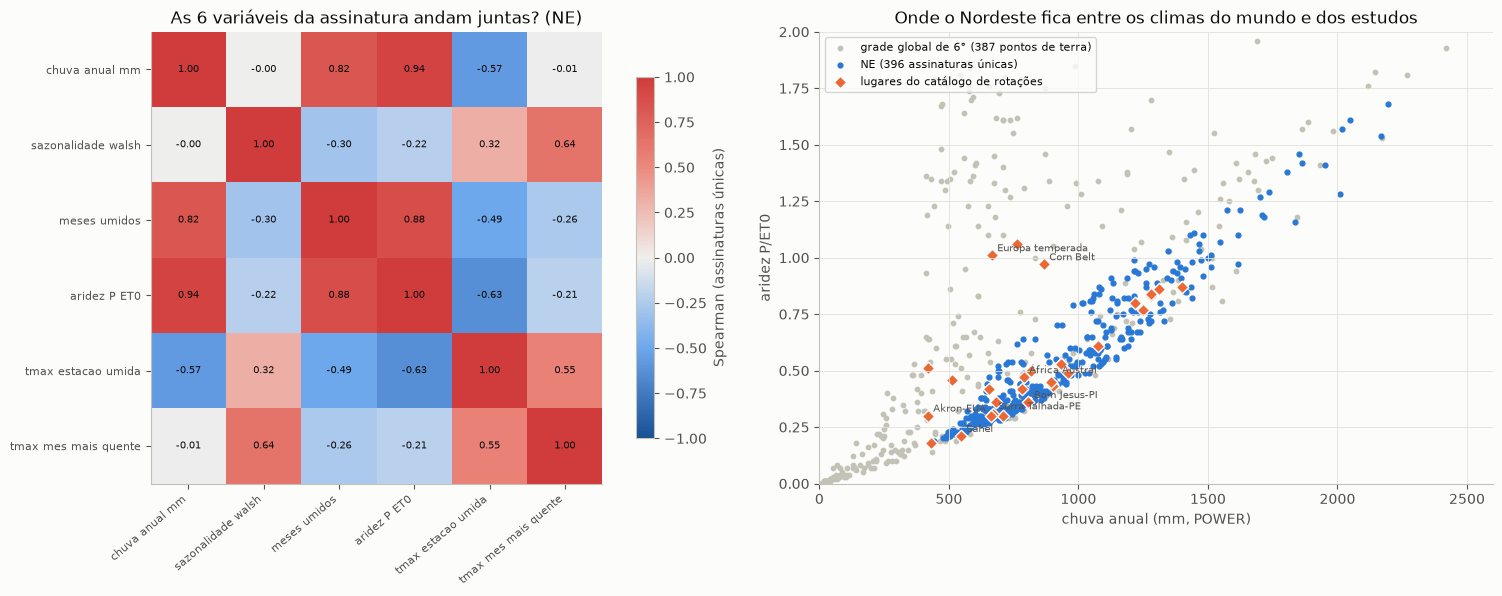

Meses úmidos: municípios por UF


meses_umidos,0,1,2,3,4,5,6,7,8,9,10,11,12
uf,,,,,,,,,,,,,
MA,0,0,0,0,0,6,70,117,24,0,0,0,0
PI,0,0,0,30,62,96,36,0,0,0,0,0,0
CE,0,0,0,0,32,123,29,0,0,0,0,0,0
RN,0,0,0,0,65,28,60,7,7,0,0,0,0
PB,0,0,0,0,30,91,33,62,7,0,0,0,0
PE,3,2,9,8,23,28,53,35,24,0,0,0,0
AL,0,0,0,20,0,52,28,0,2,0,0,0,0
SE,0,0,0,8,0,60,7,0,0,0,0,0,0
BA,17,19,4,39,38,88,31,25,41,9,2,38,66


In [21]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
cor = celulas.corr("spearman")
im = axs[0].imshow(cor.values, cmap=DIV, vmin=-1, vmax=1)
axs[0].set_xticks(range(len(VARS)))
axs[0].set_xticklabels([v.replace("_", " ") for v in VARS], rotation=40, ha="right", fontsize=8)
axs[0].set_yticks(range(len(VARS)))
axs[0].set_yticklabels([v.replace("_", " ") for v in VARS], fontsize=8)
for i in range(len(VARS)):
    for j in range(len(VARS)):
        axs[0].text(j, i, f"{cor.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
axs[0].grid(False)
plt.colorbar(im, ax=axs[0], shrink=0.8, label="Spearman (assinaturas únicas)")
axs[0].set_title("As 6 variáveis da assinatura andam juntas? (NE)")
pc = cor.where(np.triu(np.ones(cor.shape, bool), 1)).stack().dropna().sort_values()
print("Pares mais negativos:", "; ".join(f"{a} × {b} {v:+.2f}" for (a, b), v in pc.head(3).items()))
print("Pares mais positivos:", "; ".join(f"{a} × {b} {v:+.2f}" for (a, b), v in pc.tail(3).items()))
SIT = M.SIT
LA = M.LA
GL = pd.read_csv(D_APR / "global_assinaturas.csv")
axs[1].scatter(GL.chuva_anual_mm, GL.aridez_P_ET0, s=10, color=CINZA, label=f"grade global de 6° ({len(GL)} pontos de terra)")
axs[1].scatter(celulas.chuva_anual_mm, celulas.aridez_P_ET0, s=12, color=CAT[0], label=f"NE ({len(celulas)} assinaturas únicas)")
axs[1].scatter(LA.chuva_anual_mm, LA.aridez_P_ET0, s=40, color=CAT[1], marker="D", edgecolor="#fcfcfb", label="lugares do catálogo de rotações")
for _, r in LA[LA.lugar.str.contains("Corn Belt|Sahel|Harare|Bom Jesus|Serra Talhada|Europa|Akron")].iterrows():
    axs[1].annotate(r.lugar.split(" (")[0], (r.chuva_anual_mm, r.aridez_P_ET0), fontsize=7, xytext=(4, 3), textcoords="offset points", color="#52514e")
axs[1].set_xlim(0, 2600)
axs[1].set_ylim(0, 2)
axs[1].set_xlabel("chuva anual (mm, POWER)")
axs[1].set_ylabel("aridez P/ET0")
axs[1].legend(fontsize=8, loc="upper left")
axs[1].set_title("Onde o Nordeste fica entre os climas do mundo e dos estudos")
plt.tight_layout()
plt.show()
print("Meses úmidos: municípios por UF")
display(pd.crosstab(PW.uf, PW.meses_umidos.astype(int)).reindex(UF_ORDEM))

**Leitura:**
- **Os 1.794 municípios caem em 396 células do POWER**, com 396 assinaturas diferentes. A BA tem 134 células; AL, 13; SE,
  12. Para estatística, a amostra efetiva é de células, não de municípios.
- **O clima do NE pelo POWER** (mediana dos municípios): chuva de 898 mm (426 a 2.194), aridez 0,48 (0,18 a 1,68), 5
  meses úmidos (0 a 12), Tmax da estação úmida de 30,7 °C (27,0 a 36,8) e ET0 de 1.867 mm.
  - O MA é o mais úmido: 1.394 mm, aridez 0,95 e 7 meses úmidos. RN, BA, PB e PI ficam entre 761 e 826 mm.
  - A Tmax da estação úmida é maior no RN (32,0 °C) e no PI (31,7) e menor em AL (28,8), SE (29,0) e PE (29,2).
  - Na BA, 104 municípios têm 11 ou 12 meses úmidos, e 17 não têm nenhum.
- **A correção da Tmax mudou a assinatura** (CE, 184 municípios):
  - Tmax da estação úmida −6,0 °C em média (−2,2 a −7,2); Tmax do mês mais quente −2,2 °C; ET0 −98 mm (−19 a −177);
    aridez +0,02. A chuva não mudou;
  - em Quixadá, a Tmax da estação úmida foi de 39,2 para 32,6 °C; em Harare, de 35,2 para 27,9 °C;
  - nos lugares temperados, a ET0 menor muda até os meses úmidos. No Kansas sudoeste, um mês frio passou a contar como
    úmido, e a Tmax da estação úmida foi de 45,0 para 8,5 °C. É efeito da definição da variável, não do clima.
- **As variáveis andam juntas** (assinaturas únicas): chuva × aridez +0,94; meses úmidos × aridez +0,88; chuva × meses
  úmidos +0,82. A Tmax da estação úmida cai onde chove mais (−0,57) e onde a aridez é menor (−0,63). Na prática, a
  assinatura tem dois eixos: água e calor.
- **No gráfico de dispersão, o NE ocupa uma faixa larga e estreita ao mesmo tempo:** de 426 a 2.194 mm de chuva, sempre
  na mesma reta de aridez. Os lugares do catálogo caem quase todos dentro da nuvem do NE; Corn Belt e Europa temperada
  ficam acima dela, com mais água para a mesma chuva.

## 5. Análogos climáticos: quanto cada estudo vale em cada lugar

- **Referências** (regeradas em 14/11 com a Tmax média):
  - `analogos_artigos/assinaturas.csv`: 20 lugares de artigos e 12 pontos do CE. A média e o desvio dos 32 pontos
    padronizam as variáveis; os 20 lugares de artigos são os candidatos a análogo;
  - `analogos_aprofundado/catalogo_lugares_assinaturas.csv`: os 31 lugares dos cartões do catálogo com lugar.
- **Distância:** euclidiana nas 6 variáveis padronizadas. **Peso de transferência:** w = exp(−d²/2) (`motor.analogos`).
- **Confiança no protótipo** (w do melhor estudo, **arredondado a 2 casas antes de classificar**, revisão M16):
  - w ≥ 0,6: "estudos de clima muito parecido";
  - de 0,3 a 0,6: "parecido";
  - < 0,3: "a evidência vale só como direção".
- **Evidência perto:** os cartões cujo lugar tem w ≥ 0,3 (até 12 na página).
- **Franke ponderado pelo clima** (leguminosa → cereal): só aparece quando a soma dos w dos 3 estratos do Franke é ≥ 0,3
  (revisão M19).

In [22]:
z_m = (PW[VARS] - M.MU) / M.SD
dist_s = np.sqrt((((z_m.values[:, None, :] - ((SIT[VARS] - M.MU) / M.SD).values[None]) ** 2).sum(2)))
dist_l = np.sqrt((((z_m.values[:, None, :] - ((LA[VARS] - M.MU) / M.SD).values[None]) ** 2).sum(2)))
Ws = pd.DataFrame(np.exp(-dist_s ** 2 / 2), index=PW.index, columns=SIT.ponto)
Wl = pd.DataFrame(np.exp(-dist_l ** 2 / 2), index=PW.index, columns=LA.lugar)
melhor = Ws.max(1).round(2)
# conferência com o motor em 3 municípios
for cod in ["2311306", "2611606", "2903201"]:
    S_, _ = M.analogos({k: float(PW.loc[cod, k]) for k in VARS})
    assert round(float(S_.iloc[0].w), 2) == melhor[cod] and S_.iloc[0].ponto == Ws.loc[cod].idxmax()
print(f"Melhor w entre os {len(SIT)} lugares de artigos, nos {len(PW)} municípios (conferido com motor.analogos):")
display(descreve(melhor.rename("melhor w")))
conf = pd.cut(melhor, [-0.01, 0.295, 0.595, 1.0], labels=["< 0,3 (só direção)", "0,3–0,6 (parecido)", "≥ 0,6 (muito parecido)"])
display(pd.crosstab(PW.uf, conf, margins=True, margins_name="total").reindex(UF_ORDEM + ["total"]))
print("Mediana do melhor w por UF:")
display(por_uf(melhor).round(2).to_frame("mediana").T)

Melhor w entre os 20 lugares de artigos, nos 1794 municípios (conferido com motor.analogos):


,n,ausentes_%,média,dp,min,5%,25%,mediana,75%,95%,max,assimetria
melhor w,1794.0,0.0,0.63,0.26,0.03,0.14,0.46,0.67,0.86,0.97,1.0,-0.5


col_0,"< 0,3 (só direção)","0,3–0,6 (parecido)","≥ 0,6 (muito parecido)",total
uf,,,,
MA,90,52,75,217
PI,0,30,194,224
CE,0,2,182,184
RN,0,25,142,167
PB,22,7,194,223
PE,34,44,107,185
AL,2,73,27,102
SE,0,34,41,75
BA,150,149,118,417


Mediana do melhor w por UF:


,MA,PI,CE,RN,PB,PE,AL,SE,BA
mediana,0.35,0.79,0.83,0.76,0.92,0.67,0.55,0.62,0.46


Lugar de artigo mais parecido (nº de municípios):


,"Cerrado piauiense (Bom Jesus-PI, aprox.)",Esperança-PB (Agreste),Serra Talhada-PE,"Planalto da África Oriental (Embu, aprox.)",Teresina-PI,"Savana da Guiné (Tamale, aprox.)","Floresta úmida da África Ocidental (Ibadan, aprox.)",Sobral-CE,Texas (Lubbock),"África Austral (Harare, aprox.)",Petrolina-PE,"Semiárido da Índia (Patancheru, aprox.)","África Austral (Chitedze-Malawi, aprox.)",Planície do Norte da China (aprox.)
municípios,422,412,277,223,159,86,60,54,44,24,15,14,2,2


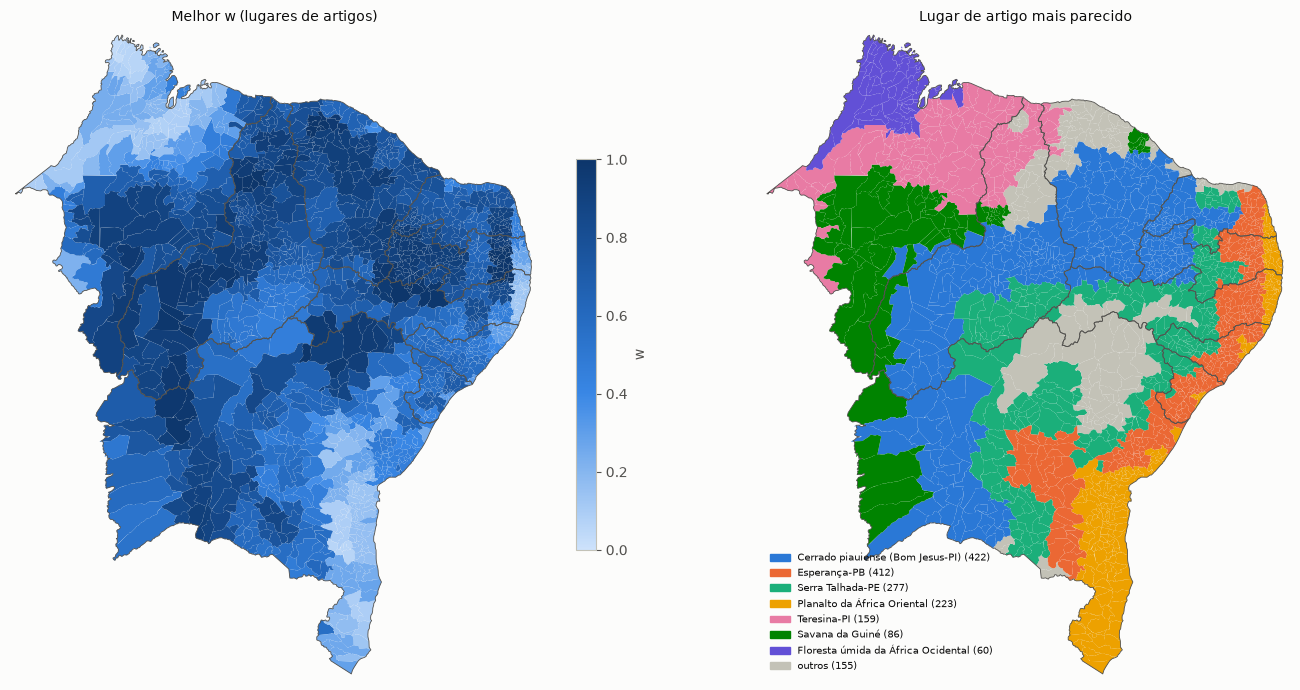

In [23]:
lug_m = Ws.idxmax(1)
top = lug_m.value_counts()
print("Lugar de artigo mais parecido (nº de municípios):")
display(top.rename("municípios").to_frame().T)
cats = list(top.index[:7])
rot = lambda s: s.split(" (")[0] if "(" in s and not s.startswith(("África", "Cerrado")) else s.replace(", aprox.", "")  # noqa: E731
cores = {rot(c): CAT[i] for i, c in enumerate(cats)} | {"outros": CINZA}
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
mapa_ne(axs[0], melhor, "Melhor w (lugares de artigos)", vmin=0, vmax=1, rotulo="w")
mapa_ne(axs[1], lug_m.map(lambda s: rot(s) if s in cats else "outros"), "Lugar de artigo mais parecido", categorias=cores)
plt.tight_layout()
plt.show()

Cartões com lugar: 72; lugares distintos: 31
Cartões do catálogo com w ≥ 0,3 por município (a 'evidência perto' que a página mostra, até 12):


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
min,0.0,4.0,4.0,1.0,3.0,2.0,2.0,0.0,0.0
25%,1.0,13.0,16.0,20.0,18.0,11.0,11.0,13.0,0.0
50%,4.0,21.0,22.0,22.0,22.0,15.0,13.0,18.0,9.0
75%,6.0,23.0,23.0,24.0,27.0,21.0,14.0,23.0,20.0
max,36.0,36.0,35.0,37.0,34.0,35.0,31.0,31.0,40.0


Franke ponderado pelo clima aparece (soma dos w ≥ 0,3) em 1017 de 1794 municípios; por UF (%):


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
%,39.0,95.0,99.0,90.0,67.0,46.0,41.0,45.0,18.0


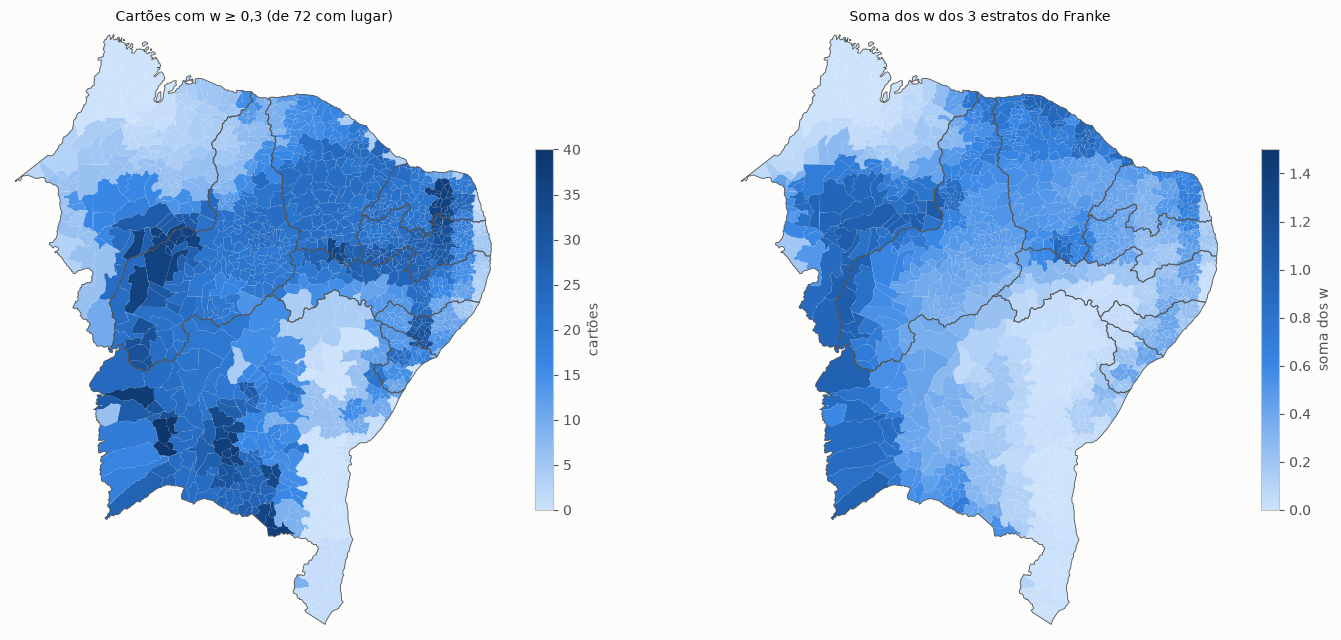

In [24]:
LUG = pd.read_csv(D_APR / "catalogo_cartao_lugar.csv").dropna()
cartoes_w = pd.Series((Wl[LUG.lugar].values >= 0.3).sum(1), index=PW.index)
fr = ["franke_sahel", "franke_guine", "franke_austral"]
soma_fr = Wl[[M.LUG[c] for c in fr]].sum(1)
print(f"Cartões com lugar: {len(LUG)}; lugares distintos: {LUG.lugar.nunique()}")
print("Cartões do catálogo com w ≥ 0,3 por município (a 'evidência perto' que a página mostra, até 12):")
display(cartoes_w.groupby(PW.uf).describe()[["min", "25%", "50%", "75%", "max"]].reindex(UF_ORDEM).T)
print(f"Franke ponderado pelo clima aparece (soma dos w ≥ 0,3) em {int((soma_fr >= 0.3).sum())} de {len(PW)} municípios; por UF (%):")
display(((soma_fr >= 0.3).groupby(PW.uf).mean() * 100).reindex(UF_ORDEM).round(0).to_frame("%").T)
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
mapa_ne(axs[0], cartoes_w, f"Cartões com w ≥ 0,3 (de {len(LUG)} com lugar)", vmin=0, vmax=int(cartoes_w.max()), rotulo="cartões")
mapa_ne(axs[1], soma_fr, "Soma dos w dos 3 estratos do Franke", vmin=0, vmax=1.5, rotulo="soma dos w")
plt.tight_layout()
plt.show()

In [25]:
# CE: antes e depois da correção da Tmax (mesma regra de classificação)
oldA = pd.read_csv(DADOS / "analogos_artigos" / "assinaturas_tmax_recorde.csv")
SITo = oldA[oldA.grupo != "Ceará (alvo)"].reset_index(drop=True)
MUo, SDo = oldA[VARS].mean(), oldA[VARS].std()
do = np.sqrt(((((old[VARS] - MUo) / SDo).values[:, None, :] - ((SITo[VARS] - MUo) / SDo).values[None]) ** 2).sum(2))
Wo = pd.DataFrame(np.exp(-do ** 2 / 2), index=old.index, columns=SITo.ponto)
bo = Wo.max(1).round(2)
ce = melhor[PW.uf == "CE"]
classe = lambda w: pd.cut(w, [-0.01, 0.295, 0.595, 1.0], labels=["< 0,3", "0,3–0,6", "≥ 0,6"]).value_counts().sort_index()  # noqa: E731
print("CE, 184 municípios — confiança com a Tmax recorde (antes) e com a Tmax média (agora):")
display(pd.DataFrame({"antes": classe(bo), "agora": classe(ce)}).T)
display(pd.DataFrame({"antes": Wo.idxmax(1).value_counts().head(5), "agora": Ws.loc[ce.index].idxmax(1).value_counts().head(5)}).fillna(0).astype(int))

CE, 184 municípios — confiança com a Tmax recorde (antes) e com a Tmax média (agora):


,"< 0,3","0,3–0,6","≥ 0,6"
antes,7,19,158
agora,0,2,182


,antes,agora
"Cerrado piauiense (Bom Jesus-PI, aprox.)",42,102
"Planalto da África Oriental (Embu, aprox.)",5,0
"Savana da Guiné (Tamale, aprox.)",0,13
Sobral-CE,78,40
Teresina-PI,4,9
"África Austral (Harare, aprox.)",53,11


**Leitura:**
- **1.080 dos 1.794 municípios (60%) têm um estudo de clima muito parecido** (w ≥ 0,6); 416 têm um parecido (0,3–0,6) e
  298 só direção (< 0,3). A mediana do melhor w é 0,67.
- **A confiança cai a oeste e ao sul:**
  - na PB, no CE, no PI e no RN, a mediana do melhor w fica entre 0,76 e 0,92. O CE tem 182 de 184 municípios com w ≥ 0,6;
  - no MA (mediana 0,35) e na BA (0,46), 90 e 150 municípios ficam abaixo de 0,3;
  - em AL, 73 de 102 ficam em "parecido".
- **De onde vem a evidência:** Bom Jesus-PI (Cerrado piauiense) é o lugar mais parecido para 422 municípios;
  Esperança-PB, para 412; Serra Talhada-PE, 277; Embu (planalto da África Oriental), 223; Teresina, 159. Harare fica com
  24.
- **Densidade de evidência:** mediana de 22 cartões com w ≥ 0,3 no CE, no RN e na PB, contra 9 na BA e 4 no MA (mínimo
  de 0 no MA, em SE e na BA). A página mostra até 12.
- **O Franke ponderado pelo clima aparece em 1.017 municípios** (soma dos w ≥ 0,3): 99% no CE e 95% no PI, mas 18% na BA
  e 39% no MA.
- **A correção da Tmax mudou os análogos do CE:**
  - w ≥ 0,6 passou de 158 para 182 municípios, e < 0,3, de 7 para 0. (O notebook antigo dava 154 porque classificava sem
    arredondar; com a regra do motor, a Tmax recorde dá 158.)
  - Harare deixou de ser o mais parecido em 53 municípios (agora, 11); Sobral caiu de 78 para 40; Bom Jesus subiu de 42
    para 102.
- **No produto:** onde o melhor w fica abaixo de 0,3 (298 municípios, quase todos no MA e na BA), a evidência vale só
  como direção.

## 6. Catálogo de rotações comprovadas: a evidência do motor

**Ficha técnica**
- **O que é:** `pesquisa/catalogo_rotacoes.json`, com 147 configurações debatidas por 10 especialistas e conferidas por
  verificação adversária.
- **Cada cartão traz:**
  - tipo, efeito (valor central e faixa) e onde o efeito foi medido (cultura seguinte, sequência inteira, consórcio,
    solo ou praga);
  - grau A–D;
  - transferência T0–T3 (T0 medido no semiárido; T1 clima análogo; T2 só direção; T3 não transfere);
  - lugar e DOI.

**No protótipo (`motor.cartao`, revisões C4 e A8):**
- **número só para cartões T0/T1**; T2 dá só a direção e T3 "não transfere";
- as regras negativas e de "sem bônus" saem sem ganho (`mostrar_efeito=False`);
- 11 cartões fixos aparecem como "regras do motor";
- os cartões com lugar entram ponderados pelo peso de clima w (seção 5).

In [26]:
CATJ = json.loads((PROJ / "pesquisa" / "catalogo_rotacoes.json").read_text(encoding="utf-8"))
K = pd.json_normalize(CATJ["configuracoes"])
K["pct"] = K["efeito.pct"].map(lambda p: p[0] if isinstance(p, list) and p and p[0] is not None else np.nan)
K["tem_lugar"] = K.id.isin(LUG.id)
K["doi"] = K.referencias.map(lambda r: next((x for x in r or [] if x.startswith("10.")), None))
print(f"{len(K)} cartões; {K.tem_lugar.sum()} com lugar identificável; {K.doi.nunique()} DOIs distintos; "
      f"{K.pct.notna().sum()} com efeito em %")
display(pd.crosstab(K.tipo, K.grau, margins=True, margins_name="total"))
display(pd.crosstab(K.tipo, K.transferencia, margins=True, margins_name="total"))
print("Unidade do efeito (as 6 mais comuns):")
display(K["efeito.unidade"].value_counts().head(6).to_frame("cartões").T)

147 cartões; 72 com lugar identificável; 48 DOIs distintos; 81 com efeito em %


grau,A,B,C,D,total
tipo,,,,,
agrofloresta,0,0,7,3,10
cobertura,0,0,20,2,22
consorcio,0,4,11,1,16
ilp,0,0,1,3,4
modulador,2,5,5,1,13
quebra_de_praga,0,0,12,5,17
rotacao,7,35,19,3,64
sucessao,0,0,1,0,1
total,9,44,76,18,147


transferencia,T0,T1,T2,T3,total
tipo,,,,,
agrofloresta,8,0,1,1,10
cobertura,9,0,6,7,22
consorcio,11,0,4,1,16
ilp,3,0,1,0,4
modulador,0,2,10,1,13
quebra_de_praga,4,0,12,1,17
rotacao,0,5,39,20,64
sucessao,1,0,0,0,1
total,36,7,73,31,147


Unidade do efeito (as 6 mais comuns):


efeito.unidade,lnRR,t/ha,direção,LER,kg/ha,p.p.
cartões,83,14,13,8,5,4


In [27]:
# a regra do motor: que cartões a página mostra com número?
C = pd.DataFrame([M.cartao(c) for c in M.CARDS])
C["mostra_numero"] = C.efeito.notna()
print("Cartões que saem com número na página (motor.cartao), por transferência:")
display(pd.crosstab(C.transferencia, C.mostra_numero.map({True: "com número", False: "sem número"}), margins=True, margins_name="total"))
print(f"Cartões marcados como irrigados ('[irrigado]' na página): {int(C.irrigado.sum())}")
RG = C[C.id.isin(M.REGRAS)].set_index("id")[["tipo", "grau", "transferencia", "efeito"]]
RG["uso no motor"] = [M.REGRAS[i][0] for i in RG.index]
print(f"As {len(RG)} regras fixas do motor ({int(RG.efeito.notna().sum())} com número):")
display(RG)

Cartões que saem com número na página (motor.cartao), por transferência:


mostra_numero,com número,sem número,total
transferencia,,,
T0,24,12,36
T1,5,2,7
T2,0,73,73
T3,0,31,31
total,29,118,147


Cartões marcados como irrigados ('[irrigado]' na página): 19
As 11 regras fixas do motor (1 com número):


,tipo,grau,transferencia,efeito,uso no motor
id,,,,,
ne_s0_para_rotacao_tempo,rotacao,D,T3,NaN,Não medido: trocar o consórcio milho + feijão ...
ne_lg_cereal_sequeiro_quente,rotacao,B,T1,+24% (+2 a +49) (rendimento do cereal seguinte...,"+24% no ano colhido, contra cereal solteiro, e..."
zhao_leg_algodao_nulo,rotacao,B,T2,NaN,O algodão não ganha nitrogênio da leguminosa; ...
mudare_pousio_milho,rotacao,C,T2,NaN,Quebra sem leguminosa: a opção do interruptor ...
mudare_neg_sorgo_para_milho_sorgo,rotacao,C,T2,NaN,"Alerta, não veto: trocar sorgo contínuo por mi..."
luz_crotalaria_fp_60d_milho,cobertura,C,T0,NaN,"Regra negativa: no balde do QUADRA (simulação,..."
pacheco13_milheto_pos_colheita_falha,cobertura,C,T2,NaN,Regra negativa: não semear cobertura depois da...
mudare22_milho_caupi,consorcio,B,T2,NaN,"Consórcio rende mais terra (LER > 1), não mais..."
melo_relay_mucuna,consorcio,C,T0,NaN,A única cobertura que cabe no sequeiro: semead...


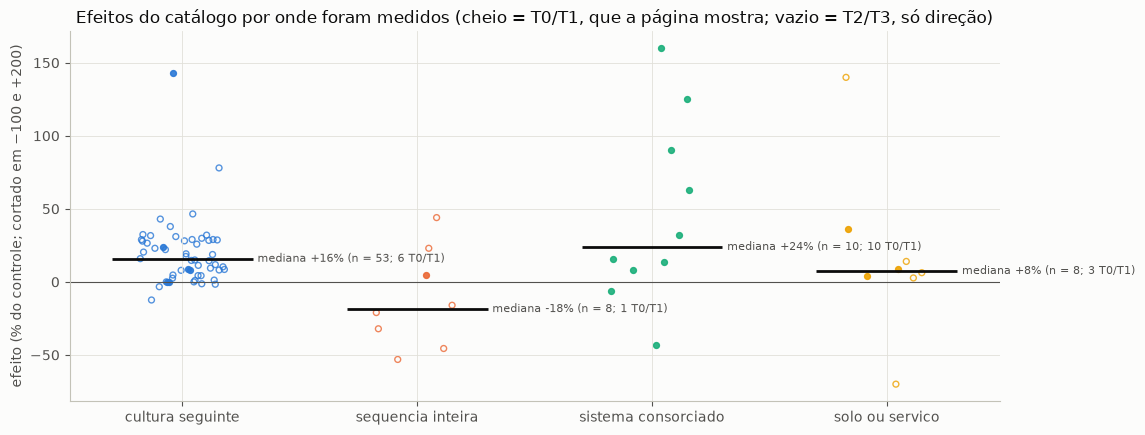

Efeito em % por grau (cartões de cultura seguinte):


,count,mean,std,min,25%,50%,75%,max
grau,,,,,,,,
A,7.0,20.7,6.9,9.4,17.3,20.4,25.7,28.9
B,22.0,13.5,13.2,-12.4,4.3,12.9,22.8,43.0
C,20.0,22.6,19.6,-3.3,8.0,27.2,31.2,78.0
D,4.0,38.0,70.1,0.0,0.8,4.6,41.9,143.0


Referências com mais cartões:


,cartões
0,
Mudare et al. 2025,21
Zhao et al. 2022,14
Franke et al. 2018,11
Kluger et al. 2025,8
Azambuja & Degrande 2014,8
Bowles et al. 2020,5
Mudare et al. 2022,5
da Luz et al. 2023,4
Melo et al. 2013,4


In [28]:
P = K.dropna(subset=["pct"])
grupos = [g for g in ["cultura_seguinte", "sequencia_inteira", "sistema_consorciado", "solo_ou_servico"] if (P["efeito.na"] == g).any()]
fig, ax = plt.subplots(figsize=(12, 4.8))
for i, gname in enumerate(grupos):
    y = P[P["efeito.na"] == gname].pct.clip(-100, 200)
    x = np.full(len(y), i) + np.random.default_rng(0).uniform(-0.18, 0.18, len(y))
    mostra = P[P["efeito.na"] == gname].transferencia.isin(["T0", "T1"]).values
    ax.scatter(x[~mostra], y[~mostra], s=18, facecolor="none", edgecolor=CAT[i], alpha=0.8)
    ax.scatter(x[mostra], y[mostra], s=18, color=CAT[i], alpha=0.9)
    ax.hlines(y.median(), i - 0.3, i + 0.3, color="#0b0b0b", lw=2)
    ax.text(i + 0.32, y.median(), f"mediana {y.median():+.0f}% (n = {len(y)}; {mostra.sum()} T0/T1)", va="center", fontsize=8, color="#52514e")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(range(len(grupos)))
ax.set_xticklabels([g.replace("_", " ") for g in grupos])
ax.set_ylabel("efeito (% do controle; cortado em −100 e +200)")
ax.set_title("Efeitos do catálogo por onde foram medidos (cheio = T0/T1, que a página mostra; vazio = T2/T3, só direção)")
plt.show()
print("Efeito em % por grau (cartões de cultura seguinte):")
display(P[P["efeito.na"] == "cultura_seguinte"].groupby("grau").pct.describe().round(1))
print("Referências com mais cartões:")
display(K.referencia_texto.str.extract(r"^([^,;(]+?\d{4}[a-z]?)")[0].value_counts().head(10).rename("cartões").to_frame())

**Leitura:**
- **147 cartões; 72 com lugar; 48 DOIs distintos; 81 com efeito em %.**
  - Graus: A 9, B 44, C 76, D 18.
  - Transferência: T0 36, T1 7, T2 73, T3 31.
- **Na página, só 29 cartões saem com número** (24 T0 e 5 T1). Os 104 T2/T3 dão só a direção. Outros 14 T0/T1 também
  ficam sem número (efeito sem valor central em % ou regra que manda esconder o número).
- **Das 11 regras fixas do motor, só uma tem número:** o +24% (+2 a +49) da leguminosa antes do cereal (T1), "no ano
  colhido, contra cereal solteiro". As regras negativas e de "sem bônus" (da Luz, Pacheco, Melo) saem sem ganho.
- **19 cartões vêm de ensaio irrigado** e saem marcados na página.
- **Nenhum dos 64 cartões de rotação é T0.** Não há rotação no tempo medida no semiárido brasileiro. Os números de
  rotação que valem no sertão são os 5 T1.
- **Na cultura seguinte, a mediana dos efeitos é de +13% (grau B) a +27% (grau C)**, e de +20% no grau A (Zhao 2022,
  global, T2).
- **Três meta-análises sustentam 46 cartões:** Mudare 2025 (21), Zhao 2022 (14) e Franke 2018 (11).

## 7. NASA GPM IMERG: o regime de chuva de cada município

**Ficha técnica**
- **Fonte:** chuva diária IMERG V07 (0,1°), via NASA POWER, de 01/01/1998 a 14/09/2026, recortada no Nordeste e agregada
  por município (média das células com centro dentro do município; quem não tem centro de célula dentro usa a célula
  mais próxima do ponto interno). **O IMERG Final V07 termina em 30/09/2025; o que vem depois é o Late (preliminar)**
  (revisão A16). A climatologia do regime usa só anos completos, 1998–2025.
- **Regime:** os 4 meses seguidos mais chuvosos da climatologia (`analogos_aprofundado/regime_chuva_ne_mun.csv`). O NE
  tem três regimes:
  - **quadra do norte** (jan–abr, fev–mai): a mesma regra do CE;
  - **litoral leste** (mar–jun, abr–jul): chuva de outono e inverno;
  - **Cerrado e sul da BA** (out–jan, nov–fev, dez–mar): chuva de primavera e verão.

**No protótipo (`motor.regime`):**
- "Estação chuvosa típica" do município, com a chuva da estação e a fração do ano;
- fora da quadra do norte, o aviso de que os portões de 19/mar e 30/abr e as datas do plano foram calibrados no sertão
  do CE;
- **na faixa costeira leste** (até ~20 km do mar, do RN ao sul de Calcanhar até o sul da BA), o aviso de que **o IMERG capta só 39–72% da chuva
  medida** (viabilidade dos artigos, bloco B2) e de que ali as janelas do ZARC guiam as datas;
- a ordem em que o motor procura o 1º decêndio do ZARC começa 3 meses antes do 1º mês da estação (seção 2).

In [29]:
def grupo_regime(m0):
    return "quadra do norte" if m0 <= 2 else ("litoral leste" if m0 <= 6 else "Cerrado e sul da BA")


REGIMES = ["quadra do norte", "litoral leste", "Cerrado e sul da BA"]
COR_REG = dict(zip(REGIMES, [CAT[0], CAT[1], CAT[2]]))
RG7 = M.REG.copy()  # regime_chuva_ne_mun.csv, indexado pelo código IBGE
RG7["uf"] = UFMUN.reindex(RG7.index)
RG7["regime"] = RG7.mes_inicio_estacao.map(grupo_regime)
RG7["lon"] = MUN.set_index("cod").lon.reindex(RG7.index)
EST = ["out–jan", "nov–fev", "dez–mar", "jan–abr", "fev–mai", "mar–jun", "abr–jul"]
print(f"{len(RG7)} municípios com regime. Estação típica (4 meses mais chuvosos) por UF:")
display(pd.crosstab(RG7.uf, RG7.estacao).reindex(index=UF_ORDEM, columns=[e for e in EST if e in set(RG7.estacao)], fill_value=0)
        .assign(total=lambda d: d.sum(1)))
display(pd.crosstab(RG7.uf, RG7.regime).reindex(index=UF_ORDEM, columns=REGIMES, fill_value=0).T)
print("Regra do início da chuva por regime (seção 8):")
display(RG7.groupby("regime").regra.first().reindex(REGIMES).to_frame())
print("Chuva da estação (mm, IMERG) e fração da chuva do ano que cai nela, por regime:")
display(RG7.groupby("regime")[["chuva_estacao_media_mm", "fracao_do_ano"]].describe()
        .loc[REGIMES, (slice(None), ["min", "25%", "50%", "75%", "max"])].round(2))

1794 municípios com regime. Estação típica (4 meses mais chuvosos) por UF:

estacao,out–jan,nov–fev,dez–mar,jan–abr,fev–mai,mar–jun,abr–jul,total
uf,,,,,,,,
MA,0,0,24,132,61,0,0,217
PI,0,8,73,141,2,0,0,224
CE,0,0,0,147,37,0,0,184
RN,0,0,0,82,29,53,3,167
PB,0,0,0,131,16,65,11,223
PE,0,0,1,76,12,92,4,185
AL,0,0,0,14,24,64,0,102
SE,0,0,0,2,53,20,0,75
BA,12,294,14,49,48,0,0,417


uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
regime,,,,,,,,,
quadra do norte,193,143,184,111,147,88,38,55,97
litoral leste,0,0,0,56,76,96,64,20,0
Cerrado e sul da BA,24,81,0,0,0,1,0,0,320


Regra do início da chuva por regime (seção 8):


,regra
regime,
quadra do norte,quadra do norte: busca de 1/dez a 31/mai; chuv...
litoral leste,busca de 2 meses antes da estação até o fim de...
Cerrado e sul da BA,busca de 2 meses antes da estação até o fim de...


Chuva da estação (mm, IMERG) e fração da chuva do ano que cai nela, por regime:


chuva_estacao_media_mm                                fracao_do_ano                        
                                       min     25%    50%     75%     max           min   25%   50%   75%   max
regime                                                                                                         
quadra do norte                      199.0  394.75  605.5  826.25  1579.0          0.48  0.65  0.72  0.75  0.81
litoral leste                        255.0  364.75  448.5  557.25   836.0          0.56  0.62  0.63  0.65  0.69
Cerrado e sul da BA                  212.0  379.50  452.0  569.25   942.0          0.48  0.61  0.65  0.67  0.72

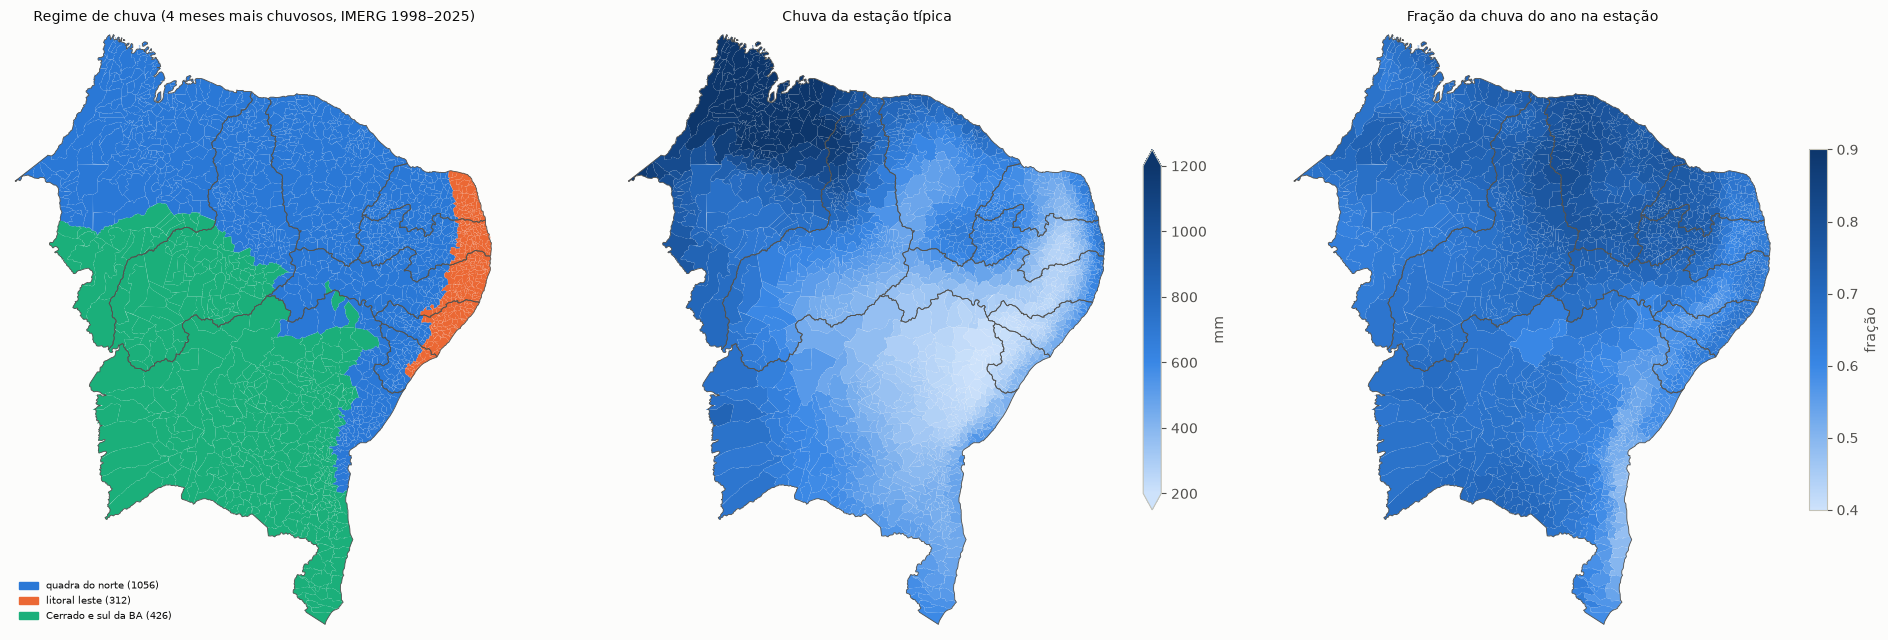

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))
mapa_ne(axs[0], RG7.regime, "Regime de chuva (4 meses mais chuvosos, IMERG 1998–2025)", categorias=COR_REG)
mapa_ne(axs[1], RG7.chuva_estacao_media_mm, "Chuva da estação típica", vmin=200, vmax=1200, rotulo="mm")
mapa_ne(axs[2], RG7.fracao_do_ano, "Fração da chuva do ano na estação", vmin=0.4, vmax=0.9, rotulo="fração")
plt.tight_layout()
plt.show()

In [31]:
# os avisos que o motor dá (motor.regime): fora da quadra do norte e no litoral leste (ponto interno do município)
RG7["fora_da_quadra"] = ~(RG7.mes_inicio_estacao <= 2)
RG7["aviso_imerg_leste"] = RG7.index.isin(M.LESTE)  # até ~20 km (0,2°) da costa leste, do RN ao sul de Calcanhar até a BA (motor._leste_costeiro)
av = pd.DataFrame({"municípios": RG7.uf.value_counts().reindex(UF_ORDEM),
                   "fora da quadra do norte": RG7.groupby("uf").fora_da_quadra.sum().reindex(UF_ORDEM),
                   "aviso do IMERG no litoral leste": RG7.groupby("uf").aviso_imerg_leste.sum().reindex(UF_ORDEM)}).fillna(0).astype(int)
display(av.T.assign(NE=lambda d: d.sum(1)))
print("Aviso do litoral leste × regime do município:")
display(pd.crosstab(RG7.aviso_imerg_leste.map({True: "com aviso", False: "sem aviso"}), RG7.regime).reindex(columns=REGIMES, fill_value=0))
print(f"Exemplo (motor.regime, Quixadá): {M.regime('2311306', 'CE', -39.03)['texto']}")
rec = MUN[MUN.municipio == "Recife"].iloc[0]
print(f"Exemplo (motor.regime, Recife): {M.regime(rec.cod, rec.uf, rec.lon)['texto']}")

uf,MA,PI,CE,RN,PB,PE,AL,SE,BA,NE
municípios,217,224,184,167,223,185,102,75,417,1794
fora da quadra do norte,24,81,0,56,76,97,64,20,320,738
aviso do IMERG no litoral leste,0,0,0,26,17,25,30,26,58,182


Aviso do litoral leste × regime do município:


regime,quadra do norte,litoral leste,Cerrado e sul da BA
aviso_imerg_leste,,,
com aviso,52,115,15
sem aviso,1004,197,411


Exemplo (motor.regime, Quixadá): Estação chuvosa típica: jan–abr (568 mm, 75% do ano; IMERG).
Exemplo (motor.regime, Recife): Estação chuvosa típica: mar–jun (668 mm, 64% do ano; IMERG). Não é a quadra do norte: os portões de 19/mar e 30/abr e as datas do plano foram calibrados no sertão do CE e precisam ser ajustados aqui. Atenção: no litoral leste o IMERG subestima a chuva de outono e inverno (capta 39–72% do medido); aqui, as janelas do ZARC são o guia das datas.


**Leitura:**
- **O NE tem três regimes de chuva:**
  - **quadra do norte** (jan–abr ou fev–mai) em 1.056 municípios: o CE inteiro, 193 do MA, 147 da PB, 143 do PI e 111 do
    RN;
  - **litoral leste** (mar–jun ou abr–jul) em 312: PE 96, PB 76, AL 64, RN 56 e SE 20;
  - **Cerrado e sul da BA** (out–jan, nov–fev ou dez–mar) em 426: 320 da BA, 81 do PI, 24 do MA e 1 de PE.
- **A estação concentra a chuva do ano:** mediana de 72% na quadra, 63% no litoral leste e 65% no Cerrado. A chuva da
  estação tem mediana de 606 mm na quadra (199 a 1.579), 449 mm no litoral leste e 452 mm no Cerrado.
- **738 municípios (41%) não estão na quadra do norte.** Neles, a página avisa que os portões de 19/mar e 30/abr e as
  datas do plano vêm do sertão do CE.
- **182 municípios recebem o aviso de que o IMERG capta só 39–72% da chuva medida:** os que ficam a até ~20 km da costa
  leste, do RN (ao sul de Calcanhar) ao sul da BA (RN 26, PB 17, PE 25, AL 30, SE 26 e BA 58). É onde o achado foi
  medido (estações a menos de 20 km do mar). O aviso vai pela distância à costa, não pelo regime: 115 deles têm regime
  de litoral leste, 52 de quadra e 15 do Cerrado e sul da BA.
- **No produto:** a regra do início da chuva e a ordem em que o motor procura a data do ZARC dependem do regime. No
  litoral leste, o IMERG subestima a chuva, e as datas vêm do ZARC.

## 8. NASA GPM IMERG: quando a estação começa e o El Niño no próprio município

**Ficha técnica**
- **Fonte:** a mesma chuva diária IMERG V07 da seção 7 (`analogos_aprofundado/onset_ne_mun.csv`).
- **Regra de início** (agronômica, no espírito de Waha et al. 2012): o 1º dia com ≥ 20 mm em 3 dias **sem** veranico
  de ≥ 10 dias secos (< 1 mm) nos 30 dias seguintes. A busca depende do regime:
  - **quadra do norte (jan–abr, fev–mai): de 1/dez a 31/mai, como no CE**; a chuva da estação é a de fev–mai;
  - outros regimes: de 2 meses antes do 1º mês da estação até o fim do 4º mês; a chuva da estação é a dos 4 meses.
- **Coluna da chuva:** `chuva_estacao_mm`, que alimenta a perspectiva do El Niño.
- **Produto:** o IMERG Final V07 termina em 30/09/2025; o arquivo vai até 14/09/2026 com o Late depois disso. **A estação
  de 2026 é preliminar** em todos os regimes (revisão A16).
- **El Niño forte:** ONI de OND–NDJ ≥ 1,5 (`el_nino_2026/eventos.csv`; seção 9). Na série IMERG entram 2010, 2016 e
  2024 e, no litoral leste (estação que começa em mar–abr), também 1998.

**No protótipo:**
- `motor.inicio_estacao`: o início típico (mediana dos anos **sem** El Niño forte), a faixa p10–p90, a % de anos sem
  início e, **sem negrito**, a diferença nos anos de El Niño forte, com os anos listados (revisões A17 e M25);
- `motor._perspectiva_municipal`: nos El Niños fortes da série, em quantos a chuva da estação do município ficou no terço
  mais seco. Com ONI ≥ 1,5, o alerta acende se isso aconteceu em pelo menos 2 e em ≥ 2/3 dos anos; senão, "sinal fraco".

In [32]:
FORTES = M.FORTES
O = M.ONS.copy()
O["uf"] = O.cod.map(UFMUN)
O["regime"] = O.mes_inicio_estacao.map(grupo_regime)
O["dia"] = np.nan
for m0, idx in O.groupby("mes_inicio_estacao").groups.items():
    s_ = O.loc[idx, "inicio_chuva"]
    O.loc[idx, "dia"] = pd.Series(np.asarray(M._dia_estacao(s_, m0), dtype=float), index=idx).where(s_.notna())
O["forte"] = O.ano.isin(FORTES)
O25 = O[O.ano <= 2025]  # como o motor: a estação de 2026 (IMERG Late, preliminar) fica fora das estatísticas
print(f"{O.cod.nunique()} municípios × estações; anos por regime:")
display(O.groupby("regime").agg(municipios=("cod", "nunique"), primeiro=("ano", "min"), ultimo=("ano", "max"),
                                anos=("ano", "nunique"), sem_inicio_pct=("inicio_chuva", lambda s: round(s.isna().mean() * 100, 1)),
                                anos_el_nino_forte=("ano", lambda s: ", ".join(map(str, sorted(set(s) & FORTES))))).reindex(REGIMES))


def janela(a, m):
    """Janela de busca da estação 'a' (cópia da regra de scripts/preparar_prototipo_nordeste.py, para datar o produto)."""
    if m <= 2:
        return pd.Timestamp(a - 1, 12, 1), pd.Timestamp(a, 5, 31)
    ano_m0 = a if m <= 6 else a - 1
    return (pd.Timestamp(ano_m0, m, 1) - pd.DateOffset(months=2),
            pd.Timestamp(ano_m0, m, 1) + pd.DateOffset(months=4) - pd.Timedelta(days=1))


FIM_FINAL = pd.Timestamp("2025-09-30")
prod = []
for m0 in sorted(O.mes_inicio_estacao.unique()):
    ult = int(O[O.mes_inicio_estacao == m0].ano.max())
    ini, fim = janela(ult, m0)
    prod.append({"estação": RG7[RG7.mes_inicio_estacao == m0].estacao.iloc[0], "municípios": int((RG7.mes_inicio_estacao == m0).sum()),
                 "última estação": ult, "busca": f"{ini:%d/%m/%Y}–{fim:%d/%m/%Y}",
                 "% dos dias depois do Final (Late, preliminar)": round(100 * max(0, (fim - max(ini - pd.Timedelta(days=1), FIM_FINAL)).days) / ((fim - ini).days + 1))})
print("Última estação de cada regime e quanto dela é IMERG Late (preliminar):")
display(pd.DataFrame(prod).set_index("estação"))

1794 municípios × estações; anos por regime:


,municipios,primeiro,ultimo,anos,sem_inicio_pct,anos_el_nino_forte
regime,,,,,,
quadra do norte,1056,1999,2026,28,5.0,"2010, 2016, 2024"
litoral leste,312,1998,2026,29,9.8,"1998, 2010, 2016, 2024"
Cerrado e sul da BA,426,1999,2026,28,16.2,"2010, 2016, 2024"


Última estação de cada regime e quanto dela é IMERG Late (preliminar):


,municípios,última estação,busca,"% dos dias depois do Final (Late, preliminar)"
estação,,,,
jan–abr,774,2026,01/12/2025–31/05/2026,100
fev–mai,282,2026,01/12/2025–31/05/2026,100
mar–jun,294,2026,01/01/2026–30/06/2026,100
abr–jul,18,2026,01/02/2026–31/07/2026,100
out–jan,12,2026,01/08/2025–31/01/2026,67
nov–fev,302,2026,01/09/2025–28/02/2026,83
dez–mar,112,2026,01/10/2025–31/03/2026,100


Conferência com motor.inicio_estacao: 1794 de 1794 municípios com a mesma mediana e a mesma diferença


,n,ausentes_%,média,dp,min,5%,25%,mediana,75%,95%,max,assimetria
mediana,1794.0,0.0,9.46,43.24,-75.0,-64.00,-21.50,16.00,47.38,73.00,97.50,-0.19
p10,1794.0,0.0,-21.71,32.87,-93.8,-79.33,-29.70,-12.40,3.80,20.93,43.20,-0.57
p90,1794.0,0.0,45.43,46.61,-60.6,-31.60,7.50,45.70,85.60,112.14,143.00,-0.16
faixa_p10_p90,1794.0,0.0,67.14,24.63,11.4,25.46,49.42,68.60,85.80,105.80,133.00,-0.01
sem_inicio_pct,1794.0,0.0,8.73,12.80,0.0,0.00,0.00,3.57,14.29,37.04,77.78,1.93
dif_el_nino,1791.0,0.2,-2.84,32.56,-92.0,-57.00,-23.50,-4.00,15.50,54.50,91.00,0.20


Por regime e UF (medianas dos municípios; dia negativo = ano anterior):


municipios inicio_mediano  faixa_p10_p90  sem_inicio_pct
regime              uf                                                          
quadra do norte     AL          38          01/03           95.9            22.2
                    BA          97          15/02          104.9            18.5
                    CE         184          16/01           53.4             0.0
                    MA         193          13/12           27.1             0.0
                    PB         147          22/01           72.1             0.0
                    PE          88          21/01           78.6             5.6
                    PI         143          20/12           39.3             0.0
                    RN         111          26/01           70.0             0.0
                    SE          55          02/03           98.0            22.2
litoral leste       AL          64          15/03           90.0            14.3
                    PB          76          28/02           84.1             7.1
                    PE          96          03/03           84.4            10.7
                    RN          56          27/02           77.2             3.6
                    SE          20          17/03           92.8             7.1
Cerrado e sul da BA BA         320          12/11           67.0            14.8
                    MA          24          24/10           38.1             0.0
                    PE           1          30/12           68.4            18.5
                    PI          81          13/11           63.4             0.0

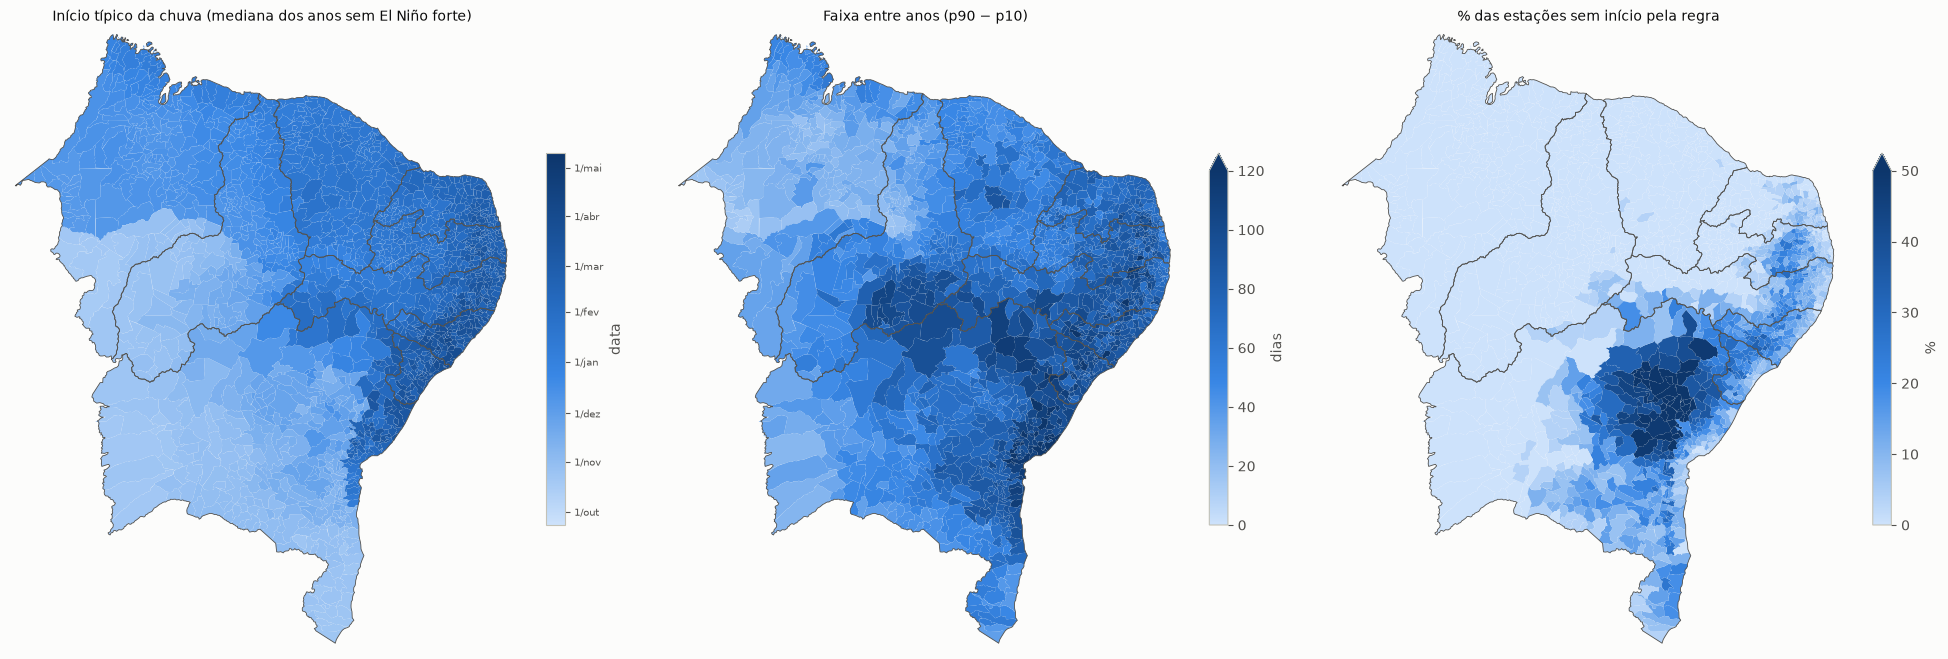

In [33]:
dem = O25[~O25.forte].groupby("cod").dia
PM8 = pd.DataFrame({"mediana": dem.median(), "p10": dem.quantile(0.1), "p90": dem.quantile(0.9),
                    "sem_inicio_pct": O25.groupby("cod").inicio_chuva.apply(lambda s: s.isna().mean() * 100),
                    "dif_el_nino": O25[O25.forte].groupby("cod").dia.median() - dem.median()})
PM8["faixa_p10_p90"] = PM8.p90 - PM8.p10
PM8["uf"], PM8["regime"] = PM8.index.map(UFMUN), RG7.regime.reindex(PM8.index)
# conferência: as mesmas datas que a página mostra (motor.inicio_estacao) nos 1.794 municípios
ok = 0
for cod in PM8.index:
    r = M.inicio_estacao(cod)
    dif = PM8.at[cod, "dif_el_nino"]
    ok += (r["mediana"] == M.data_doy(PM8.at[cod, "mediana"])) and (r["dif_el_nino_dias"] == (None if np.isnan(dif) else int(round(dif))))
print(f"Conferência com motor.inicio_estacao: {ok} de {len(PM8)} municípios com a mesma mediana e a mesma diferença")
display(descreve(PM8[["mediana", "p10", "p90", "faixa_p10_p90", "sem_inicio_pct", "dif_el_nino"]]))
tab8 = PM8.groupby(["regime", "uf"]).agg(municipios=("mediana", "size"), inicio_mediano=("mediana", "median"),
                                         faixa_p10_p90=("faixa_p10_p90", "median"), sem_inicio_pct=("sem_inicio_pct", "median"))
tab8["inicio_mediano"] = tab8.inicio_mediano.map(M.data_doy)
print("Por regime e UF (medianas dos municípios; dia negativo = ano anterior):")
display(tab8.reindex(REGIMES, level=0).round(1))
TK8 = [-92, -61, -31, 1, 32, 60, 91, 121]
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))
mapa_ne(axs[0], PM8.mediana, "Início típico da chuva (mediana dos anos sem El Niño forte)", vmin=-100, vmax=130, rotulo="data",
        ticks=TK8, rotulos_ticks=["1/out", "1/nov", "1/dez", "1/jan", "1/fev", "1/mar", "1/abr", "1/mai"])
mapa_ne(axs[1], PM8.faixa_p10_p90, "Faixa entre anos (p90 − p10)", vmin=0, vmax=120, rotulo="dias")
mapa_ne(axs[2], PM8.sem_inicio_pct, "% das estações sem início pela regra", vmin=0, vmax=50, rotulo="%")
plt.tight_layout()
plt.show()

In [34]:
# a janela do ZARC começa perto do início da chuva? (1º decêndio com risco de 20%, seção 2, × início típico do IMERG)
zc = pd.concat([PM8.mediana, ZP.d20.astype(float)], axis=1, keys=["inicio", "zarc20"]).dropna()
rho_z = stats.spearmanr(zc.inicio, zc.zarc20)
gapz = zc.zarc20 - zc.inicio
print(f"Início típico (IMERG) × 1º decêndio com 20% (ZARC), {len(zc)} municípios: Spearman {rho_z[0]:+.2f}; o ZARC começa "
      f"em mediana {gapz.median():+.0f} dias depois do início típico (p10 {gapz.quantile(0.1):+.0f}, p90 {gapz.quantile(0.9):+.0f})")
display(gapz.groupby(PM8.regime.reindex(gapz.index)).describe()[["count", "25%", "50%", "75%"]].reindex(REGIMES).round(0))

Início típico (IMERG) × 1º decêndio com 20% (ZARC), 1658 municípios: Spearman +0.83; o ZARC começa em mediana +12 dias depois do início típico (p10 -6, p90 +42)


,count,25%,50%,75%
regime,,,,
quadra do norte,1026.0,6.0,14.0,24.0
litoral leste,311.0,-2.0,4.0,14.0
Cerrado e sul da BA,321.0,6.0,13.0,30.0


Início nos El Niños fortes − demais anos, por município (1000 permutações dos anos em cada regime):


dif_el_nino,antes (> 5 dias),igual (±5 dias),depois (> 5 dias),"p < 0,05 (%)"
uf,,,,
MA,14,62,141,14.7
PI,27,82,115,4.5
CE,135,12,37,0.5
RN,133,18,16,5.4
PB,182,21,20,4.0
PE,149,13,23,13.5
AL,83,13,6,17.6
SE,65,6,4,30.7
BA,96,18,300,25.9


NE: 235 de 1791 municípios com p < 0,05 (13.1%; ao acaso se esperam 5%). Quixadá: +25 dias, p = 0.23; anos {2010: '19/03', 2016: '06/01', 2024: '12/02'}
Os anos, um a um: início no El Niño forte − início típico do município (mediana dos municípios, dias):


ano,1998,2010,2016,2024
uf,,,,
MA,NaN,-1.0,18.0,10.0
PI,NaN,-11.0,17.0,6.0
CE,NaN,-12.0,-11.0,4.0
RN,6.0,-19.0,-32.0,-4.0
PB,24.0,-16.0,-34.0,-16.0
PE,31.0,-10.0,-46.0,-14.0
AL,-20.0,-54.0,-62.0,4.0
SE,6.0,-64.0,-64.0,-27.0
BA,NaN,-20.0,40.0,56.0


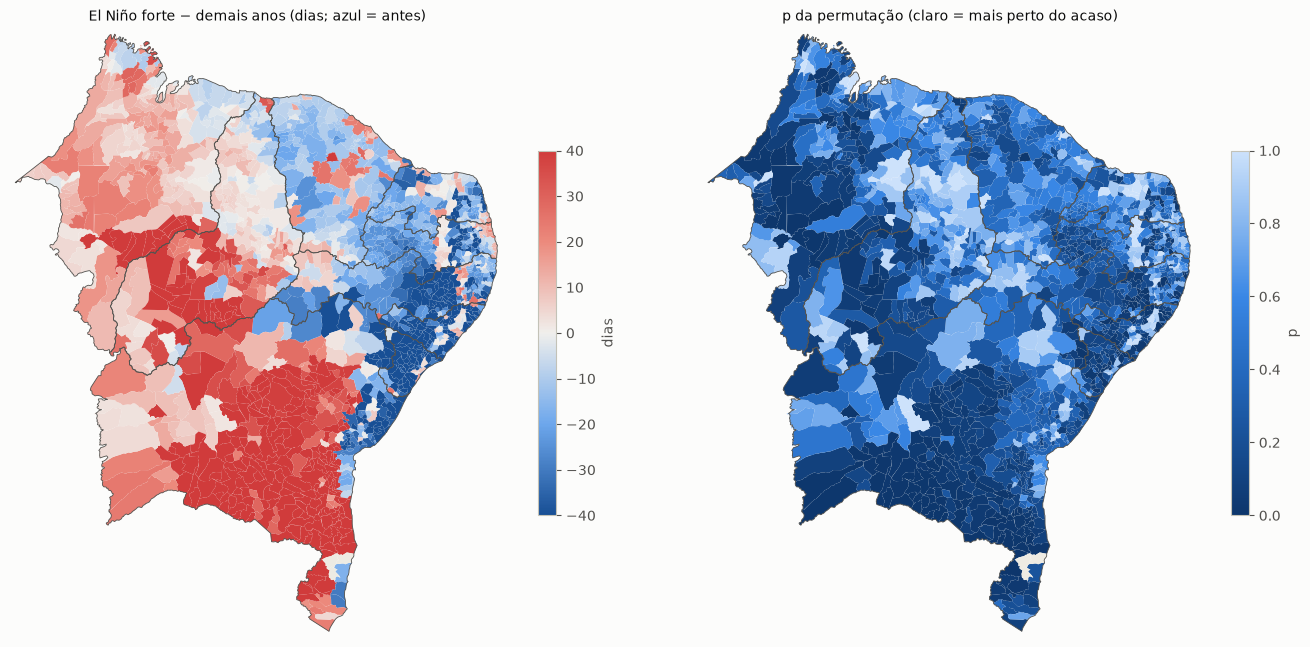

In [35]:
# El Niño forte e o início: a diferença do próprio município, os anos e o teste de permutação (revisão A17)
rng = np.random.default_rng(0)
NPERM = 1000
pval = pd.Series(np.nan, index=PM8.index)
for m0, gq in O25.groupby("mes_inicio_estacao"):
    pv = gq.pivot(index="cod", columns="ano", values="dia")
    f_ = np.isin(pv.columns.values, list(FORTES))
    Xv = pv.values
    obs = np.nanmedian(Xv[:, f_], 1) - np.nanmedian(Xv[:, ~f_], 1)
    cont = np.zeros(len(Xv))
    for _ in range(NPERM):
        fp = np.zeros(len(f_), bool)
        fp[rng.choice(len(f_), f_.sum(), replace=False)] = True
        cont += np.abs(np.nanmedian(Xv[:, fp], 1) - np.nanmedian(Xv[:, ~fp], 1)) >= np.abs(obs) - 1e-9
    pval[pv.index] = np.where(np.isnan(obs), np.nan, (cont + 1) / (NPERM + 1))
PM8["p_perm"] = pval
sinal = pd.cut(PM8.dif_el_nino, [-999, -5, 5, 999], labels=["antes (> 5 dias)", "igual (±5 dias)", "depois (> 5 dias)"])
t8 = pd.crosstab(PM8.uf, sinal).reindex(UF_ORDEM)
t8["p < 0,05 (%)"] = (PM8.p_perm < 0.05).groupby(PM8.uf).mean().reindex(UF_ORDEM).mul(100).round(1)
print(f"Início nos El Niños fortes − demais anos, por município ({NPERM} permutações dos anos em cada regime):")
display(t8)
print(f"NE: {int((PM8.p_perm < 0.05).sum())} de {int(PM8.p_perm.notna().sum())} municípios com p < 0,05 "
      f"({(PM8.p_perm < 0.05).mean():.1%}; ao acaso se esperam 5%). Quixadá: {PM8.at['2311306', 'dif_el_nino']:+.0f} dias, "
      f"p = {PM8.at['2311306', 'p_perm']:.2f}; anos {M.inicio_estacao('2311306')['anos_el_nino_forte']}")
anos_f = sorted(set(O25[O25.forte].ano))
an = O25[O25.forte].assign(anom=lambda d: d.dia - d.cod.map(PM8.mediana))
print("Os anos, um a um: início no El Niño forte − início típico do município (mediana dos municípios, dias):")
display(an.pivot_table(index="uf", columns="ano", values="anom", aggfunc="median").reindex(UF_ORDEM).round(0))
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
mapa_ne(axs[0], PM8.dif_el_nino.clip(-40, 40), "El Niño forte − demais anos (dias; azul = antes)", cmap=DIV, vmin=-40, vmax=40, rotulo="dias")
mapa_ne(axs[1], PM8.p_perm, "p da permutação (claro = mais perto do acaso)", cmap=SEQ.reversed(), vmin=0, vmax=1, rotulo="p")
plt.tight_layout()
plt.show()

ONI de ago–out/2026 = +2.46 (≥ 1,5): o motor avalia o alerta em cada município. Nível por UF:


nivel,alerta,sinal fraco,NE
uf,,,
MA,182,35,217
PI,152,72,224
CE,182,2,184
RN,146,21,167
PB,127,96,223
PE,47,138,185
AL,0,102,102
SE,0,75,75
BA,86,331,417


Em quantos El Niños fortes a chuva da estação ficou no terço mais seco do município:


inferior,0,1,2,3
n_fortes,,,,
3 anos,23,601,771,87
4 anos,0,25,223,64


Chance de acender o alerta só por acaso (anos independentes, terço = 1/3): com 3 anos, 26%; com 4 anos, 11%


Sensibilidade: o motor tira a estação de 2026 (IMERG Late, preliminar) e acende o alerta em 922 municípios; com ela na série seriam 955 (33 mudam de nível)
Chuva da estação nos El Niños fortes: % do normal (mediana dos municípios) e % dos municípios no terço mais seco:


% do normal                      % no terço seco                    
ano        1998   2010   2016   2024            1998   2010   2016  2024
uf                                                                      
MA          NaN   75.0   69.0  105.0             NaN   81.0   98.0  13.0
PI          NaN   83.0   67.0   99.0             NaN   83.0   72.0  27.0
CE          NaN   61.0   61.0   94.0             NaN  100.0  100.0  21.0
RN         39.0   69.0   63.0  111.0            98.0   98.0   90.0  15.0
PB         28.0   72.0   79.0   95.0           100.0   93.0   58.0  17.0
PE         19.0  118.0   74.0   99.0           100.0   25.0   70.0  25.0
AL         23.0  151.0   46.0  141.0           100.0    0.0  100.0   0.0
SE         85.0  150.0   29.0  113.0            45.0    0.0  100.0   0.0
BA          NaN   56.0  100.0  132.0             NaN   75.0   44.0   3.0

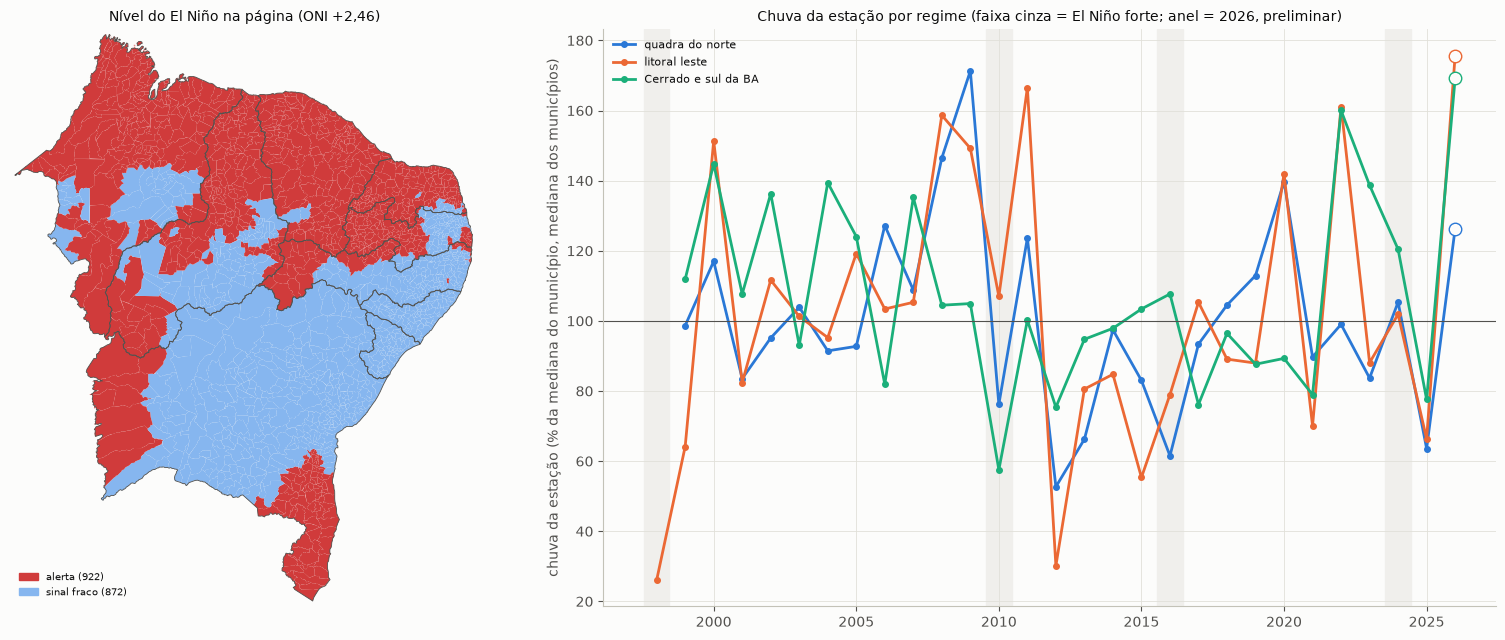

Chuva da estação em % da mediana do município (mediana dos municípios), anos de El Niño forte e 2026 (preliminar):


ano,1998,2010,2016,2024,2026
regime,,,,,
quadra do norte,NaN,76.0,62.0,105.0,126.0
litoral leste,26.0,107.0,79.0,102.0,176.0
Cerrado e sul da BA,NaN,58.0,108.0,120.0,169.0


In [36]:
# El Niño forte e a chuva da estação no próprio município (motor._perspectiva_municipal)
oni_ult = M.EN["ONI_ultimo"][1]
lin = []
for cod in MUN.cod:
    pm = M.PERSP_MUN.get(cod)
    if oni_ult >= 1.5 and pm and pm["anos"]:
        niv = "alerta" if pm["inferior"] >= max(2, math.ceil(len(pm["anos"]) * 2 / 3)) else "sinal fraco"
    else:
        niv = "sem alerta" if pm else "sem dado"
    lin.append({"cod": cod, "nivel": niv, "inferior": pm["inferior"] if pm else np.nan, "n_fortes": len(pm["anos"]) if pm else np.nan})
NV = pd.DataFrame(lin).set_index("cod")
NV["uf"] = UFMUN
print(f"ONI de ago–out/2026 = {oni_ult:+.2f} (≥ 1,5): o motor avalia o alerta em cada município. Nível por UF:")
display(pd.crosstab(NV.uf, NV.nivel, margins=True, margins_name="NE").reindex(UF_ORDEM + ["NE"]))
print("Em quantos El Niños fortes a chuva da estação ficou no terço mais seco do município:")
display(pd.crosstab(NV.n_fortes.astype("Int64").astype(str) + " anos", NV.inferior.astype("Int64")))
acaso = {k: stats.binom.sf(max(2, math.ceil(k * 2 / 3)) - 1, k, 1 / 3) for k in (3, 4)}
print("Chance de acender o alerta só por acaso (anos independentes, terço = 1/3): "
      + "; ".join(f"com {k} anos, {p:.0%}" for k, p in acaso.items()))
rows, com26 = [], {}
for cod, gq in O.dropna(subset=["chuva_estacao_mm"]).groupby("cod"):
    s_ = gq.set_index("ano").chuva_estacao_mm
    t1, med = s_.quantile(1 / 3), s_[~s_.index.isin(FORTES)].median()
    for a in sorted(FORTES & set(s_.index)):
        rows.append({"cod": cod, "uf": UFMUN[cod], "ano": a, "pct": 100 * s_[a] / med, "terco_seco": s_[a] <= t1})
    an1 = sorted(FORTES & set(s_.index))  # sensibilidade: a mesma regra COM a estação de 2026 (o motor a tira)
    com26[cod] = "alerta" if sum(s_[a] <= t1 for a in an1) >= max(2, math.ceil(len(an1) * 2 / 3)) else "sinal fraco"
AN = pd.DataFrame(rows)
com26 = pd.Series(com26)
print(f"Sensibilidade: o motor tira a estação de 2026 (IMERG Late, preliminar) e acende o alerta em {int((NV.nivel == 'alerta').sum())} "
      f"municípios; com ela na série seriam {int((com26 == 'alerta').sum())} ({int((com26 != NV.nivel.reindex(com26.index)).sum())} mudam de nível)")
print("Chuva da estação nos El Niños fortes: % do normal (mediana dos municípios) e % dos municípios no terço mais seco:")
display(pd.concat({"% do normal": AN.pivot_table(index="uf", columns="ano", values="pct", aggfunc="median"),
                   "% no terço seco": AN.pivot_table(index="uf", columns="ano", values="terco_seco", aggfunc="mean") * 100},
                  axis=1).reindex(UF_ORDEM).round(0))
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.4]})
mapa_ne(axs[0], NV.nivel, "Nível do El Niño na página (ONI +2,46)", categorias={"alerta": "#d03b3b", "sinal fraco": "#86b6ef", "sem dado": CINZA})
O["pct_normal"] = O.chuva_estacao_mm / O.cod.map(O25[~O25.forte].groupby("cod").chuva_estacao_mm.median()) * 100
serie = O.groupby(["regime", "ano"]).pct_normal.median().unstack(0)[REGIMES]
for a in anos_f:
    axs[1].axvspan(a - 0.45, a + 0.45, color="#f0efec", zorder=0)
for r_ in REGIMES:
    s_ = serie[r_].dropna()
    axs[1].plot(s_.index, s_.values, color=COR_REG[r_], marker="o", ms=4, label=r_)
    axs[1].plot([s_.index[-1]], [s_.values[-1]], marker="o", ms=9, mfc="#fcfcfb", mec=COR_REG[r_], ls="none")
axs[1].axhline(100, color="#52514e", lw=0.8)
axs[1].set_ylabel("chuva da estação (% da mediana do município, mediana dos municípios)")
axs[1].set_title("Chuva da estação por regime (faixa cinza = El Niño forte; anel = 2026, preliminar)", fontsize=10)
axs[1].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()
print("Chuva da estação em % da mediana do município (mediana dos municípios), anos de El Niño forte e 2026 (preliminar):")
display(serie.loc[[a for a in serie.index if a in FORTES or a == 2026]].round(0).T)

In [37]:
okc = O25.dropna(subset=["dia", "chuva_estacao_mm"])
rho_pool = stats.spearmanr(okc.dia, okc.chuva_estacao_mm)
rho_mun = okc.groupby("cod").apply(lambda g: stats.spearmanr(g.dia, g.chuva_estacao_mm)[0] if len(g) >= 10 else np.nan).dropna()
print(f"Início cedo traz estação mais chuvosa? Spearman início × chuva da estação: {rho_pool[0]:+.2f} (todos os município-anos); "
      f"por município, mediana {rho_mun.median():+.2f}, negativo em {(rho_mun < 0).mean():.0%} dos municípios")
display(rho_mun.groupby(RG7.regime.reindex(rho_mun.index)).median().reindex(REGIMES).round(2).to_frame("Spearman mediano").T)
ano_med = O25[O25.regime == "quadra do norte"].groupby("ano").dia.median()
t_mk = stats.kendalltau(ano_med.index, ano_med.values)
print(f"Tendência do início na quadra do norte (mediana dos municípios por ano, {ano_med.index.min()}–{ano_med.index.max()}): "
      f"Kendall τ {t_mk[0]:+.2f}, p = {t_mk[1]:.2f}")

Início cedo traz estação mais chuvosa? Spearman início × chuva da estação: -0.28 (todos os município-anos); por município, mediana -0.14, negativo em 73% dos municípios


regime,quadra do norte,litoral leste,Cerrado e sul da BA
Spearman mediano,-0.19,-0.1,-0.01


Tendência do início na quadra do norte (mediana dos municípios por ano, 1999–2025): Kendall τ -0.08, p = 0.56


**Leitura:**
- **Série:** 28 estações na quadra e no Cerrado (1999–2026) e 29 no litoral leste (1998–2026). **A estação de 2026 é
  IMERG Late em 100% dos dias** em 5 das 7 estações típicas (83% em nov–fev; 67% em out–jan): é preliminar e, como no
  motor, fica fora das estatísticas abaixo (até 2025: 27 estações na quadra e no Cerrado, 28 no litoral leste).
- **A página reproduz o notebook:** a mediana e a diferença do El Niño batem com `motor.inicio_estacao` nos 1.794
  municípios.
- **O início típico** (mediana dos anos sem El Niño forte; mediana de cada UF e regime) vai de 24/10 (Cerrado do MA)
  a 17/03 (litoral leste de SE).
  - Na quadra do norte: 13/12 no MA, 20/12 no PI, 16/01 no CE, 22/01 na PB e 26/01 no RN.
  - No Cerrado e no sul da BA: 12/11.
- **Entre anos, o mesmo município varia muito:** mediana de 69 dias entre p10 e p90 (de 11 a 133). É mais estreito na
  quadra do MA (27 dias) e mais largo na quadra de AL, SE e BA (96 a 105 dias).
- **Em parte dos anos a regra não acha início:** 5,0% das estações na quadra, 9,8% no litoral leste e 16,2% no Cerrado e
  sul da BA; até 78% no centro da BA.
- **O ZARC concorda com o IMERG no tempo:** Spearman +0,83 entre o início típico e o 1º decêndio com 20% (1.658
  municípios). O ZARC começa, na mediana, 12 dias depois da chuva (p10 −6; p90 +42).
- **El Niño forte e o início (revisão A17): com 3 anos (4 no litoral leste), a diferença não se separa do acaso.**
  - 235 de 1.791 municípios (13,1%) têm p < 0,05 na permutação. Ao acaso se esperam 5%, mas municípios vizinhos dividem a
    mesma chuva e não são testes independentes. No CE, só 0,5%.
  - O sinal muda de ano para ano. No CE, a chuva começou 12 dias antes do típico em 2010, 11 antes em 2016 e 4 depois em
    2024; na BA, 20 antes, 40 depois e 56 depois.
  - Quixadá: +25 dias (2010: 19/03; 2016: 06/01; 2024: 12/02), p = 0,23.
  - Por isso a página mostra os anos e não diz que o El Niño atrasa ou adianta o início.
- **El Niño forte e a chuva da estação:** com o ONI em +2,46, o alerta acende em 922 municípios, e o "sinal fraco", em
  872.
  - Alerta em 182 do CE, 182 do MA, 152 do PI, 146 do RN e 127 da PB; em 47 de PE e 86 da BA; em nenhum de AL e SE.
  - Ao acaso (anos independentes, terço de 1/3), o alerta acenderia em 26% dos municípios com 3 anos e em 11% com 4.
  - 2010 e 2016 foram secos na quadra (CE: 61% do normal nos dois anos, com 100% dos municípios no terço seco). 2024 foi
    quase normal (CE: 94%; 21% no terço seco).
  - No litoral leste, 1998 foi o mais seco (PE 19%, AL 23%, PB 28%). Em 2010, AL e SE tiveram chuva acima do normal (151%
    e 150%).
  - O motor tira a estação de 2026 (preliminar) da série: 922 alertas. Com ela, seriam 955 (33 mudariam de nível).
- **A estação de 2026 sai muito acima do normal:** +26% na quadra, +76% no litoral leste e +69% no Cerrado. É IMERG Late.
  A revisão registra, sem refazer, um Late 2 a 3 vezes acima do Final em ago–set/2025. Esse número precisa ser conferido
  antes de entrar na normal.
- **Início cedo vem, em geral, com estação mais chuvosa** (Spearman −0,28 no conjunto; mediana de −0,14 por município,
  negativa em 73%). O efeito some no Cerrado (−0,01).
- **Não há tendência no início da quadra em 1999–2025** (Kendall τ −0,08; p = 0,56).

## 9. NOAA ONI e a chuva recente: "este ano"

**Ficha técnica**
- **ONI (Oceanic Niño Index, NOAA/CPC):** anomalia da TSM no Niño-3.4 em médias móveis de 3 meses, de 1950 a 2026
  (`indices_clima/atualizado_2026-11-14/oni.ascii.txt`, baixado em 14/11/2026).
  - El Niño forte = ONI de OND–NDJ ≥ 1,5 (eventos e estação afetada em `el_nino_2026/eventos.csv`). São esses anos que
    a seção 8 usa no próprio município.
- **Chuva recente** (`el_nino_2026/estado_atual_uf.csv`): IMERG Late/Early de ago a nov/2026, contra uma normal feita
  com o IMERG Final. A página mostra os mm e o **percentil**, marca como preliminar e diz que a chuva da estação seca não
  prevê a quadra (revisões A14 e A15).

**No protótipo:** o cartão "Este ano", com o rótulo **"ONI de ago–out/2026 (ASO): +2,46"** e o nível do El Niño no
próprio município (seção 8). Fora do NE: "não avaliado".

ONI: 921 trimestres, 1950–2026; último ASO 2026 = +2.46


,n,ausentes_%,média,dp,min,5%,25%,mediana,75%,95%,max,assimetria
ONI,921.0,0.0,0.02,0.79,-2.04,-1.2,-0.51,-0.04,0.5,1.48,2.59,0.4


ASO 2026 = +2.46: posição 1 de 77 trimestres ASO desde 1950 (o 2º maior ASO é +2.04, em 1997); maior que 99.7% de todos os trimestres. Recorde de qualquer trimestre: +2.59 (NDJ 2015)
Rótulo da página: ONI de ago–out/2026 (ASO): +2,46, El Niño muito forte. É o maior ago–out desde 1950 (o recorde de qualquer trimestre é +2,59, em 2015/16).


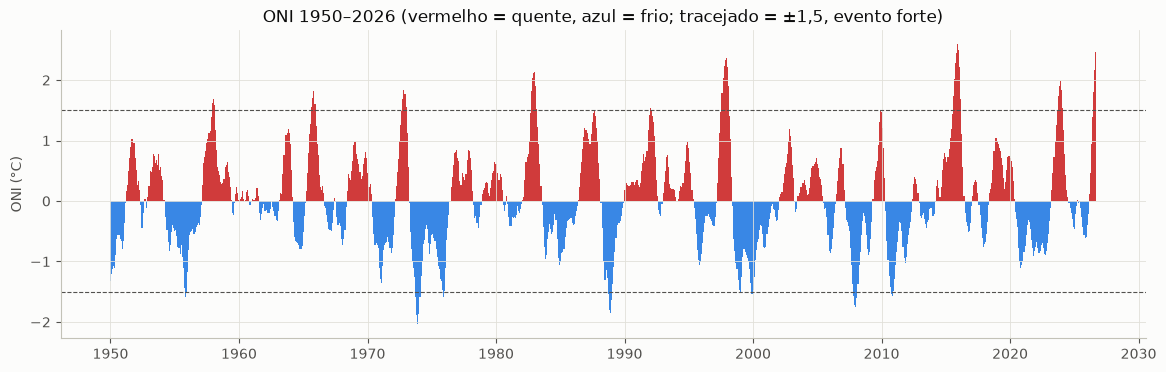

El Niños fortes (ONI de OND–NDJ ≥ 1,5) e a estação afetada:


,ONI_OND_NDJ,quadra_afetada,categoria,dipolo_FMA_quadra
data,,,,
1957,1.62,1958,forte,1.460000
1965,1.82,1966,forte,0.786667
1972,1.84,1973,forte,-0.816667
1982,2.12,1983,muito forte,0.436667
1997,2.37,1998,muito forte,0.190000
2009,1.50,2010,moderado,0.650000
2015,2.59,2016,muito forte,0.013333
2023,1.99,2024,forte,0.073333


In [38]:
oni = pd.read_csv(DADOS / "indices_clima" / "atualizado_2026-11-14" / "oni.ascii.txt", sep=r"\s+")
oni["t"] = oni.YR + oni.groupby("YR").cumcount() / 12
ult = oni.iloc[-1]
print(f"ONI: {len(oni)} trimestres, {oni.YR.min()}–{oni.YR.max()}; último {ult.SEAS} {ult.YR} = {ult.ANOM:+.2f}")
display(descreve(oni.ANOM.rename("ONI")))
aso = oni[oni.SEAS == "ASO"].set_index("YR").ANOM
mx = oni.loc[oni.ANOM.idxmax()]
print(f"ASO 2026 = {aso.iloc[-1]:+.2f}: posição {int(aso.rank(ascending=False, method='min')[aso.index[-1]])} de {len(aso)} trimestres ASO "
      f"desde 1950 (o 2º maior ASO é {aso.drop(aso.index[-1]).max():+.2f}, em {aso.drop(aso.index[-1]).idxmax()}); "
      f"maior que {(oni.ANOM < aso.iloc[-1]).mean():.1%} de todos os trimestres. Recorde de qualquer trimestre: {mx.ANOM:+.2f} ({mx.SEAS} {mx.YR})")
oni_m = M.EN["ONI_ultimo"][1]
print("Rótulo da página: " + f"ONI de ago–out/2026 (ASO): {M._br(oni_m)}, {M._rotulo_oni(oni_m)}. É o maior ago–out desde 1950 "
      "(o recorde de qualquer trimestre é +2,59, em 2015/16).")
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(oni.t, oni.ANOM, width=1 / 12, color=np.where(oni.ANOM >= 0, "#d03b3b", "#3987e5"))
for y in (1.5, -1.5):
    ax.axhline(y, color="#52514e", lw=0.8, ls="--")
ax.set_ylabel("ONI (°C)")
ax.set_title("ONI 1950–2026 (vermelho = quente, azul = frio; tracejado = ±1,5, evento forte)")
plt.show()
print("El Niños fortes (ONI de OND–NDJ ≥ 1,5) e a estação afetada:")
display(M.EVT[M.EVT.ONI_OND_NDJ >= 1.5])

In [39]:
print("Chuva de ago a nov/2026 por UF, como a página mostra (preliminar: IMERG Late/Early contra normal do IMERG Final):")
display(M.ATUAL.reindex(UF_ORDEM)[["chuva_ago_nov2026_mm", "normal_mm", "percentil"]])

Chuva de ago a nov/2026 por UF, como a página mostra (preliminar: IMERG Late/Early contra normal do IMERG Final):


,chuva_ago_nov2026_mm,normal_mm,percentil
UF,,,
MA,61.5,108.4,11.0
PI,56.4,83.1,25.0
CE,5.7,14.3,39.0
RN,9.9,16.3,54.0
PB,14.7,23.6,54.0
PE,26.1,34.0,54.0
AL,46.4,37.6,71.0
SE,59.6,42.6,79.0
BA,136.6,119.1,68.0


**Leitura:**
- **O ONI de ago–out/2026 (ASO) é +2,46, o maior ASO desde 1950** (1º de 77; o 2º é +2,04, em 1997). Ele passa 99,7% de
  todos os 921 trimestres. O recorde de qualquer trimestre é +2,59 (NDJ de 2015/16). A página diz isso e chama o evento
  de "El Niño muito forte".
- **Oito El Niños fortes desde 1957** (ONI de OND–NDJ ≥ 1,5). O de 2009/10 tem ONI de 1,50: o arquivo o chama de
  "moderado", mas a regra ≥ 1,5 o conta como forte (revisão B13). Na era IMERG entram 1998, 2010, 2016 e 2024.
- **A chuva de ago a nov/2026 é a da estação seca:** percentil 11 no MA, 25 no PI, 39 no CE, 54 no RN, na PB e em PE, 68
  na BA, 71 em AL e 79 em SE. É dado preliminar, comparado a uma normal de outro produto, e não prevê a quadra.

## 10. NASA SMAP L4: o solo agora

**Ficha técnica**
- **O que é:** umidade da zona da raiz (0–100 cm) do SMAP L4 (SPL4SMGP v008), um modelo que assimila o radiômetro.
  Grade EASE-Grid 2.0 de 9 km, diária, de 31/03/2015 a 10/11/2026, recorte do Nordeste.
- **O que o protótipo usa:** a média dos 30 dias até a última data, calculada em cada ano de 2015 a 2026
  (`E:/campeonato-nasa/dados/prototipo/smap_janela_30d.nc`, gerado pelo motor). No pixel mais próximo do lugar, a
  posição de 2026 entre os anos (1 = o mais seco): posição ≤ 3 = "seco para a época"; entre as 3 maiores = "úmido para a
  época"; o resto, "normal" (`motor.smap_agora`).
- **Por que a posição e não o valor:** contra 303 estações do CEMADEN, o SMAP L4 acompanha bem a variação (r 0,72), mas
  o nível absoluto é mais alto (0,155 contra 0,080 m³/m³).

In [40]:
import shapely
import xarray as xr

sm = xr.open_dataset(DADOS / "prototipo" / "smap_janela_30d.nc").load()
rz = sm.rz
ano26 = int(rz.ano.max())
print(f"Janela de 30 dias até {sm.attrs['fim']}; anos {int(rz.ano.min())}–{ano26}; grade {rz.sizes['lat']} × {rz.sizes['lon']}")
ult = rz.sel(ano=ano26)
posto = (rz < ult).sum("ano") + 1  # posição de 2026 entre os anos: 1 = o mais seco (empates ficam com a menor posição)
valido = rz.notnull().all("ano")
posto = posto.where(valido)
lo, la = np.meshgrid(rz.lon.values, rz.lat.values)
UFCOD = dict(zip(M.UF.keys(), M.UF.values()))
linhas = []
for _, u in NE.iterrows():
    m = shapely.contains_xy(u.geometry, lo, la) & valido.values
    p = posto.values[m]
    linhas.append({"UF": UFCOD[str(u.codarea)], "pixels": int(m.sum()), "posição mediana (1 = mais seco)": float(np.median(p)),
                   "% pixels entre os 3 mais secos": round(float((p <= 3).mean() * 100), 1),
                   "% pixels entre os 3 mais úmidos": round(float((p >= rz.sizes['ano'] - 2).mean() * 100), 1),
                   "umidade 2026 (mediana, m³/m³)": round(float(np.median(ult.values[m])), 3),
                   "posição da média da UF": int(pd.Series({int(a): float(np.nanmean(rz.sel(ano=a).values[m])) for a in rz.ano.values}).rank()[ano26])})
display(pd.DataFrame(linhas).set_index("UF").reindex(UF_ORDEM))

Janela de 30 dias até 2026-11-10; anos 2015–2026; grade 242 × 151


,pixels,posição mediana (1 = mais seco),% pixels entre os 3 mais secos,% pixels entre os 3 mais úmidos,"umidade 2026 (mediana, m³/m³)",posição da média da UF
UF,,,,,,
MA,4064,2.0,80.3,0.1,0.129,1
PI,3104,2.0,83.4,0.0,0.122,2
CE,1837,5.0,26.7,9.7,0.133,5
RN,650,5.0,20.3,9.4,0.157,4
PB,696,4.0,34.1,1.6,0.164,4
PE,1201,2.0,85.2,0.0,0.120,2
AL,347,2.0,96.3,0.0,0.123,3
SE,266,2.0,98.1,0.0,0.150,1
BA,6970,5.0,36.0,0.6,0.138,3


In [41]:
# o que a página mostra no ponto interno de cada município (pixel mais próximo, como motor.smap_agora)
pix = rz.sel(lat=xr.DataArray(MUN.lat.values, dims="m"), lon=xr.DataArray(MUN.lon.values, dims="m"), method="nearest")
V = pd.DataFrame(pix.values.T, index=MUN.cod.values, columns=rz.ano.values)
n_anos = V.notna().sum(1)
pos = V.rank(axis=1, method="min")[ano26]
cls = np.where(pos <= 3, "seco para a época", np.where(pos >= n_anos - 2, "úmido para a época", "normal para a época"))
SM = pd.DataFrame({"posicao": pos, "classe": np.where(V[ano26].isna() | (n_anos < 5), "sem dado no pixel", cls), "uf": MUN.uf.values},
                  index=MUN.cod.values)
for cod in ["2311306", MUN[MUN.municipio == "Recife"].cod.iloc[0], MUN[MUN.municipio == "Barreiras"].cod.iloc[0]]:
    r = M.smap_agora(float(MUN.set_index("cod").at[cod, "lat"]), float(MUN.set_index("cod").at[cod, "lon"]))
    assert r.get("posto") == (None if np.isnan(SM.at[cod, "posicao"]) else int(SM.at[cod, "posicao"])), (cod, r)
print("Conferido com motor.smap_agora em 3 municípios. Classe que a página mostra no ponto interno, por UF:")
display(pd.crosstab(SM.uf, SM.classe, margins=True, margins_name="NE").reindex(UF_ORDEM + ["NE"]))

Conferido com motor.smap_agora em 3 municípios. Classe que a página mostra no ponto interno, por UF:


classe,normal para a época,seco para a época,sem dado no pixel,úmido para a época,NE
uf,,,,,
MA,66,151,0,0,217
PI,26,198,0,0,224
CE,120,39,0,25,184
RN,132,24,0,11,167
PB,157,63,0,3,223
PE,54,130,1,0,185
AL,5,97,0,0,102
SE,3,72,0,0,75
BA,208,207,0,2,417


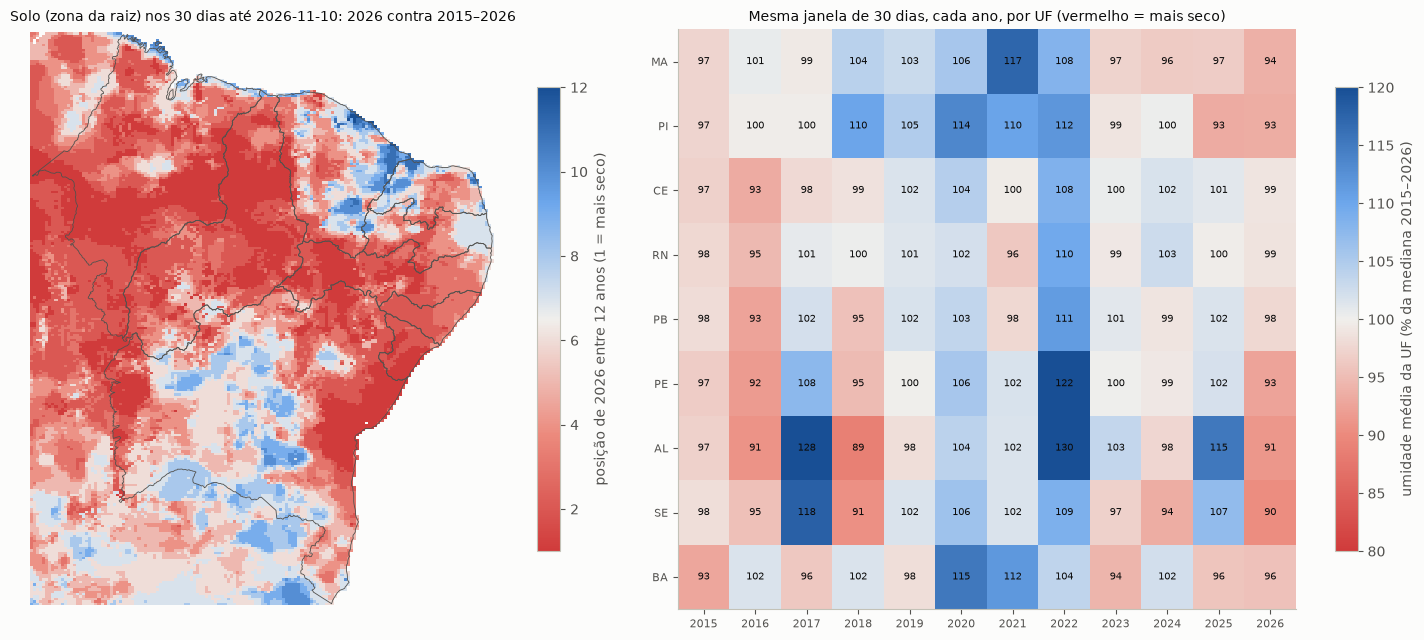

In [42]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
im = axs[0].pcolormesh(rz.lon, rz.lat, posto, cmap=DIV.reversed(), vmin=1, vmax=rz.sizes["ano"], shading="auto")
NE.boundary.plot(ax=axs[0], color="#52514e", lw=0.6)
plt.colorbar(im, ax=axs[0], label=f"posição de 2026 entre {rz.sizes['ano']} anos (1 = mais seco)", shrink=0.8)
axs[0].set_title(f"Solo (zona da raiz) nos 30 dias até {sm.attrs['fim']}: 2026 contra 2015–2026", fontsize=10)
axs[0].set_xlim(*XLIM)
axs[0].set_ylim(*YLIM)
axs[0].set_aspect("equal")
axs[0].set_axis_off()
serie = pd.DataFrame({u: {int(a): float(np.nanmean(rz.sel(ano=a).values[shapely.contains_xy(g_, lo, la) & valido.values])) for a in rz.ano.values}
                      for u, g_ in zip([UFCOD[str(c)] for c in NE.codarea], NE.geometry)})[UF_ORDEM]
rel = (serie / serie.median() * 100).T
im2 = axs[1].imshow(rel.values, cmap=DIV.reversed(), vmin=80, vmax=120, aspect="auto")
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        axs[1].text(j, i, f"{rel.values[i, j]:.0f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
axs[1].set_xticks(range(rel.shape[1]))
axs[1].set_xticklabels(rel.columns, fontsize=8)
axs[1].set_yticks(range(rel.shape[0]))
axs[1].set_yticklabels(rel.index, fontsize=8)
axs[1].grid(False)
plt.colorbar(im2, ax=axs[1], label="umidade média da UF (% da mediana 2015–2026)", shrink=0.8)
axs[1].set_title("Mesma janela de 30 dias, cada ano, por UF (vermelho = mais seco)", fontsize=10)
plt.tight_layout()
plt.show()

**Leitura:**
- **O solo do NE está seco para a época, mas não em toda parte.** Na janela de 30 dias até 10/11/2026:
  - MA, PI, PE, AL e SE têm posição mediana 2 de 12, com 80% a 98% dos pixels entre os 3 anos mais secos;
  - CE, RN e BA têm posição 5; a PB, 4;
  - pela média da UF, 2026 é o mais seco dos 12 anos no MA e em SE, o 2º no PI e em PE, e o 5º no CE.
- **No ponto interno de cada município, a página diz "seco para a época" em 981 municípios**, "normal" em 771 e "úmido"
  em 41. No PI são 198 de 224 secos; em AL, 97 de 102; em SE, 72 de 75. No CE: 39 secos, 120 normais e 25 úmidos.
  Fernando de Noronha fica fora do recorte do SMAP.
- **Em novembro, isso não prevê a estação** (ρ +0,01 entre o solo de novembro e o de fevereiro no CE, na proposta). A
  página mostra a posição como contexto.

## 11. Síntese: o que cada base sustenta no protótipo do Nordeste, e o limite de cada uma

| Base | O que sustenta no protótipo | Números-chave deste notebook | Limite que o cartão precisa dizer |
|---|---|---|---|
| **FAO GAEZ v4** | rótulo de aptidão; decide o guandu, a mandioca e o milheto fora do CE e as culturas sem ZARC no município; a única camada fora do Brasil | mandioca é a mais apta no NE (mediana 48,8); milho, caupi e sorgo ≤ 40 em 953 municípios (todos os 217 do MA) | pixel de 9 km; clima de 1981–2010; **discorda do ZARC** (Spearman de −0,54 a +0,29) |
| **ZARC 2026/27** | janela e risco por cultura e por solo; o 1º decêndio zoneado e o 1º com 20% | 81 portarias (9 culturas × 9 UFs); janela mediana de 3 (feijão de 2ª safra) a 7 decêndios (sorgo); o solo muda a janela em 66% a 87% dos municípios | ciclos com cultivar conferidos só no CE; portarias plurianuais (mandioca, milheto, palma) só no CE, lidas dos PDFs e fora das duas datas da página; a tábua muda a cada safra |
| **GAEZ × ZARC** | situação de cada cultura | mediana de 7 (MA, PI) a 11 (CE) culturas disponíveis; 22 municípios sem nenhuma; o corte pelo GAEZ derrubaria 7.285 pares indicados; a tabela bate com `motor.cardapio` | — |
| **NASA POWER** | assinatura climática do lugar | 396 células para 1.794 municípios; com a Tmax média, a Tmax da estação úmida caiu 6,0 °C no CE | célula de ~55 × 70 km; a definição de "mês úmido" depende da ET0 |
| **Análogos** | peso w e confiança do recibo | 1.080 municípios com w ≥ 0,6; 298 com w < 0,3 (90 no MA e 150 na BA) | lugares dos artigos aproximados; pouca evidência no MA e na BA |
| **Catálogo** | regras do motor e evidência | 29 de 147 cartões com número (T0/T1); nenhuma rotação é T0 | o ganho contra o consórcio de hoje nunca foi medido |
| **IMERG (regime)** | estação típica; avisos fora da quadra e no litoral leste | 1.056 municípios na quadra, 312 no litoral leste, 426 no Cerrado e sul da BA | na faixa até ~20 km da costa leste o IMERG capta só 39–72% da chuva; o aviso vai pela distância à costa (182 municípios) |
| **IMERG (início e El Niño)** | início típico; nível do El Niño no município | início típico de 24/10 a 17/03 (medianas por UF e regime); ZARC × IMERG, Spearman +0,83; alerta em 922 municípios | 3–4 anos de El Niño forte: a diferença no início não se separa do acaso; 2026 é Late (preliminar) e fica fora da série |
| **ONI** | "este ano" | ASO 2026 = +2,46, o maior ASO desde 1950 (recorde de qualquer trimestre: +2,59, em 2015/16) | 2024 foi El Niño forte e quadra normal; o Atlântico de fev–abr ainda é desconhecido |
| **SMAP L4** | o solo agora | "seco para a época" em 981 municípios; 2026 é o mais seco dos 12 anos no MA e em SE | em novembro, não prevê a estação |

**O que este estudo muda no protótipo do NE:**
1. **Tudo é municipal, e o motor já faz assim:** o regime, o início da chuva, o nível do El Niño e a primeira data do ZARC
   mudam muito de um estado para outro (o alerta acende em todo o CE e em nenhum município de AL e SE).
2. **A regra "onde há ZARC, o ZARC decide" vale no NE inteiro:** o GAEZ e o ZARC discordam em 7 de 8 culturas, também
   dentro de cada UF.
3. **A "janela do milho encolheu" sai do texto:** a mudança de 2025/26 para 2026/27 vem da troca do esquema de solo. As
   outras 7 culturas são idênticas nas duas safras.
4. **A estação de 2026 (IMERG Late, preliminar) fica fora da normal e do El Niño, no motor e aqui.** Com ela, 33
   municípios mudariam de nível (955 alertas contra 922). Quando o IMERG Final chegar, ela pode voltar.
5. **Pendências:**
   - conferir nas portarias dos outros 8 estados os grupos de ciclo com cultivar (hoje, só no CE);
   - conferir no SISZARC a vigência das portarias plurianuais do CE (hoje, pela página do MAPA de 05/11/2026);
   - ZARC sintético fora do Brasil e SMAP global, em vez do recorte do Nordeste.